<a href="https://colab.research.google.com/github/SergeiVKalinin/FerroNet_Optimization/blob/main/Legendre%20Try/FerroSim_Legendre_Clean_Standalone_Audited.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FerroSim / Legendre — independently executable, full-analysis v2

**Goal:** optimize terminal ferroic polarization curl using four surrogate-guided methods in an endpoint-constrained, 32-coordinate Legendre control space, then compare optimization efficiency, waveform complexity, uncertainty, algorithm provenance, and transfer across defect disorder.

**Start here:** Modify **only the next cell**. `N_DISORDERS=20` is the default, but **any positive integer** works (including 1). `INITIAL_CONTROLS` is an independent design size; the minimum is **2**, not 32. The default remains 64 for a reasonably informed surrogate. `SEEDS=[0]` or multiple seeds work. All four methods share the same initial controls for each (map, seed).

**QUICK versus FULL:** Both use the real subdivided RK4 FerroSim evaluator; QUICK reduces *model-training effort* but does not substitute a toy objective. FULL uses the original larger proposer-training budget. Computational effort for a full 20-map, three-seed, 32-generation experiment is substantial: 261,120 method-history observations (249,600 distinct physical calls, because the 64 initial controls are shared within each map/seed), excluding validation and transfer.

**Expected budget:** per method and (map, seed): `INITIAL_CONTROLS + 32 * GENERATIONS` recorded observations. Distinct physical evaluations per (map, seed): `INITIAL_CONTROLS + 4*32*GENERATIONS` because initialization is shared. Invalid simulator attempts remain in the histories and count toward the budget.

**Notebook flow:** settings → embedded physical and ML modules → deterministic defect ensemble → physical optimization → audited results → comparison figures → per-disorder control histories/Pareto fronts → uncertainty/provenance → transfer/physical validation → archived exports. Results are saved in a configuration-specific directory. The original notebook under `Legendre/` is untouched.

**Interpretation caveat:** `INITIAL_CONTROLS=2` is a *software regression / very low-data* experiment, not a scientifically adequate DKL training set. It will proceed if at least two physical evaluations are valid. For serious comparative studies use the full default initial design and multiple independent seeds.

In [30]:
# ───── SINGLE EDIT POINT: EXPERIMENT SETTINGS ─────
MODE = 'QUICK'                # 'QUICK' or 'FULL' (both use RK4 FerroSim)
N_DISORDERS = 20              # default 20; any integer >= 1, including 1
SEEDS = [0]                  # distinct integer optimizer seeds; e.g. [0,1,2]
GENERATIONS = 20               # 0 for initialization-only; 32 for full study
INITIAL_CONTROLS = 64        # independent control count, minimum 2; recommended 64

# Optional analyses (affect only postprocessing cost, not physical search histories).
ANALYZE_EACH_DISORDER = True  # save 4-way champion and 4-way Pareto figure for each map
RUN_CROSS_DISORDER_TRANSFER = True   # full N^2 transfer can be expensive; turn off for quick debug
RUN_HIGHER_FIDELITY_VALIDATION = True
VALIDATE_ALL_DISORDERS = False  # False: reference only; True: all disorder champions

from pathlib import Path
import os, sys, math, json, time, hashlib, subprocess, base64, zlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
assert MODE in ('QUICK','FULL'), 'MODE must be QUICK or FULL'
assert isinstance(N_DISORDERS,(int,np.integer)) and N_DISORDERS>=1, 'N_DISORDERS must be >= 1'
assert isinstance(INITIAL_CONTROLS,(int,np.integer)) and INITIAL_CONTROLS>=2, 'INITIAL_CONTROLS must be >= 2'
assert isinstance(GENERATIONS,(int,np.integer)) and GENERATIONS>=0, 'GENERATIONS must be >= 0'
assert len(SEEDS)>=1 and all(isinstance(s,(int,np.integer)) and s>=0 for s in SEEDS), 'SEEDS must be nonnegative integers'
assert len(set(map(int,SEEDS)))==len(SEEDS), 'SEEDS must be unique'

# The physical experiment id changes with any search-relevant configuration field.
# Analysis flags can be changed after a run without invalidating physical histories.
params={'version':'v2','mode':MODE,'disorders':int(N_DISORDERS),'seeds':list(map(int,SEEDS)),
        'generations':int(GENERATIONS),'initial':int(INITIAL_CONTROLS)}
RUN_TAG=hashlib.sha256(json.dumps(params,sort_keys=True).encode()).hexdigest()[:10]
PROJECT=Path.cwd()/'FerroSim_Legendre_Clean_v2'
LIB=PROJECT/'lib'
RUN_ROOT=PROJECT/'experiments'/f"{MODE.lower()}_{N_DISORDERS}maps_{len(SEEDS)}seeds_{GENERATIONS}gen_{INITIAL_CONTROLS}initial_{RUN_TAG}"
MAP_DIR=RUN_ROOT/'maps'; HISTORY_DIR=RUN_ROOT/'histories'; FIG_DIR=RUN_ROOT/'figures'; TABLE_DIR=RUN_ROOT/'tables'
for p in (LIB,MAP_DIR,HISTORY_DIR,FIG_DIR,TABLE_DIR): p.mkdir(parents=True,exist_ok=True)
if str(LIB) not in sys.path: sys.path.insert(0,str(LIB))
print('Physical experiment:',params)
print('Outputs:',RUN_ROOT)
if INITIAL_CONTROLS<32:
    print('NOTE: low-data regression test. DKL is technically trainable with 2 valid observations, but comparisons will be statistically weak.')

Physical experiment: {'version': 'v2', 'mode': 'QUICK', 'disorders': 20, 'seeds': [0], 'generations': 20, 'initial': 64}
Outputs: /content/FerroSim_Legendre_Clean_v2/experiments/quick_20maps_1seeds_20gen_64initial_58ba56541c


## 1. Embedded, readable reference implementation

The next source cells reproduce the previously published standalone Legendre modules, with only one performance change to the FerroSim oracle: **serial JIT processing of waveform batches** instead of Numba's expensive `parallel=True` batch specialization. Individual candidate physics, time discretization, validity guards, RK4 integrator and reward are unchanged. The control sampler also accepts `n=1` to enable isolated representation tests; the actual DKL optimizer still requires a proper initial dataset.

In [31]:
%%writefile FerroSim_Legendre_Clean_v2/lib/representation.py
"""Endpoint-constrained Legendre modal waveform controls for FerroSim.

The *physical* expansion is E(t)/Ec = sum_{n=0}^{35} a_n P_n(2t/T-1).
Four homogeneous endpoint constraints are enforced exactly in coefficient space.
The 32 independent search coordinates x map linearly to the full 36-vector a.
The independent basis is orthonormal in the Legendre L2 metric, ordered from
low to high modal content; numerical x is scaled by 100 Ec (no clipping).
"""
from __future__ import annotations
from functools import lru_cache
import numpy as np
from numpy.polynomial.legendre import legvander, legder, legval
from scipy.linalg import null_space
from scipy.signal import find_peaks

DIM=32
N_COEFFICIENTS=36
DEGREE=35
COEFFICIENT_SCALE=100.0
TIME=np.linspace(0.,4.,1200)[:950]
DRIVE_TIME=TIME[:900]

# Normalize modes so their (time averaged) L2 norms are one.
MODAL_SCALE=np.sqrt(2*np.arange(N_COEFFICIENTS)+1.)
n=np.arange(N_COEFFICIENTS,dtype=float)
# P_n(+1)=1, P_n(-1)=(-1)^n, P'_n(+1)=n(n+1)/2,
# P'_n(-1)=(-1)^(n+1)n(n+1)/2.
CONSTRAINT=np.vstack([MODAL_SCALE,(-1.)**n*MODAL_SCALE,
                     (n*(n+1)/2)*MODAL_SCALE,
                     (-1.)**(n+1)*(n*(n+1)/2)*MODAL_SCALE])
_RAW=null_space(CONSTRAINT) # columns span allowed normalized modal space
# Make an order-aware orthonormal basis by projecting lower Legendre modes first.
COLUMNS=[]
for j in range(N_COEFFICIENTS):
    v=_RAW@_RAW[j,:]
    for q in COLUMNS: v-=q*np.dot(q,v)
    nv=np.linalg.norm(v)
    if nv>1e-8: COLUMNS.append(v/nv)
    if len(COLUMNS)==DIM: break
if len(COLUMNS)!=DIM: raise RuntimeError('Endpoint nullspace dimension mismatch')
Q=np.column_stack(COLUMNS) # 36 x 32 in normalized modal basis
PHYSICAL_COEFFICIENT_MAP=COEFFICIENT_SCALE*MODAL_SCALE[:,None]*Q

@lru_cache(maxsize=12)
def basis(n=900):
    s=np.linspace(-1.,1.,int(n))
    return legvander(s,DEGREE)@PHYSICAL_COEFFICIENT_MAP

def fields(x,n=900):
    a=np.asarray(x,dtype=float)
    if a.shape[-1]!=DIM: raise ValueError(f'Expected {DIM} free coordinates')
    return a@basis(int(n)).T

def full_coefficients(x):
    a=np.asarray(x,dtype=float)
    return a@PHYSICAL_COEFFICIENT_MAP.T

def to_coordinates(curve):
    """Least-squares projection of a sampled physical field into the 32D space."""
    w=np.asarray(curve,dtype=float)
    return np.linalg.lstsq(basis(len(w)),w,rcond=1e-10)[0]

def complexity(x,n=4097):
    z=np.atleast_2d(np.asarray(x,dtype=float)); w=fields(z,n=n)
    out={k:np.zeros(len(z),dtype=np.int32) for k in ('turns','raw_turns','turns_1pct','turns_5pct')}
    for i,v in enumerate(w):
        span=float(np.ptp(v))
        if not np.isfinite(span):
            for k in out: out[k][i]=-1
            continue
        if span==0: continue
        for key,frac in [('raw_turns',0.),('turns_1pct',.01),('turns',.02),('turns_5pct',.05)]:
            out[key][i]=len(find_peaks(v,prominence=frac*span)[0])+len(find_peaks(-v,prominence=frac*span)[0])
    out['peak_ec']=np.max(np.abs(w),axis=1)
    out['rms_ec']=np.sqrt(np.mean(w*w,axis=1))
    return out

def sample_prior(rng,n):
    """Broad unbounded amplitudes and mixed smooth/oscillatory waveform priors."""
    n=int(n); u=np.linspace(0,1,160)
    shapes=[]
    for _ in range(n):
        mode=int(rng.integers(0,4))
        if mode==0:
            c=rng.uniform(.15,.85); width=np.exp(rng.normal(np.log(.2),.5))
            w=np.exp(-.5*((u-c)/width)**2)
        elif mode==1:
            modes=np.arange(1,int(rng.integers(2,8))+1)
            w=np.sin(np.pi*u[:,None]*modes).dot(rng.normal(size=len(modes))/modes**1.5)
        elif mode==2:
            modes=np.arange(1,11)
            w=np.sin(np.pi*u[:,None]*modes).dot(rng.normal(size=len(modes))/modes**2)
        else:
            w=np.sin(np.pi*u)*rng.normal()+.5*np.sin(3*np.pi*u)*rng.normal()+.3*np.sin(5*np.pi*u)*rng.normal()
        w=w*np.sin(np.pi*u)**2 # enforce physical endpoint field and slope
        w=w/max(np.max(np.abs(w)),1e-14)
        shapes.append(to_coordinates(w))
    amp=np.exp(rng.normal(np.log(30.),2.2,size=n))
    return np.asarray(shapes)*amp[:,None]

def initial_design(seed,n=64):
    if not isinstance(n,(int,np.integer)) or n < 1: raise ValueError('n must be a positive integer')
    rng=np.random.default_rng(int(seed)); u=np.linspace(0.,1.,160)
    rows=[np.zeros(DIM)]
    shape=np.sin(np.pi*u)**2
    unit=to_coordinates(shape)
    for amp in (.1,1.,3.,10.,30.,100.,300.,1000.):
        for sign in (-1.,1.): rows.append(sign*amp*unit)
    for cycles in (1,2,4):
        for amp in (1.,10.,100.,1000.):
            rows.append(amp*to_coordinates(np.sin(np.pi*u)**2*np.sin(2*np.pi*cycles*u)))
    if n>len(rows):
        rows.extend(list(sample_prior(rng,n-len(rows))))
    return np.asarray(rows[:n],dtype=float)

def specification():
    return {'representation':'Legendre polynomial modal expansion',
            'degree':35,'total_coefficients':36,'free_coefficients':32,
            'basis':'P_n(2t/T-1)','endpoint_constraints':'E(-1)=E(1)=Eprime(-1)=Eprime(1)=0',
            'coordinate_map':'orthonormal nullspace in Legendre L2 metric, ordered low-to-high',
            'coordinate_scale_Ec':COEFFICIENT_SCALE,
            'amplitude_bound':None,'absolute_slew_bound':None,
            'drive_samples':900,'zero_hold_samples':50,
            'dt':float(TIME[1]-TIME[0]),
            'complexity':'prominent interior waveform extrema (2 percent peak-to-peak)',
            'sensitivity_prominences':[.01,.05],
            'complexity_grid_samples':4097}

if __name__=='__main__':
    rng=np.random.default_rng(11); x=rng.normal(size=(12,DIM))
    a=full_coefficients(x)
    assert np.max(np.abs(a@np.vstack([np.ones(36),(-1.)**np.arange(36),
        np.arange(36)*(np.arange(36)+1)/2,
        (-1.)**(np.arange(36)+1)*np.arange(36)*(np.arange(36)+1)/2]).T))<1e-6
    assert np.allclose(fields(x),np.array([legval(np.linspace(-1,1,900),v) for v in a]))
    print('Legendre render and boundary constraints OK')


Overwriting FerroSim_Legendre_Clean_v2/lib/representation.py


In [32]:
%%writefile FerroSim_Legendre_Clean_v2/lib/oracle.py
"""Accelerated deterministic FerroSim GLD evaluator.

Physics: native rama_dev_updated@5eb258e, gamma=1, tetragonal, k=100,
dep_alpha=.3, finite-grid interactions with fixed /4 neighbor normalization.
Default integration is subdivided RK4, NOT the native first-order Euler method.
No field-amplitude bound or state clipping is imposed in RK4. The native
calDeriv clipping guard |P|=10 is explicitly diagnosed if ever crossed.
Native periodic central-difference curl and an interior diagnostic are returned.
"""
from __future__ import annotations
import os
import math
from pathlib import Path
import numpy as np
os.environ.setdefault("NUMBA_NUM_THREADS", "2")
from numba import njit, prange

N = 20
ALPHA1, ALPHA2, ALPHA3 = -1.6, 12.2, 40.0
COUPLING, DEP_ALPHA = 100.0, 0.3
EC = (-2.0 / 3.0) * ALPHA1 * np.sqrt(abs(-ALPHA1/(3.0*ALPHA2)))
TIME = np.linspace(0.0, 4.0, 1200)[:950]
DT = float(TIME[1]-TIME[0])
SOURCE_COMMIT = "5eb258e2a47d10b3d9bdb9e94dd9879b8410024c"
_LOCAL_DEFECT_PATH = Path(os.environ.get("FERROSIM_DEFECT_PATH", str(Path(__file__).with_name("defect_list_seed.npy"))))
DEFAULT_DEFECT_PATH = (_LOCAL_DEFECT_PATH if _LOCAL_DEFECT_PATH.exists()
                       else Path(__file__).resolve().parents[1]/"GA-DKL/defect_list_seed.npy")
_DEFECTS = None


def default_defects():
    global _DEFECTS
    if _DEFECTS is None:
        _DEFECTS = np.load(DEFAULT_DEFECT_PATH, allow_pickle=False).astype(np.float64).reshape(N,N,2)
    return _DEFECTS.copy()


@njit(cache=True)
def _rhs(p, ex, defects, coupling, dep_alpha, native_clip):
    n = p.shape[1]
    out = np.empty_like(p)
    mx, my = 0.0, 0.0
    for i in range(n):
        for j in range(n):
            mx += p[0,i,j]
            my += p[1,i,j]
    mx /= n*n
    my /= n*n
    for i in range(n):
        for j in range(n):
            x, y = p[0,i,j], p[1,i,j]
            if native_clip:
                x = min(10.,max(-10.,x))
                y = min(10.,max(-10.,y))
            sx, sy = 0.0, 0.0
            # Same finite-grid graph as native knn_search(r=1.1).
            if i>0:
                sx += p[0,i-1,j]; sy += p[1,i-1,j]
            if j>0:
                sx += p[0,i,j-1]; sy += p[1,i,j-1]
            if j<n-1:
                sx += p[0,i,j+1]; sy += p[1,i,j+1]
            if i<n-1:
                sx += p[0,i+1,j]; sy += p[1,i+1,j]
            out[0,i,j] = -(2*ALPHA1*x + 4*ALPHA2*x*x*x + 2*ALPHA3*y*y*x
                           + coupling*(x-sx/4.) - ex + dep_alpha*mx - defects[i,j,0])
            out[1,i,j] = -(2*ALPHA1*y + 4*ALPHA2*y*y*y + 2*ALPHA3*x*x*y
                           + coupling*(y-sy/4.) + dep_alpha*my - defects[i,j,1])
    return out


@njit(cache=True)
def _maxabs(p):
    q = 0.0
    for k in range(p.size):
        v = abs(p.flat[k])
        if not np.isfinite(v):
            return np.inf
        if v>q:
            q=v
    return q


@njit(cache=True)
def _curl(p):
    n=p.shape[1]
    c=np.empty((n,n),dtype=np.float64)
    total, interior = 0.,0.
    for i in range(n):
        for j in range(n):
            v=.5*(p[1,(i+1)%n,j]-p[1,(i-1)%n,j]-p[0,i,(j+1)%n]+p[0,i,(j-1)%n])
            c[i,j]=v
            total+=abs(v)
            if 0<i<n-1 and 0<j<n-1:
                interior+=abs(v)
    return total,interior,c


@njit(cache=True)
def _integrate(field, defects, initial, fidelity, method, history, coupling, dep_alpha, max_substeps):
    """method 0: native-style Euler, method 1: curvature-subdivided RK4."""
    p=initial.copy()
    steps=field.size
    n=p.shape[1]
    hst=np.full((2,steps,n,n),np.nan,dtype=np.float64) if history else np.empty((2,1,n,n),dtype=np.float64)
    hst[:,0,:,:]=p
    peak=_maxabs(p)
    defects_peak=0.
    for q in range(defects.size):
        defects_peak=max(defects_peak,abs(defects.flat[q]))
    rhs_calls=0
    subdivisions=0
    guard_exceeded=peak>10.
    status=0
    for t in range(1,steps):
        e0,e1=field[t-1]*EC,field[t]*EC
        if method==0:
            count=fidelity
        else:
            # A conservative estimate of the local Jacobian row-sum magnitude.
            # The forcing equilibrium scale anticipates sharp field increases.
            pbound=max(_maxabs(p),((max(abs(e0),abs(e1))+defects_peak+10.)/(4*ALPHA2))**(1/3)+.3)
            curvature=(12*ALPHA2+6*abs(ALPHA3))*pbound*pbound+2*coupling+abs(2*ALPHA1)+dep_alpha
            needed=DT*curvature*fidelity
            # Check in floating point before integer conversion: finite but huge
            # requested fields can otherwise overflow the subdivision counter.
            if not np.isfinite(needed) or needed>max_substeps:
                status=2
                break
            count=max(2*fidelity,int(math.ceil(needed)))
        if count>max_substeps:
            status=2
            break
        h=DT/count
        for sub in range(count):
            f0=sub/count
            f1=(sub+1)/count
            if method==0:
                # At fidelity=1 this exactly uses field[t], as native calcODE does.
                ex=e0+(e1-e0)*f1
                p=p+h*_rhs(p,ex,defects,coupling,dep_alpha,True)
                rhs_calls+=1
            else:
                ea=e0+(e1-e0)*f0
                eb=e0+(e1-e0)*f1
                em=.5*(ea+eb)
                k1=_rhs(p,ea,defects,coupling,dep_alpha,False)
                k2=_rhs(p+.5*h*k1,em,defects,coupling,dep_alpha,False)
                k3=_rhs(p+.5*h*k2,em,defects,coupling,dep_alpha,False)
                k4=_rhs(p+h*k3,eb,defects,coupling,dep_alpha,False)
                p=p+(h/6.)*(k1+2*k2+2*k3+k4)
                rhs_calls+=4
            pm=_maxabs(p)
            if not np.isfinite(pm):
                status=1
                break
            peak=max(peak,pm)
            guard_exceeded=guard_exceeded or pm>10.
        subdivisions+=count
        if history:
            hst[:,t,:,:]=p
        if status:
            break
    if not history:
        hst[:,0,:,:]=p
    if status:
        return np.nan,np.nan,p,peak,guard_exceeded,status,rhs_calls,subdivisions,hst
    reward,interior,_=_curl(p)
    return reward,interior,p,peak,guard_exceeded,status,rhs_calls,subdivisions,hst


@njit(cache=True)
def _batch(fields,defects,initial,fidelity,method,coupling,dep_alpha,max_substeps):
    batch=fields.shape[0]
    n=initial.shape[1]
    reward=np.empty(batch); interior=np.empty(batch); peak=np.empty(batch)
    final=np.empty((batch,2,n,n)); guards=np.empty(batch,dtype=np.bool_)
    status=np.empty(batch,dtype=np.int64); rhs=np.empty(batch,dtype=np.int64); subdivisions=np.empty(batch,dtype=np.int64)
    for q in range(batch):
        r,j,p,m,g,s,nrhs,nsub,_=_integrate(fields[q],defects,initial,fidelity,method,False,coupling,dep_alpha,max_substeps)
        reward[q]=r; interior[q]=j; final[q]=p; peak[q]=m
        guards[q]=g; status[q]=s; rhs[q]=nrhs; subdivisions[q]=nsub
    return reward,interior,final,peak,guards,status,rhs,subdivisions


def evaluate_fields(fields_ec, fidelity=1, return_history=False, method="rk4", defects_ec=None,
                    initial_p=None, coupling=COUPLING, dep_alpha=DEP_ALPHA, max_substeps=100000):
    """Evaluate x-only waveforms with a fresh state for every candidate.

    Parameters
    ----------
    fields_ec : (batch,900) or (batch,950), or a single corresponding vector.
        Actual native-interface field E/Ec, WITHOUT normalization or amplitude cap.
        With 900 samples, 50 repeats of the final field are appended.
    fidelity : integer >=1
        Multiplies RK4 temporal resolution. Legacy Euler uses this many substeps.
    return_history : bool
        Add P_history shape (batch,2,950,n,n), mean_P and curl_history.
    method : "rk4" (default) or "legacy_euler"
        RK4 uses linear field interpolation and no state clipping.
    initial_p : optional (n,n,2) or (2,n,n), default zeros on20x20.
    defects_ec : optional (n*n,2) or (n,n,2), default published19-site array.

    status=0 success; 1 nonfinite integration; 2 subdivision resource limit.
    native_guard_exceeded flags |P|>10 without clipping or discarding the result.
    """
    arr=np.asarray(fields_ec,dtype=np.float64)
    if arr.ndim==1:
        arr=arr[None,:]
    if arr.ndim!=2 or arr.shape[1] not in (900,950):
        raise ValueError("Expected (batch,900) or (batch,950) native E/Ec values")
    if not np.isfinite(arr).all():
        raise ValueError("All supplied fields must be finite")
    if arr.shape[1]==900:
        arr=np.concatenate((arr,np.repeat(arr[:,-1:],50,axis=1)),axis=1)
    arr=np.ascontiguousarray(arr)
    if int(fidelity)!=fidelity or fidelity<1:
        raise ValueError("fidelity must be an integer >=1")
    if int(max_substeps)!=max_substeps or max_substeps<1:
        raise ValueError("max_substeps must be an integer >=1")
    if method not in ("rk4","legacy_euler"):
        raise ValueError("Unknown integration method")
    method_id=int(method=="rk4")
    if initial_p is None:
        initial=np.zeros((2,N,N),dtype=np.float64)
    else:
        initial=np.asarray(initial_p,dtype=np.float64)
        if initial.shape[-1]==2 and initial.shape[0]!=2:
            initial=initial.transpose(2,0,1)
        if initial.ndim!=3 or initial.shape[0]!=2 or initial.shape[1]!=initial.shape[2]:
            raise ValueError("Invalid initial polarization shape")
        initial=np.ascontiguousarray(initial)
    n=initial.shape[1]
    defects=default_defects() if defects_ec is None else np.asarray(defects_ec,dtype=np.float64).reshape(n,n,2)
    if defects.shape!=(n,n,2):
        raise ValueError("Defect grid must match initial polarization grid")
    if not np.isfinite(initial).all() or not np.isfinite(defects).all():
        raise ValueError("Initial polarization and defects must be finite")
    defects=np.ascontiguousarray(defects*EC)
    if return_history:
        out=[_integrate(x,defects,initial,int(fidelity),method_id,True,float(coupling),float(dep_alpha),int(max_substeps)) for x in arr]
        r,j,p,m,g,s,nrhs,nsub,hist=map(np.asarray,zip(*out))
    else:
        r,j,p,m,g,s,nrhs,nsub=_batch(arr,defects,initial,int(fidelity),method_id,float(coupling),float(dep_alpha),int(max_substeps))
    result={"reward":r,"curl":r,"interior":j,"final_P":p,"max_abs_P":m,
            "native_guard_exceeded":g,"status":s,"valid":(s==0)&np.isfinite(r),
            "rhs_calls":nrhs,"substeps":nsub,"field_peak_ec":np.max(np.abs(arr),axis=1),
            "fidelity":int(fidelity),"method":method}
    if return_history:
        result["P_history"]=hist
        result["mean_P"]=hist.mean(axis=(3,4))
        ch=np.empty((arr.shape[0],arr.shape[1]))
        ih=np.empty_like(ch)
        for b in range(arr.shape[0]):
            for t in range(arr.shape[1]):
                ch[b,t],ih[b,t],_=_curl(hist[b,:,t])
        result["curl_history"]=ch
        result["interior_history"]=ih
        result["time"]=TIME.copy()
        result["field_ec"]=arr
    return result


def curl_field(p):
    """Native periodic centered curl diagnostic for P shaped (2,n,n)."""
    return _curl(np.asarray(p,dtype=np.float64))[2]


Overwriting FerroSim_Legendre_Clean_v2/lib/oracle.py


In [33]:
%%writefile FerroSim_Legendre_Clean_v2/lib/surrogate.py
"""A jointly trained neural feature map + exact Gaussian process (DKL).

The kernel acts on an 8-dimensional neural embedding and a small fixed
log-amplitude coordinate. Marginal likelihood jointly trains the embedding,
RBF length scales, GP signal variance and observation noise. No simulator
derivatives or held-out true rewards enter acquisition evaluation.
"""
from __future__ import annotations
import math
import time
import numpy as np
import torch
from torch import nn
from representation import basis, DIM


class Surrogate(nn.Module):
    def __init__(self, seed=0, beta=2.0):
        super().__init__()
        self.seed = int(seed)
        self.beta = float(beta)
        self.register_buffer('render_basis', torch.as_tensor(basis(96).T, dtype=torch.float64))
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(self.seed)
            self.feature = nn.Sequential(nn.Linear(96, 64), nn.SiLU(),
                                         nn.Linear(64, 32), nn.SiLU(),
                                         nn.Linear(32, 8)).double()
        self.log_length = nn.Parameter(torch.zeros(9, dtype=torch.float64))
        self.log_signal = nn.Parameter(torch.tensor(0., dtype=torch.float64))
        self.log_noise = nn.Parameter(torch.tensor(-3.5, dtype=torch.float64))
        self.mean = nn.Parameter(torch.tensor(0., dtype=torch.float64))
        self.optimizer = torch.optim.Adam(self.parameters(), lr=.008)
        self.y_center = 0.0
        self.y_scale = 1.0
        self.fit_history = []
        self.last_diagnostics = {}
        self.train_x = self.train_y = None
        self.cached_z = self.cached_L = self.cached_alpha = None

    def embed(self, x):
        x = x.to(dtype=torch.float64)
        w = x @ self.render_basis
        inp = torch.asinh(w)
        latent = self.feature(inp)
        # A non-learned amplitude coordinate mitigates feature collapse for
        # large unseen amplitudes without bounding either input or output.
        log_rms_squared = torch.logsumexp(
            2.0 * torch.log(w.abs().clamp_min(torch.finfo(w.dtype).tiny)),
            dim=1, keepdim=True) - math.log(w.shape[1])
        amp = .15 * torch.nn.functional.softplus(log_rms_squared)
        return torch.cat((latent, amp), dim=1)

    def kernel(self, za, zb):
        ls = torch.exp(self.log_length.clamp(-5., 5.))
        a, b = za / ls, zb / ls
        d2 = (a.square().sum(1)[:, None] + b.square().sum(1)[None, :]
              - 2.0 * a @ b.T).clamp_min(0.0)
        signal = torch.exp(2.0 * self.log_signal.clamp(-5., 5.))
        return signal * torch.exp(-.5 * d2)

    def _factor(self, z):
        k = self.kernel(z, z)
        noise = torch.exp(2.0 * self.log_noise.clamp(-8., 1.))
        eye = torch.eye(len(z), dtype=torch.float64, device=z.device)
        for jitter in (1e-7, 1e-6, 1e-5, 1e-4):
            L, info = torch.linalg.cholesky_ex(k + (noise + jitter) * eye)
            if not bool(torch.any(info)):
                return L, jitter
        raise RuntimeError('DKL covariance failed Cholesky after jitter retries')

    def fit(self, x, y, steps=45):
        t0 = time.perf_counter()
        a, b = np.asarray(x, dtype=np.float64), np.asarray(y, dtype=np.float64)
        keep = np.isfinite(a).all(axis=1) & np.isfinite(b)
        a, b = a[keep], b[keep]
        if len(b) < 2:
            raise ValueError('At least two valid observations are needed')
        self.train_x = torch.as_tensor(a.copy(), dtype=torch.float64)
        self.y_center = float(np.mean(b))
        self.y_scale = max(float(np.std(b)), 1e-3)
        self.train_y = torch.as_tensor((b - self.y_center) / self.y_scale, dtype=torch.float64)
        for p in self.parameters():
            p.requires_grad_(True)
        self.train()
        initial_feature = torch.cat([p.detach().flatten().clone() for p in self.feature.parameters()])
        losses, jitter = [], 1e-7
        for _ in range(int(steps)):
            self.optimizer.zero_grad(set_to_none=True)
            z = self.embed(self.train_x)
            L, jitter = self._factor(z)
            centered = self.train_y - self.mean
            alpha = torch.cholesky_solve(centered[:, None], L)
            nll = (.5 * (centered[:, None] * alpha).sum()
                   + torch.log(torch.diagonal(L)).sum()
                   + .5 * len(b) * math.log(2.0 * math.pi)) / len(b)
            regularizer = 1e-4 * sum(p.square().mean() for p in self.feature.parameters())
            loss = nll + regularizer
            if not torch.isfinite(loss):
                raise FloatingPointError('Nonfinite DKL marginal likelihood')
            loss.backward()
            torch.nn.utils.clip_grad_norm_(self.parameters(), 10.0)
            self.optimizer.step()
            losses.append(float(loss.detach()))
        self.eval()
        with torch.no_grad():
            self.cached_z = self.embed(self.train_x).detach()
            self.cached_L, jitter = self._factor(self.cached_z)
            self.cached_L = self.cached_L.detach()
            self.cached_alpha = torch.cholesky_solve(
                (self.train_y - self.mean)[:, None], self.cached_L).detach()
            mu, _ = self.posterior(self.train_x)
            rmse = float(torch.sqrt(torch.mean((mu - self.train_y).square())) * self.y_scale)
            final_feature = torch.cat([p.detach().flatten() for p in self.feature.parameters()])
        for p in self.parameters():
            p.requires_grad_(False)
        diagnostics = {
            'n': int(len(b)), 'steps': int(steps), 'initial_nll_per_point': losses[0] if losses else None,
            'final_nll_per_point': losses[-1] if losses else None, 'training_rmse_curl': rmse,
            'feature_weight_change_l2': float(torch.linalg.vector_norm(final_feature - initial_feature)),
            'noise_std_standardized': float(torch.exp(self.log_noise).detach()),
            'signal_std_standardized': float(torch.exp(self.log_signal).detach()),
            'length_scales': torch.exp(self.log_length).detach().tolist(),
            'y_center': self.y_center, 'y_scale': self.y_scale, 'jitter': jitter,
            'elapsed_seconds': time.perf_counter() - t0,
        }
        self.last_diagnostics = diagnostics
        self.fit_history.append(diagnostics)
        return diagnostics

    def posterior(self, x):
        if self.cached_L is None:
            raise RuntimeError('Fit the surrogate before predicting')
        if not isinstance(x, torch.Tensor):
            x = torch.as_tensor(np.asarray(x), dtype=torch.float64)
        z = self.embed(x)
        k = self.kernel(z, self.cached_z)
        mu = self.mean + (k @ self.cached_alpha).squeeze(-1)
        v = torch.linalg.solve_triangular(self.cached_L, k.T, upper=False)
        signal = torch.exp(2.0 * self.log_signal.clamp(-5., 5.))
        variance = (signal - v.square().sum(0)).clamp_min(1e-9)
        return mu, variance.sqrt()

    def acquisition(self, x):
        """Differentiable UCB in standardized reward units."""
        mu, sigma = self.posterior(x)
        return mu + self.beta * sigma

    def predict(self, x):
        a = np.asarray(x, dtype=np.float64)
        means, deviations = [], []
        with torch.no_grad():
            for part in np.array_split(a, max(1, int(np.ceil(len(a) / 512)))):
                mu, sigma = self.posterior(torch.as_tensor(part, dtype=torch.float64))
                means.append(mu.numpy() * self.y_scale + self.y_center)
                deviations.append(sigma.numpy() * self.y_scale)
        return np.concatenate(means), np.concatenate(deviations)


Overwriting FerroSim_Legendre_Clean_v2/lib/surrogate.py


In [34]:
%%writefile FerroSim_Legendre_Clean_v2/lib/gflownet.py
"""Continuous GFlowNet proposal distribution for unbounded spline coefficients.

The GFlowNet constructs the coordinates in a fixed order.  Its forward policy
is an autoregressive mixture of Student-t distributions.  The reverse action
uniquely removes the most recently assigned coordinate, so log P_B = 0.

Training minimizes the genuine trajectory-balance residual

    log Z + log P_F(x) - log R(x).

On an unbounded continuous domain a positive bounded score alone is not an
integrable target density.  We therefore define a proper reference measure:

    R(x) = prod_j StudentT_4(x_j; 0, reference_scale)
           * exp(beta * tanh((acquisition(x) - center) / utility_scale)).

The reference is a sampling prior, not an amplitude constraint.  Every real
coefficient remains in its support.  The bounded monotone utility makes this
target normalizable for any finite acquisition function.  Its parameters are
returned in diagnostics.  No coefficient clipping or bounded output activation
is used.  Proposal scales may adapt between generations to observed data.

This is a compact benchmark implementation, not an upstream GFlowNet package.
"""
from __future__ import annotations

import math
import time
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F


class _MaskedLinear(nn.Linear):
    def __init__(self, in_features: int, out_features: int, mask: np.ndarray):
        super().__init__(in_features, out_features)
        self.register_buffer("mask", torch.as_tensor(mask, dtype=torch.float32))

    def forward(self, x):
        return F.linear(x, self.weight * self.mask, self.bias)


class _AutoregressiveStudentPolicy(nn.Module):
    """MADE-style exact autoregressive conditional densities."""

    def __init__(self, dim: int, hidden: int = 96, mixtures: int = 3, df: float = 4.0):
        super().__init__()
        self.dim = int(dim)
        self.mixtures = int(mixtures)
        self.df = float(df)
        input_degree = np.arange(1, dim + 1)
        if dim > 1:
            hidden_degree = 1 + np.arange(hidden) % (dim - 1)
        else:
            hidden_degree = np.zeros(hidden, dtype=int)
        output_degree = np.repeat(input_degree, 3 * mixtures)
        self.first = _MaskedLinear(dim, hidden, input_degree[None, :] <= hidden_degree[:, None])
        self.second = _MaskedLinear(hidden, hidden, hidden_degree[None, :] <= hidden_degree[:, None])
        self.output = _MaskedLinear(hidden, dim * mixtures * 3,
                                    hidden_degree[None, :] < output_degree[:, None])
        # Start close to the heavy-tailed reference while allowing components
        # to specialize under reward-conditioned training.
        nn.init.zeros_(self.output.weight)
        nn.init.zeros_(self.output.bias)
        with torch.no_grad():
            bias = self.output.bias.view(dim, 3, mixtures)
            bias[:, 1, :] = torch.linspace(-0.35, 0.35, mixtures)[None, :]

    def parameters_for(self, x, reference_scale: float):
        # A stable invertible input transform, not a coefficient bound.
        h = torch.asinh(x / reference_scale)
        h = F.silu(self.first(h))
        h = F.silu(self.second(h))
        out = self.output(h).view(-1, self.dim, 3, self.mixtures)
        logits = out[:, :, 0, :]
        locations = reference_scale * out[:, :, 1, :]
        # Bounds on the learned conditional *scale* do not bound Student-t
        # actions or their unconstrained locations.  They avoid a singular fit.
        log_scales = math.log(reference_scale) + out[:, :, 2, :].clamp(-4.0, 4.0)
        return logits, locations, log_scales

    def conditional_log_prob(self, x, reference_scale: float):
        logits, locations, log_scales = self.parameters_for(x, reference_scale)
        z = (x[:, :, None] - locations) * torch.exp(-log_scales)
        nu = self.df
        norm = math.lgamma((nu + 1) / 2) - math.lgamma(nu / 2) - 0.5 * math.log(nu * math.pi)
        log_component = norm - log_scales - ((nu + 1) / 2) * torch.log1p(z.square() / nu)
        return torch.logsumexp(F.log_softmax(logits, dim=-1) + log_component, dim=-1)

    def log_prob(self, x, reference_scale: float):
        return self.conditional_log_prob(x, reference_scale).sum(dim=-1)

    @torch.no_grad()
    def sample(self, n: int, reference_scale: float, rng: np.random.Generator):
        device = next(self.parameters()).device
        x = torch.zeros((n, self.dim), device=device, dtype=torch.float32)
        for j in range(self.dim):
            logits, locations, log_scales = self.parameters_for(x, reference_scale)
            probabilities = torch.softmax(logits[:, j, :], dim=-1).cpu().numpy()
            cumulative = np.cumsum(probabilities, axis=1)
            component = np.sum(rng.random(n)[:, None] > cumulative, axis=1)
            component = np.minimum(component, self.mixtures - 1)
            rows = np.arange(n)
            loc = locations[:, j, :].cpu().numpy()[rows, component]
            scale = np.exp(log_scales[:, j, :].cpu().numpy()[rows, component])
            action = loc + scale * rng.standard_t(self.df, size=n)
            x[:, j] = torch.as_tensor(action, dtype=torch.float32, device=device)
        return x


class GFlowNetProposer:
    """Train a reward-density GFlowNet, then sample coefficient proposals.

    Parameters/returns use the caller's normalized coefficient coordinates,
    e.g. native E/Ec coefficients divided by 100.  The class never applies a
    physical field amplitude cap.

    ``fit`` accepts either a callable ``reward_fn(torch_X)`` or an object with
    ``.acquisition(torch_X)``.  The callable should return one acquisition score
    per row.  True observed labels are optional and are used only to select
    replay examples; all trajectory-balance targets use the current callable.
    """

    def __init__(self, dim: int, seed: int = 0, hidden: int = 96,
                 mixtures: int = 3, beta: float = 7.0,
                 reference_scale: float = 1.0, learning_rate: float = 2e-3,
                 device: str = "cpu"):
        if dim < 1 or reference_scale <= 0:
            raise ValueError("dim and reference_scale must be positive")
        self.dim = int(dim)
        self.seed = int(seed)
        self.rng = np.random.default_rng(seed)
        self.device = torch.device(device)
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(seed)
            self.policy = _AutoregressiveStudentPolicy(dim, hidden, mixtures).to(self.device)
        self.logZ = nn.Parameter(torch.zeros((), device=self.device))
        self.optimizer = torch.optim.Adam([
            {"params": list(self.policy.parameters()), "lr": learning_rate},
            {"params": [self.logZ], "lr": 10*learning_rate},
        ])
        self.reference_scale = float(reference_scale)
        self.beta = float(beta)
        self.utility_center = 0.0
        self.utility_scale = 1.0
        self.last_proposals = np.empty((0, dim), dtype=np.float32)
        self.last_diagnostics = {}
        self.fit_history = []

    def _tensor(self, x):
        if isinstance(x, torch.Tensor):
            return x.detach().to(device=self.device, dtype=torch.float32)
        return torch.as_tensor(np.asarray(x), dtype=torch.float32, device=self.device)

    def _reference_samples(self, n):
        x = self.reference_scale * self.rng.standard_t(4.0, size=(n, self.dim))
        return torch.as_tensor(x, dtype=torch.float32, device=self.device)

    def _reference_log_prob(self, x):
        nu = 4.0
        s = self.reference_scale
        constant = math.lgamma((nu + 1) / 2) - math.lgamma(nu / 2) - 0.5 * math.log(nu * math.pi) - math.log(s)
        return (constant - ((nu + 1) / 2) * torch.log1p((x / s).square() / nu)).sum(dim=-1)

    @torch.no_grad()
    def _scores(self, score_fn, x, batch_size=512):
        scores = []
        for batch in x.split(batch_size):
            y = score_fn(batch)
            if not isinstance(y, torch.Tensor):
                y = torch.as_tensor(y, device=self.device)
            y = y.detach().to(device=self.device, dtype=torch.float32).reshape(-1)
            if y.shape[0] != batch.shape[0] or not torch.isfinite(y).all():
                raise ValueError("GFlowNet acquisition must return one finite score per candidate")
            scores.append(y)
        return torch.cat(scores)

    def _log_target(self, x, scores):
        utility = self.beta * torch.tanh((scores - self.utility_center) / self.utility_scale)
        return self._reference_log_prob(x) + utility

    def fit(self, reward_fn, observed_x=None, observed_y=None, *, steps: int = 800,
            generation: int = 0, batch_size: int = 128, reference_pool: int = 1536,
            refresh_every: int = 100, **kwargs):
        """Off/on-policy trajectory-balance training for the current acquisition.

        Cheap surrogate evaluations are cached for a replay pool and refreshed
        with current-policy samples.  The unknown physical oracle is never
        called by this class.
        """
        start = time.perf_counter()
        score_fn = reward_fn.acquisition if hasattr(reward_fn, "acquisition") else reward_fn
        if not callable(score_fn):
            raise TypeError("reward_fn must be callable or provide .acquisition")
        if observed_x is None:
            obs = torch.empty((0, self.dim), dtype=torch.float32, device=self.device)
        else:
            obs = self._tensor(observed_x).reshape(-1, self.dim)
            if not torch.isfinite(obs).all():
                raise ValueError("Nonfinite observed coefficients")
        previous_reference_scale = self.reference_scale
        if len(obs):
            # Adapt to observed amplitudes without any fixed upper cap.  A
            # median-based size prevents one numerical outlier from dominating.
            rms = torch.sqrt(torch.mean(obs.square(), dim=1)).cpu().numpy()
            desired = max(float(np.quantile(rms, 0.65)), np.finfo(np.float32).eps)
            desired /= math.sqrt(4.0 / (4.0 - 2.0))
            fraction = 0.5 if not self.fit_history else 0.2
            self.reference_scale = math.exp((1-fraction)*math.log(self.reference_scale) + fraction*math.log(desired))

        refs = self._reference_samples(max(128, int(reference_pool)))
        replay = self._tensor(self.last_proposals)
        if len(replay) > 1024:
            replay = replay[self.rng.choice(len(replay), 1024, replace=False)]
        pool = torch.cat([refs, obs, replay], dim=0)
        scores = self._scores(score_fn, pool)
        self.utility_center = float(torch.quantile(scores, 0.5).item())
        q25, q75 = torch.quantile(scores, torch.tensor([0.25, 0.75], device=self.device)).tolist()
        # Scale comes from current acquisition values, not possibly differently
        # standardized true labels.  The fallback only handles a constant model.
        self.utility_scale = max(float(q75-q25), float(scores.std(unbiased=False).item())*0.25, 1e-4)
        targets = self._log_target(pool, scores).detach()
        with torch.no_grad():
            # The reference sample offers a cheap, principled initial estimate
            # of Z = E_reference[exp(utility)].  logZ remains trainable through
            # trajectory balance, rather than being fixed to this estimate.
            reference_utility = targets[:len(refs)]-self._reference_log_prob(refs)
            self.logZ.copy_(torch.logsumexp(reference_utility, dim=0)-math.log(len(refs)))

        # A current-policy pool supports both on-policy and off-policy fitting.
        online = self.policy.sample(batch_size, self.reference_scale, self.rng)
        online_score = self._scores(score_fn, online)
        online_target = self._log_target(online, online_score).detach()
        if len(obs):
            if observed_y is not None:
                true_y = np.asarray(observed_y, dtype=float).reshape(-1)
                if len(true_y) != len(obs):
                    raise ValueError("observed_y length differs from observed_x")
                elite_ids = np.argsort(true_y)[-max(8, min(64, len(obs))):]
            else:
                obs_scores = scores[len(refs):len(refs)+len(obs)]
                elite_ids = torch.argsort(obs_scores)[-max(8, min(64, len(obs))):].cpu().numpy()
            elites = obs[elite_ids]
            elite_target = self._log_target(elites, self._scores(score_fn, elites)).detach()
        else:
            elites, elite_target = online, online_target

        losses = []
        self.policy.train()
        for step in range(max(1, int(steps))):
            if step and step % max(1, int(refresh_every)) == 0:
                online = self.policy.sample(batch_size, self.reference_scale, self.rng)
                online_score = self._scores(score_fn, online)
                online_target = self._log_target(online, online_score).detach()
            n_base = batch_size//2
            n_online = batch_size//3
            n_elite = batch_size-n_base-n_online
            ib = self.rng.integers(0, len(pool), n_base)
            io = self.rng.integers(0, len(online), n_online)
            ie = self.rng.integers(0, len(elites), n_elite)
            x = torch.cat([pool[ib], online[io], elites[ie]])
            log_r = torch.cat([targets[ib], online_target[io], elite_target[ie]])
            self.optimizer.zero_grad(set_to_none=True)
            residual = self.logZ + self.policy.log_prob(x, self.reference_scale) - log_r
            loss = residual.square().mean()
            if not torch.isfinite(loss):
                raise FloatingPointError("Nonfinite continuous GFlowNet trajectory-balance loss")
            loss.backward()
            torch.nn.utils.clip_grad_norm_(list(self.policy.parameters())+[self.logZ], 10.0)
            self.optimizer.step()
            losses.append(float(loss.detach()))
        self.policy.eval()

        with torch.no_grad():
            heldout = self._reference_samples(256)
            sampled = self.policy.sample(256, self.reference_scale, self.rng)
            hs = self._scores(score_fn, heldout)
            ss = self._scores(score_fn, sampled)
            hres = self.logZ + self.policy.log_prob(heldout, self.reference_scale)-self._log_target(heldout, hs)
            sres = self.logZ + self.policy.log_prob(sampled, self.reference_scale)-self._log_target(sampled, ss)
            hutility = self.beta*torch.tanh((hs-self.utility_center)/self.utility_scale)
            reference_logZ = torch.logsumexp(hutility, dim=0)-math.log(len(heldout))
            importance_weights = torch.softmax(hutility, dim=0)
        window = min(25, len(losses))
        diagnostics = {
            "generation": int(generation), "training_steps": int(steps),
            "trajectory_balance_loss_initial": float(np.mean(losses[:window])),
            "trajectory_balance_loss_final": float(np.mean(losses[-window:])),
            "heldout_reference_TB_RMSE": float(torch.sqrt(hres.square().mean())),
            "heldout_policy_TB_RMSE": float(torch.sqrt(sres.square().mean())),
            "log_Z": float(self.logZ.detach()),
            "reference_log_Z_MC_estimate": float(reference_logZ),
            "reference_importance_effective_sample_size": float(1/importance_weights.square().sum()),
            "policy_relative_normalizer_log_MC_estimate": float(torch.logsumexp(-sres, dim=0)-math.log(len(sampled))),
            "diagnostic_samples_per_distribution": len(heldout),
            "reference": "Independent Student-t, df=4, zero location, adaptive common scale; full support on R^d",
            "previous_reference_scale": previous_reference_scale,
            "reference_scale": self.reference_scale,
            "utility": "beta*tanh((acquisition-center)/utility_scale)",
            "utility_beta": self.beta, "utility_center": self.utility_center,
            "utility_scale": self.utility_scale,
            "reference_acquisition_mean": float(hs.mean()),
            "policy_acquisition_mean": float(ss.mean()),
            "policy_acquisition_max": float(ss.max()),
            "policy_sample_max_abs_coefficient": float(sampled.abs().max()),
            "coefficient_hard_bounds": None,
            "elapsed_seconds": time.perf_counter()-start,
        }
        self.last_diagnostics = diagnostics
        self.fit_history.append(diagnostics)
        return diagnostics

    def propose(self, n: int, **kwargs):
        self.policy.eval()
        chunks = []
        for count in range(0, int(n), 1024):
            chunks.append(self.policy.sample(min(1024, int(n)-count), self.reference_scale, self.rng).cpu().numpy())
        result = np.concatenate(chunks, axis=0) if chunks else np.empty((0, self.dim), dtype=np.float32)
        self.last_proposals = result.copy()
        return result

    def state_dict(self):
        return {
            "policy": self.policy.state_dict(), "logZ": self.logZ.detach().cpu(),
            "reference_scale": self.reference_scale, "utility_center": self.utility_center,
            "utility_scale": self.utility_scale, "fit_history": self.fit_history,
            "rng_state": self.rng.bit_generator.state,
        }


Overwriting FerroSim_Legendre_Clean_v2/lib/gflownet.py


In [35]:
%%writefile FerroSim_Legendre_Clean_v2/lib/diffusion.py
"""Continuous reward-guided diffusion proposals for the FerroSim benchmark.

The state is the common free spline-coefficient vector in units of 100 Ec.
This module never clips coefficient amplitudes. It implements a small DDPM
denoiser, trained by noise-prediction MSE, and DDIM/DDPM reverse sampling with
optional acquisition gradients through the predicted clean coefficients.

This is a continuous-waveform adaptation, not the protein LaMBO-2 algorithm.
It requires PyTorch and NumPy but has no dependency on FerroSim or a GP package.
"""
from __future__ import annotations

import math
import time
from typing import Callable

import numpy as np
import torch
from torch import nn
from torch.nn import functional as F


class _TimeDenoiser(nn.Module):
    def __init__(self, dim: int, hidden: int = 128, embedding: int = 32):
        super().__init__()
        frequencies = torch.exp(torch.linspace(math.log(1.0), math.log(1000.0), embedding // 2))
        self.register_buffer("frequencies", frequencies)
        self.net = nn.Sequential(
            nn.Linear(dim + embedding, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, dim),
        )
        # v=0 is a stable standard-normal reference denoiser. This does not
        # impose a bound on the subsequently learned coefficient distribution.
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def forward(self, noisy: torch.Tensor, time_fraction: torch.Tensor) -> torch.Tensor:
        angle = time_fraction[:, None] * self.frequencies[None, :]
        emb = torch.cat((angle.sin(), angle.cos()), dim=1)
        return self.net(torch.cat((noisy, emb), dim=1))


class DiffusionProposer:
    """Unbounded continuous diffusion sampler with acquisition guidance.

    Parameters
    ----------
    dim:
        Number of free spline coefficients (normally 32).
    seed:
        Private training/sampling seed; does not overwrite NumPy global RNG.
    diffusion_steps:
        Number of forward/reverse noise levels.
    data_scale:
        Fixed numerical scaling of coefficient vectors inside the denoiser.
        It is not an amplitude constraint. External vectors are c/(100 Ec).

    Public API
    ----------
    fit(observed_x, observed_y=None, steps=300, generation=0) -> dict
    propose(n, acquisition_fn, ...) -> numpy.ndarray with shape (n, dim)

    ``acquisition_fn`` takes a differentiable float32 Torch tensor in the
    external coefficient coordinates and returns one value per candidate.
    """

    def __init__(self, dim: int, seed: int = 0, device: str = "cpu", *,
                 diffusion_steps: int = 48, hidden: int = 128,
                 data_scale: float = 4.0, learning_rate: float = 8e-4):
        if dim < 1 or diffusion_steps < 8 or data_scale <= 0:
            raise ValueError("Invalid diffusion dimension, schedule, or data scale")
        self.dim = int(dim)
        self.seed = int(seed)
        self.device = torch.device(device)
        self.steps = int(diffusion_steps)
        self.data_scale = float(data_scale)
        self.rng = np.random.default_rng(seed)
        self.generator = torch.Generator(device=self.device)
        self.generator.manual_seed(seed + 98123)
        # Preserve the caller's global Torch RNG state when initializing weights.
        devices = [] if self.device.type == "cpu" else [self.device.index or 0]
        with torch.random.fork_rng(devices=devices):
            torch.manual_seed(seed + 147)
            self.model = _TimeDenoiser(dim, hidden=hidden).to(self.device)
        self.optimizer = torch.optim.AdamW(self.model.parameters(), lr=learning_rate, weight_decay=1e-5)
        grid = torch.linspace(0, self.steps, self.steps + 1, device=self.device)
        cosine = torch.cos(((grid / self.steps + 0.008) / 1.008) * math.pi / 2).square()
        cosine = cosine / cosine[0]
        # These are probability schedule bounds, never coefficient bounds.
        beta = (1 - cosine[1:] / cosine[:-1]).clamp(min=1e-5, max=0.999)
        self.alpha_bar = torch.cumprod(1 - beta, dim=0)
        self.loss_history: list[dict] = []
        self.last_diagnostics: dict = {}
        self.observed_x = torch.empty((0, dim), dtype=torch.float32, device=self.device)
        self.observed_y = torch.empty(0, dtype=torch.float32, device=self.device)
        self.total_training_steps = 0

    def _randn(self, *shape: int) -> torch.Tensor:
        return torch.randn(shape, generator=self.generator, device=self.device)

    def _uniform(self, *shape: int) -> torch.Tensor:
        return torch.rand(shape, generator=self.generator, device=self.device)

    def _tensor(self, values) -> torch.Tensor:
        return torch.as_tensor(values, dtype=torch.float32, device=self.device)

    def _broad_prior(self, n: int) -> torch.Tensor:
        """Mixture of independent, smooth, and low-frequency coefficient fields.

        The lognormal scale has unbounded upper support. All three components
        include Gaussian variation; this is a sampling preference, not a box.
        Returned vectors use external units c/(100 Ec).
        """
        x = self._randn(n, self.dim)
        kinds = torch.randint(0, 3, (n,), generator=self.generator, device=self.device)
        smooth = kinds == 1
        if smooth.any():
            kernel = self._tensor([1., 2., 3., 2., 1.])
            kernel = kernel / kernel.square().sum().sqrt()
            xp = F.pad(x[smooth, None, :], (2, 2), mode="replicate")
            x[smooth] = F.conv1d(xp, kernel[None, None, :]).squeeze(1)
        low = kinds == 2
        if low.any():
            t = torch.linspace(0, 1, self.dim, device=self.device)
            modes = torch.arange(1, 5, dtype=torch.float32, device=self.device)
            basis = torch.cos(math.pi * modes[:, None] * t[None, :])
            weights = self._randn(int(low.sum()), len(modes)) / modes[None, :]
            x[low] = weights @ basis + 0.15 * x[low]
        scales = torch.exp(1.1 * self._randn(n, 1))
        return scales * x

    def _observation_weights(self) -> torch.Tensor:
        count = len(self.observed_x)
        if count == 0:
            return torch.empty(0, device=self.device)
        if len(self.observed_y) != count:
            return torch.ones(count, device=self.device) / count
        # A bounded ratio in data-resampling weights does not bound coefficient
        # amplitudes. Mixing uniform and rank preference retains poor observations.
        order = torch.argsort(self.observed_y)
        ranks = torch.empty(count, dtype=torch.float32, device=self.device)
        ranks[order] = torch.arange(count, dtype=torch.float32, device=self.device)
        ranks = ranks / max(1, count - 1)
        weights = 0.4 / count + 0.6 * torch.softmax(3.0 * ranks, dim=0)
        return weights / weights.sum()

    def fit(self, observed_x, observed_y=None, *, steps: int = 300,
            generation: int = 0, batch_size: int = 192,
            observed_fraction: float = 0.7) -> dict:
        if int(steps) < 0 or int(batch_size) < 1:
            raise ValueError("Training steps must be nonnegative and batch size positive")
        x = self._tensor(observed_x)
        if x.ndim != 2 or x.shape[1] != self.dim:
            raise ValueError(f"observed_x must have shape (n,{self.dim})")
        keep = torch.isfinite(x).all(dim=1)
        if observed_y is None:
            y = torch.empty(0, device=self.device)
        else:
            y = self._tensor(observed_y).reshape(-1)
            if len(y) != len(x):
                raise ValueError("observed_x and observed_y have different lengths")
            keep = keep & torch.isfinite(y)
            y = y[keep]
        self.observed_x = x[keep].detach().clone()
        self.observed_y = y.detach().clone()
        if not 0 <= observed_fraction <= 1:
            raise ValueError("observed_fraction must be between zero and one")
        observation_weights = self._observation_weights()
        n_obs = int(round(batch_size * observed_fraction)) if len(self.observed_x) else 0
        t0 = time.perf_counter()
        self.model.train()
        losses = []
        for _ in range(int(steps)):
            clean = self._broad_prior(batch_size)
            if n_obs:
                ids = torch.multinomial(observation_weights, n_obs, replacement=True, generator=self.generator)
                clean[:n_obs] = self.observed_x[ids]
            clean = clean / self.data_scale
            tt = torch.randint(0, self.steps, (batch_size,), generator=self.generator, device=self.device)
            ab = self.alpha_bar[tt, None]
            noise = self._randn(batch_size, self.dim)
            noisy = ab.sqrt() * clean + (1 - ab).sqrt() * noise
            velocity = self.model(noisy, tt.float() / (self.steps - 1))
            # Velocity preconditioning expresses an epsilon predictor while
            # allowing clean-sample reconstruction without division by sqrt(ab).
            epsilon_hat = (1 - ab).sqrt() * noisy + ab.sqrt() * velocity
            loss = F.mse_loss(epsilon_hat, noise)
            if not torch.isfinite(loss):
                raise FloatingPointError("Nonfinite diffusion noise-prediction loss")
            self.optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(self.model.parameters(), 5.0)
            self.optimizer.step()
            losses.append(float(loss.detach()))
        self.model.eval()
        self.total_training_steps += int(steps)
        diag = {
            "generation": int(generation), "training_steps": int(steps),
            "total_training_steps": self.total_training_steps,
            "noise_mse_start": float(np.mean(losses[:min(25, len(losses))])) if losses else None,
            "noise_mse_end": float(np.mean(losses[-min(25, len(losses)):])) if losses else None,
            "noise_mse_mean": float(np.mean(losses)) if losses else None,
            "observations": len(self.observed_x), "observed_fraction": float(observed_fraction),
            "elapsed_seconds": time.perf_counter() - t0,
            "data_scale": self.data_scale, "amplitude_clipping": False,
            "prior": "iid/smooth/low-frequency Gaussian mixture with unbounded lognormal scale",
            "training_objective": "epsilon prediction MSE with velocity preconditioning",
        }
        self.loss_history.append(diag)
        self.last_diagnostics = dict(diag)
        return diag

    def _reverse(self, n: int, acquisition_fn: Callable | None, *,
                 start_index: int, seeds: torch.Tensor | None,
                 guidance_scale: float, guide_last_steps: int,
                 max_guidance_rms: float, eta: float) -> tuple[torch.Tensor, dict]:
        if n == 0:
            return torch.empty((0, self.dim), device=self.device), {"guided_steps": 0, "nonfinite_gradient_rows": 0}
        if seeds is None:
            x = self._randn(n, self.dim)
        else:
            ab = self.alpha_bar[start_index]
            x = ab.sqrt() * (seeds / self.data_scale) + (1 - ab).sqrt() * self._randn(n, self.dim)
        guide_limit = min(int(guide_last_steps), start_index + 1)
        gradient_rows_bad, guided_steps = 0, 0
        gradient_norms = []
        for step in range(start_index, -1, -1):
            ab = self.alpha_bar[step]
            prev = self.alpha_bar[step - 1] if step else torch.ones((), device=self.device)
            tf = torch.full((n,), step / (self.steps - 1), device=self.device)
            if acquisition_fn is not None and guidance_scale > 0 and step < guide_limit:
                with torch.enable_grad():
                    probe = x.detach().requires_grad_(True)
                    velocity = self.model(probe, tf)
                    clean_hat = ab.sqrt() * probe - (1 - ab).sqrt() * velocity
                    acquisition = acquisition_fn(clean_hat * self.data_scale)
                    if not isinstance(acquisition, torch.Tensor) or not acquisition.requires_grad:
                        raise TypeError("acquisition_fn must return differentiable Torch values")
                    if acquisition.numel() != n:
                        raise ValueError("acquisition_fn must return one value per candidate")
                    gradient = torch.autograd.grad(acquisition.sum(), probe, only_inputs=True)[0]
                finite = torch.isfinite(gradient).all(dim=1)
                gradient_rows_bad += int((~finite).sum())
                gradient = torch.where(finite[:, None], gradient, torch.zeros_like(gradient))
                gradient_norms.append(float(gradient.square().mean(dim=1).sqrt().mean().detach()))
                shift = guidance_scale * (1 - ab) * gradient
                # Trust control is on each numerical guidance increment. It is
                # not a projection of the waveform or its amplitude.
                rms = shift.square().mean(dim=1, keepdim=True).sqrt()
                shift = shift * torch.minimum(torch.ones_like(rms), max_guidance_rms / (rms + 1e-12))
                x = x.detach() + shift.detach()
                guided_steps += 1
            with torch.no_grad():
                velocity = self.model(x, tf)
                clean_hat = ab.sqrt() * x - (1 - ab).sqrt() * velocity
                epsilon_hat = (1 - ab).sqrt() * x + ab.sqrt() * velocity
                variance = ((1 - prev) / (1 - ab) * (1 - ab / prev)).clamp(min=0)
                sigma = float(eta) * variance.sqrt()
                direction = (1 - prev - sigma.square()).clamp(min=0).sqrt() * epsilon_hat
                x = prev.sqrt() * clean_hat + direction
                if step:
                    x = x + sigma * self._randn(n, self.dim)
        result = x * self.data_scale
        if not torch.isfinite(result).all():
            raise FloatingPointError("Diffusion produced nonfinite coefficients; no amplitude clipping was applied")
        return result.detach(), {
            "guided_steps": guided_steps,
            "nonfinite_gradient_rows": gradient_rows_bad,
            "mean_guidance_gradient_rms": float(np.mean(gradient_norms)) if gradient_norms else 0.0,
            "reverse_steps": start_index + 1,
        }

    def propose(self, n: int, acquisition_fn: Callable | None = None, *,
                guidance_scale: float = 0.12, edit_fraction: float = 0.5,
                observed_x=None, observed_y=None, guide_last_steps: int = 16,
                edit_noise_fraction: float = 0.7, max_guidance_rms: float = 0.05,
                eta: float = 0.8) -> np.ndarray:
        if n < 1 or not 0 <= edit_fraction <= 1 or not 0 <= eta <= 1:
            raise ValueError("Invalid proposal count, edit fraction, or DDIM eta")
        if max_guidance_rms <= 0 or not 0 < edit_noise_fraction <= 1:
            raise ValueError("Invalid guidance trust step or edit noise fraction")
        if guidance_scale < 0 or guide_last_steps < 0:
            raise ValueError("Guidance scale and guided step count must be nonnegative")
        if observed_x is not None:
            ox = self._tensor(observed_x)
            if ox.ndim != 2 or ox.shape[1] != self.dim or not torch.isfinite(ox).all():
                raise ValueError("Invalid observed_x for diffusion editing")
            self.observed_x = ox.detach().clone()
            self.observed_y = (self._tensor(observed_y).reshape(-1).detach().clone()
                               if observed_y is not None else torch.empty(0, device=self.device))
            if observed_y is not None and (len(self.observed_y) != len(self.observed_x)
                                          or not torch.isfinite(self.observed_y).all()):
                raise ValueError("Invalid observed_y for diffusion editing")
        n_edit = int(round(n * edit_fraction)) if len(self.observed_x) else 0
        n_fresh = n - n_edit
        t0 = time.perf_counter()
        self.model.eval()
        fresh, fresh_diag = self._reverse(
            n_fresh, acquisition_fn, start_index=self.steps - 1, seeds=None,
            guidance_scale=guidance_scale, guide_last_steps=guide_last_steps,
            max_guidance_rms=max_guidance_rms, eta=eta,
        )
        seeds = None
        if n_edit:
            ids = torch.multinomial(self._observation_weights(), n_edit, replacement=True, generator=self.generator)
            seeds = self.observed_x[ids]
        edited, edit_diag = self._reverse(
            n_edit, acquisition_fn,
            start_index=max(1, int(round((self.steps - 1) * edit_noise_fraction))), seeds=seeds,
            guidance_scale=guidance_scale, guide_last_steps=guide_last_steps,
            max_guidance_rms=max_guidance_rms, eta=eta,
        )
        out = torch.cat((fresh, edited), dim=0).cpu().numpy().astype(np.float64)
        # Shuffle branches so candidate ordering does not encode the generator path.
        out = out[self.rng.permutation(len(out))]
        self.last_diagnostics = {
            "proposal_count": int(n), "fresh_count": n_fresh, "edited_count": n_edit,
            "guidance_scale": float(guidance_scale), "max_guidance_step_rms": float(max_guidance_rms),
            "eta": float(eta), "amplitude_clipping": False,
            "max_abs_coefficient": float(np.abs(out).max()),
            "median_coefficient_rms": float(np.median(np.sqrt(np.mean(out*out, axis=1)))),
            "fresh": fresh_diag, "edited": edit_diag,
            "elapsed_seconds": time.perf_counter() - t0,
        }
        return out


def _smoke_test():
    """Independent denoising/guidance check; does not call the physical oracle."""
    torch.set_num_threads(min(2, torch.get_num_threads()))
    rng = np.random.default_rng(7)
    observed = rng.normal(size=(96, 8))
    target = np.full(8, 0.6)
    y = -np.mean((observed-target)**2, axis=1)
    model = DiffusionProposer(8, seed=23, diffusion_steps=32, hidden=64, data_scale=2.0)
    # A fixed noising problem makes the learning check meaningful despite the
    # occasionally large minibatch losses of the broad lognormal training prior.
    held_clean = model._tensor(observed[rng.integers(len(observed), size=512)]) / model.data_scale
    held_tt = torch.randint(0, model.steps, (len(held_clean),), generator=model.generator)
    held_ab = model.alpha_bar[held_tt, None]
    held_eps = model._randn(*held_clean.shape)
    held_noisy = held_ab.sqrt() * held_clean + (1 - held_ab).sqrt() * held_eps

    @torch.no_grad()
    def held_noise_mse():
        velocity = model.model(held_noisy, held_tt.float() / (model.steps - 1))
        predicted = (1 - held_ab).sqrt() * held_noisy + held_ab.sqrt() * velocity
        return float(F.mse_loss(predicted, held_eps))

    loss_before = held_noise_mse()
    fit = model.fit(observed, y, steps=200, batch_size=128)
    loss_after = held_noise_mse()
    saved_torch_state = model.generator.get_state()
    saved_numpy_state = model.rng.bit_generator.state
    plain = model.propose(64, None, edit_fraction=0.5)
    model.generator.set_state(saved_torch_state)
    model.rng.bit_generator.state = saved_numpy_state

    def acquisition(x):
        return -((x-0.6)**2).mean(dim=1)

    guided = model.propose(64, acquisition, guidance_scale=1.0, edit_fraction=0.5,
                           guide_last_steps=16, max_guidance_rms=0.1)
    plain_score = float(np.mean(-np.mean((plain-target)**2, axis=1)))
    guided_score = float(np.mean(-np.mean((guided-target)**2, axis=1)))
    result = {"fit": fit, "fixed_noise_mse_before": loss_before,
              "fixed_noise_mse_after": loss_after, "plain_mean_score": plain_score,
              "guided_mean_score": guided_score, "sampling": model.last_diagnostics}
    if not np.isfinite(guided).all() or guided.shape != (64, 8):
        raise AssertionError("Invalid guided samples")
    if guided_score <= plain_score:
        raise AssertionError(f"Matched-noise guidance did not improve the quadratic target: {result}")
    if loss_after >= loss_before:
        raise AssertionError(f"Denoising did not improve on the fixed-noise validation problem: {result}")
    return result


if __name__ == "__main__":
    import json
    print(json.dumps(_smoke_test(), indent=2))


Overwriting FerroSim_Legendre_Clean_v2/lib/diffusion.py


In [36]:
%%writefile FerroSim_Legendre_Clean_v2/lib/evolution.py
"""Unbounded GA and quality-diversity proposal generators.

These classes generate candidate spline coefficients, not simulated rewards.
``fit`` receives true simulator observations; a shared external DKL surrogate
may rank the candidates returned by ``propose``. Both methods use exactly the
same mutation family. No coefficient or waveform-amplitude clipping occurs.

QD descriptors are (resolved turn count, signed mean / RMS coefficient bin).
Pass the waveform's resolved turn count to ``fit`` for the intended archive.
Without it a coefficient-turn approximation is explicitly diagnosed.
"""
from __future__ import annotations

from collections import Counter
import numpy as np


def _rms(x):
    """RMS without squaring very large, finite inputs directly."""
    m=float(np.max(np.abs(x))) if x.size else 0.
    return m*float(np.sqrt(np.mean((x/m)**2))) if m else 0.


def _coefficient_turns(x):
    d=np.diff(np.r_[0.,x,0.])
    tol=1e-10*max(1.,float(np.max(np.abs(x))))
    s=np.sign(d[np.abs(d)>tol])
    return int(np.count_nonzero(s[1:]!=s[:-1]))


def _diversity(x):
    if len(x)==0:
        return {"unique_fraction":0.,"coefficient_rms_spread":0.,"median_amplitude_rms":0.}
    # This diagnostic does not alter proposals or consume random numbers.
    with np.errstate(over="ignore",invalid="ignore"):
        spread=float(np.sqrt(np.mean(np.var(x,axis=0))))
    return {"unique_fraction":float(len(np.unique(x,axis=0))/len(x)),
            "coefficient_rms_spread":spread,
            "median_amplitude_rms":float(np.median([_rms(z) for z in x]))}


class _EvolutionBase:
    operator_names=("local","block","correlated","amplitude","crossover","restart")
    operator_probabilities=np.array([.25,.20,.20,.20,.05,.10])

    def __init__(self,dim=32,seed=0,mutation_floor=.01):
        if int(dim)!=dim or dim<1:
            raise ValueError("dim must be a positive integer")
        if not np.isfinite(mutation_floor) or mutation_floor<=0:
            raise ValueError("mutation_floor must be positive and finite")
        self.dim=int(dim)
        self.seed=int(seed)
        self.rng=np.random.default_rng(seed)
        self.mutation_floor=float(mutation_floor)
        self.zero=np.zeros(self.dim,dtype=np.float64)
        self.best_x=self.zero.copy()
        self.best_y=-np.inf
        self.zero_reward=None
        self.population=self.zero[None,:].copy()
        self._restart_scale=1.
        self._fit_diagnostics={}
        self.last_diagnostics={}
        self.fit_calls=0

    def _prepare(self,observed_x,observed_y,observed_complexity):
        x=np.asarray(observed_x,dtype=np.float64)
        y=np.asarray(observed_y,dtype=np.float64)
        if x.ndim!=2 or x.shape[1]!=self.dim or y.shape!=(len(x),):
            raise ValueError("Expected observed_x (n,dim) and observed_y (n,)")
        valid=np.isfinite(x).all(axis=1)&np.isfinite(y)
        if observed_complexity is not None:
            c=np.asarray(observed_complexity,dtype=np.float64)
            if c.shape!=(len(x),):
                raise ValueError("observed_complexity must have shape (n,)")
            valid &= np.isfinite(c)&(c>=0)&(c==np.rint(c))
            descriptor_source="resolved_waveform_turns"
        else:
            c=np.array([_coefficient_turns(z) if np.isfinite(z).all() else 0 for z in x])
            descriptor_source="coefficient_turns_fallback"
        x,y,c=x[valid],y[valid],c[valid].astype(np.int64)
        # Keep the highest true reward for duplicate observed genotypes.
        if len(x):
            order=np.argsort(-y,kind="stable")
            _,unique=np.unique(x[order],axis=0,return_index=True)
            keep=order[np.sort(unique)]
            x,y,c=x[keep],y[keep],c[keep]
            i=int(np.argmax(y))
            if y[i]>self.best_y:
                self.best_y=float(y[i]);self.best_x=x[i].copy()
            iz=np.flatnonzero(np.all(x==0.,axis=1))
            if len(iz):
                value=float(np.max(y[iz]))
                self.zero_reward=value if self.zero_reward is None else max(self.zero_reward,value)
            amplitudes=np.array([_rms(z) for z in x])
            positive=amplitudes[amplitudes>self.mutation_floor]
            if len(positive):
                # A proposal scale, not a bound: lognormal restarts have no cap.
                self._restart_scale=max(.1,float(np.median(positive)))
        self.fit_calls+=1
        self._fit_diagnostics={"fit_calls":self.fit_calls,"observations":int(len(observed_y)),
                               "valid_unique_observations":int(len(x)),
                               "ignored_invalid_observations":int(np.count_nonzero(~valid)),
                               "true_best_reward":float(self.best_y) if np.isfinite(self.best_y) else None,
                               "zero_drive_reward":self.zero_reward,
                               "descriptor_source":descriptor_source,
                               "restart_scale":float(self._restart_scale)}
        return x,y,c

    def _noise(self,correlated=False):
        noise=self.rng.standard_t(3,size=self.dim)
        if correlated and self.dim>1:
            width=self.rng.uniform(.8,min(6.,float(self.dim)))
            radius=max(1,int(np.ceil(3*width)))
            t=np.arange(-radius,radius+1)
            kernel=np.exp(-.5*(t/width)**2);kernel/=kernel.sum()
            noise=np.convolve(np.pad(noise,radius,mode="reflect"),kernel,mode="valid")
            noise/=max(1e-14,_rms(noise))
        return noise

    def _restart(self):
        scale=self._restart_scale*np.exp(self.rng.normal(0.,1.7))
        kind=int(self.rng.integers(3))
        if kind==0:
            return scale*self.rng.standard_t(3,size=self.dim)
        if kind==1:
            return scale*(self._noise(True)+.05*self.rng.normal(size=self.dim))
        # Broad, nearly constant spline values also explore simple pulses.
        return scale*(self.rng.normal()+.1*self.rng.normal(size=self.dim))

    def _mutate(self,parent,operator):
        p=parent.copy()
        scale=max(self.mutation_floor,.20*_rms(p))
        if operator=="local":
            count=int(self.rng.integers(1,max(2,self.dim//4+1)))
            idx=self.rng.choice(self.dim,size=min(count,self.dim),replace=False)
            p[idx]+=scale*self.rng.standard_t(3,size=len(idx))
        elif operator=="block":
            length=int(self.rng.integers(1,max(2,self.dim//2+1)))
            start=int(self.rng.integers(0,self.dim-length+1))
            t=np.linspace(-1.,1.,length)
            delta=self.rng.standard_t(3)+self.rng.normal()*t
            delta+=.15*self.rng.standard_t(3,size=length)
            p[start:start+length]+=scale*delta
        elif operator=="correlated":
            p+=scale*self._noise(True)
        elif operator=="amplitude":
            # Both amplification and attenuation, with explicit sign changes.
            gain=np.exp(self.rng.normal(-.10,1.15))
            if self.rng.random()<.30:
                gain=-gain
            if _rms(p)<1e-14:
                p=self.mutation_floor*gain*self._noise(True)
            else:
                p*=gain
                if self.rng.random()<.15:
                    p+=max(self.mutation_floor,.02*_rms(p))*self._noise(True)
        elif operator=="crossover":
            other,_=self._choose_parent()
            if self.rng.random()<.5:
                alpha=self.rng.uniform(-.25,1.25)
                p=alpha*p+(1-alpha)*other
            else:
                cut=int(self.rng.integers(0,self.dim))
                p[cut:]=other[cut:]
            idx=int(self.rng.integers(self.dim))
            p[idx]+=scale*self.rng.standard_t(3)
        else:
            raise ValueError("Unknown mutation operator")
        return p

    def propose(self,n):
        if int(n)!=n or n<0:
            raise ValueError("n must be a nonnegative integer")
        n=int(n)
        x=np.empty((n,self.dim),dtype=np.float64)
        operators=Counter({name:0 for name in self.operator_names})
        parents=Counter()
        resampled=0
        for i in range(n):
            operator=str(self.rng.choice(self.operator_names,p=self.operator_probabilities))
            with np.errstate(over="ignore",invalid="ignore"):
                if operator=="restart":
                    candidate=self._restart(); source="restart"
                else:
                    parent,source=self._choose_parent()
                    candidate=self._mutate(parent,operator)
            # Reject floating-point overflow, never saturate coefficient values.
            # This independent restart still has support over all finite space.
            while not np.isfinite(candidate).all():
                resampled+=1
                with np.errstate(over="ignore",invalid="ignore"):
                    candidate=self.rng.standard_t(3,size=self.dim)*np.exp(self.rng.normal(0.,2.))
            x[i]=candidate
            operators[operator]+=1;parents[source]+=1
        self.last_diagnostics={**self._fit_diagnostics,
                               "method":type(self).__name__,"proposals":n,
                               "operator_counts":dict(operators),"parent_source_counts":dict(parents),
                               "nonfinite_proposals_resampled":resampled,
                               "population_size":int(len(self.population)),
                               "population_diversity":_diversity(self.population),
                               "proposal_diversity":_diversity(x),
                               "zero_parent_available":True,"true_best_parent_available":True,
                               "occupied_cells":int(getattr(self,"archive_size",0))}
        return x


class GAProposer(_EvolutionBase):
    """Rank-selected genetic search with elitism and unbounded mutations."""

    def __init__(self,dim=32,seed=0,population_size=64,mutation_floor=.01):
        super().__init__(dim,seed,mutation_floor)
        if int(population_size)!=population_size or population_size<2:
            raise ValueError("population_size must be an integer >=2")
        self.population_size=int(population_size)
        self._elite=self.population.copy()
        self._weights=np.ones(1)

    def fit(self,observed_x,observed_y,observed_complexity=None):
        x,y,_=self._prepare(observed_x,observed_y,observed_complexity)
        if len(x):
            order=np.argsort(-y,kind="stable")
            # A core of elites plus rank-sampled high-quality parents preserves
            # diversity while every population contains the best true result.
            pool=order[:max(self.population_size,min(len(x),4*self.population_size))]
            core=min(len(pool),max(2,self.population_size//4))
            selected=list(pool[:core])
            remaining=pool[core:]
            needed=min(self.population_size-core,len(remaining))
            if needed:
                ranks=np.arange(core+1,len(pool)+1,dtype=float)
                weights=ranks**(-.7);weights/=weights.sum()
                selected.extend(self.rng.choice(remaining,size=needed,replace=False,p=weights).tolist())
            selected=np.array(selected,dtype=int)
            selected=selected[np.argsort(-y[selected],kind="stable")]
            self._elite=x[selected].copy()
            ranks=np.arange(1,len(self._elite)+1,dtype=float)
            self._weights=ranks**(-.7);self._weights/=self._weights.sum()
        self.population=np.unique(np.vstack((self._elite,self.best_x,self.zero)),axis=0)
        self.last_diagnostics={**self._fit_diagnostics,"method":type(self).__name__,
                               "population_size":int(len(self.population)),"occupied_cells":0}
        return self

    def _choose_parent(self):
        u=self.rng.random()
        if u<.20:
            return self.best_x,"true_best"
        if u<.30:
            return self.zero,"zero_drive"
        i=int(self.rng.choice(len(self._elite),p=self._weights))
        return self._elite[i],"elite"


class QDProposer(_EvolutionBase):
    """MAP-Elites-style emitter using true-reward archive replacements.

    Archive cells map ``(resolved_turns, signed_mean_bin)`` to their highest
    observed true reward. Parents are sampled uniformly over occupied cells;
    true-best and zero-drive parents remain available independently of cells.
    """

    def __init__(self,dim=32,seed=0,mean_bins=8,mutation_floor=.01):
        super().__init__(dim,seed,mutation_floor)
        if int(mean_bins)!=mean_bins or mean_bins<2:
            raise ValueError("mean_bins must be an integer >=2")
        self.mean_bins=int(mean_bins)
        self.mean_edges=np.linspace(-1.,1.,self.mean_bins+1)
        self.archive={}
        self.archive_size=0
        self._archive_parents=self.population.copy()

    def descriptor(self,x,complexity):
        scale=float(np.max(np.abs(x)))
        v=x/scale if scale else np.zeros_like(x)
        rms=_rms(v)
        signed_mean=float(np.mean(v)/rms) if rms else 0.
        # Limiting a descriptor's integer bin index does not limit the genotype.
        index=int(np.searchsorted(self.mean_edges,signed_mean,side="right")-1)
        index=min(self.mean_bins-1,max(0,index))
        return (int(complexity),index),signed_mean

    def fit(self,observed_x,observed_y,observed_complexity=None):
        x,y,c=self._prepare(observed_x,observed_y,observed_complexity)
        replacements=0;new_cells=0
        for point,reward,turns in zip(x,y,c):
            cell,mean=self.descriptor(point,turns)
            old=self.archive.get(cell)
            if old is None or reward>old["reward"]:
                new_cells+=int(old is None);replacements+=int(old is not None)
                self.archive[cell]={"x":point.copy(),"reward":float(reward),
                                    "complexity":int(turns),"normalized_signed_mean":mean}
        if self.archive:
            # Stable order makes seed reproducibility independent of dict order.
            self._archive_parents=np.stack([self.archive[k]["x"] for k in sorted(self.archive)])
        self.archive_size=len(self.archive)
        self.population=np.unique(np.vstack((self._archive_parents,self.best_x,self.zero)),axis=0)
        self._fit_diagnostics.update({"occupied_cells":self.archive_size,
                                      "new_cells_this_fit":new_cells,
                                      "cell_improvements_this_fit":replacements,
                                      "mean_descriptor_bins":self.mean_bins,
                                      "occupied_turn_counts":sorted({k[0] for k in self.archive})})
        self.last_diagnostics={**self._fit_diagnostics,"method":type(self).__name__,
                               "population_size":int(len(self.population))}
        return self

    def _choose_parent(self):
        u=self.rng.random()
        if u<.15:
            return self.best_x,"true_best"
        if u<.25:
            return self.zero,"zero_drive"
        i=int(self.rng.integers(len(self._archive_parents)))
        return self._archive_parents[i],"archive"


Overwriting FerroSim_Legendre_Clean_v2/lib/evolution.py


In [37]:
%%writefile FerroSim_Legendre_Clean_v2/lib/run_benchmark.py
"""Run a paired, restartable comparison of four Legendre-control search methods.

Every method observes the same configurable initial oracle evaluations for a given seed.
Each generation uses its own proposer, the same deterministic broad-prior
stream, the same jointly trained DKL implementation, and the same acquisition
selector.  Simulator attempts, including invalid ones, remain in history.

Example (run from any working directory)::

    python run_benchmark.py --methods all --seeds 0,1,2 --generations 16
    python run_benchmark.py --methods all --seeds 0 --generations 24 --resume

Independent seed processes can use the same output root.  Do not run two
processes for the same method/seed concurrently.
"""
from __future__ import annotations

import argparse
import hashlib
import json
import math
import os
from pathlib import Path
import random
import sys
import time

import numpy as np
import torch

# The component modules also work as standalone scripts.  Keep their import
# names stable when this runner is invoked with either a path or ``python -m``.
HERE = Path(__file__).resolve().parent
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))

from representation import DIM, complexity, fields, initial_design, sample_prior, specification
from oracle import SOURCE_COMMIT, TIME, evaluate_fields
from surrogate import Surrogate
from gflownet import GFlowNetProposer
from diffusion import DiffusionProposer


METHODS = ("ga_dkl", "gflownet_dkl", "diffusion_dkl", "qd_dkl")
ALIASES = {
    "ga": "ga_dkl", "ga-dkl": "ga_dkl", "genetic": "ga_dkl",
    "gfn": "gflownet_dkl", "gflownet": "gflownet_dkl", "gflownet-dkl": "gflownet_dkl",
    "diffusion": "diffusion_dkl", "diffusion-dkl": "diffusion_dkl",
    "qd": "qd_dkl", "qd-dkl": "qd_dkl", "map_elites": "qd_dkl",
}
SCHEMA_VERSION = 1


def _jsonable(value):
    if isinstance(value, dict):
        return {str(k): _jsonable(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [_jsonable(v) for v in value]
    if isinstance(value, np.ndarray):
        return _jsonable(value.tolist())
    if isinstance(value, np.generic):
        return _jsonable(value.item())
    if isinstance(value, torch.Tensor):
        return _jsonable(value.detach().cpu().tolist())
    if isinstance(value, float) and not math.isfinite(value):
        return None
    if isinstance(value, Path):
        return str(value)
    return value


def _write_json(path, value):
    path = Path(path)
    temp = path.with_name(path.name + ".tmp")
    with temp.open("w", encoding="utf-8") as f:
        json.dump(_jsonable(value), f, indent=2, allow_nan=False)
        f.write("\n")
    os.replace(temp, path)


def _write_npz(path, values):
    path = Path(path)
    temp = path.with_name(path.name + ".tmp")
    with temp.open("wb") as f:
        np.savez_compressed(f, **values)
    os.replace(temp, path)


def _file_hash(name):
    path = HERE / name
    return hashlib.sha256(path.read_bytes()).hexdigest() if path.exists() else None


def _source_hashes():
    return {name: _file_hash(name) for name in (
        "representation.py", "oracle.py", "surrogate.py", "gflownet.py",
        "diffusion.py", "evolution.py", "run_benchmark.py")}


def _configuration(args):
    """Fields whose changes would alter the experiment on resume."""
    return {
        "schema_version": SCHEMA_VERSION, "dimension": DIM,
        "initial_count": args.initial_count,
        "evaluations_per_generation": 32,
        "method_candidate_count": args.candidates,
        "common_prior_count": args.common_candidates,
        "selection": {"ucb": 24, "uncertainty": 4, "common_exploration": 4,
                      "common_simple": 2, "common_complex": 2,
                      "ucb_distance_penalty_fraction": .05,
                      "distance_coordinates": "asinh(normalized Legendre coordinates)"},
        "ucb_beta": args.ucb_beta,
        "dkl_initial_steps": args.dkl_initial_steps, "dkl_steps": args.dkl_steps,
        "gfn_initial_steps": args.gfn_initial_steps, "gfn_steps": args.gfn_steps,
        "gfn_reference_pool": args.gfn_reference_pool,
        "gfn_refresh_every": args.gfn_refresh_every,
        "diffusion_initial_steps": args.diffusion_initial_steps,
        "diffusion_steps": args.diffusion_steps,
        "diffusion_guidance": args.diffusion_guidance,
        "oracle": {"source_commit": SOURCE_COMMIT, "method": "rk4",
                   "fidelity": args.fidelity, "max_substeps": args.max_substeps,
                   "validity": "numerically valid AND native |P|=10 guard never exceeded"},
        "representation": specification(),
        "save_final_P": args.save_final_p,
    }


def _predict(surrogate, x):
    mean, std = surrogate.predict(x)
    mean, std = np.asarray(mean, dtype=float), np.asarray(std, dtype=float)
    if mean.shape != (len(x),) or std.shape != (len(x),):
        raise ValueError("Surrogate.predict must return two vectors of candidate length")
    return mean, std


def _evaluate(x, *, generation, iteration_start, selection_source, proposal_source,
              args, predicted_mean=None, predicted_std=None):
    """One retained row per attempted physical evaluation, including failures."""
    x = np.asarray(x, dtype=np.float64)
    if x.ndim != 2 or x.shape[1] != DIM:
        raise ValueError(f"Expected coefficient matrix with {DIM} columns")
    count = len(x)
    metrics = complexity(x)
    drive = fields(x, n=900)
    render_valid = np.isfinite(x).all(axis=1) & np.isfinite(drive).all(axis=1)
    rows = {
        "x": x.copy(), "y": np.full(count, np.nan), "raw_y": np.full(count, np.nan),
        "interior": np.full(count, np.nan), "raw_interior": np.full(count, np.nan),
        "complexity": np.asarray(metrics["turns"], dtype=np.int32),
        "raw_turns": np.asarray(metrics["raw_turns"], dtype=np.int32),
        "turns_1pct": np.asarray(metrics["turns_1pct"], dtype=np.int32),
        "turns_5pct": np.asarray(metrics["turns_5pct"], dtype=np.int32),
        "peak_ec": np.asarray(metrics["peak_ec"], dtype=np.float64),
        "rms_ec": np.asarray(metrics.get("rms_ec", np.sqrt(np.mean(drive**2, axis=1))), dtype=np.float64),
        "field_peak_ec": np.max(np.abs(drive), axis=1),
        "generation": np.full(count, int(generation), dtype=np.int32),
        "iteration": np.arange(iteration_start + 1, iteration_start + count + 1, dtype=np.int32),
        "valid": np.zeros(count, dtype=bool), "numerical_valid": np.zeros(count, dtype=bool),
        "render_valid": render_valid, "native_guard_exceeded": np.zeros(count, dtype=bool),
        "max_abs_P": np.full(count, np.nan), "status": np.full(count, -3, dtype=np.int32),
        "rhs_calls": np.zeros(count, dtype=np.int64), "substeps": np.zeros(count, dtype=np.int64),
        "selection_source": np.asarray(selection_source, dtype="U40"),
        "proposal_source": np.asarray(proposal_source, dtype="U40"),
        "predicted_mean": np.full(count, np.nan) if predicted_mean is None else np.asarray(predicted_mean),
        "predicted_std": np.full(count, np.nan) if predicted_std is None else np.asarray(predicted_std),
        "failure_reason": np.full(count, "nonfinite_rendered_field", dtype="U64"),
    }
    rows["predicted_ucb"] = rows["predicted_mean"] + args.ucb_beta * rows["predicted_std"]
    if args.save_final_p:
        rows["final_P"] = np.full((count, 2, 20, 20), np.nan, dtype=np.float64)
    if render_valid.any():
        ids = np.flatnonzero(render_valid)
        result = evaluate_fields(drive[ids], fidelity=args.fidelity, method="rk4",
                                 max_substeps=args.max_substeps)
        numerical = np.asarray(result["valid"], dtype=bool)
        guard = np.asarray(result["native_guard_exceeded"], dtype=bool)
        valid = numerical & ~guard
        rows["raw_y"][ids] = result["reward"]
        rows["raw_interior"][ids] = result["interior"]
        rows["y"][ids] = np.where(valid, result["reward"], np.nan)
        rows["interior"][ids] = np.where(valid, result["interior"], np.nan)
        rows["numerical_valid"][ids] = numerical
        rows["valid"][ids] = valid
        for name in ("native_guard_exceeded", "max_abs_P", "status", "rhs_calls", "substeps", "field_peak_ec"):
            rows[name][ids] = result[name]
        if args.save_final_p:
            rows["final_P"][ids] = result["final_P"]
        reasons = np.full(len(ids), "", dtype="U64")
        reasons[~numerical] = "numerical_failure"
        reasons[np.asarray(result["status"]) == 1] = "nonfinite_integration"
        reasons[np.asarray(result["status"]) == 2] = "subdivision_resource_limit"
        reasons[numerical & guard] = "native_polarization_guard_exceeded"
        rows["failure_reason"][ids] = reasons
    rows["guard_exceeded"] = rows["native_guard_exceeded"].copy()
    return rows


def _initial_history(seed, args):
    # Include the source hashes so a changed simulator/representation cannot
    # silently reuse incompatible physical observations.
    signature = {
        "seed": int(seed), "n": args.initial_count, "fidelity": args.fidelity,
        "max_substeps": args.max_substeps, "final_P": args.save_final_p,
        "representation_sha256": _file_hash("representation.py"),
        "oracle_sha256": _file_hash("oracle.py"),
    }
    digest = hashlib.sha256(json.dumps(signature, sort_keys=True).encode()).hexdigest()[:12]
    directory = args.out / "_initial_cache"
    directory.mkdir(parents=True, exist_ok=True)
    path = directory / f"seed_{seed}_{digest}.npz"
    if path.exists():
        with np.load(path, allow_pickle=False) as archive:
            history = {name: archive[name].copy() for name in archive.files}
        return history, str(path), True
    x = initial_design(seed, n=args.initial_count)
    history = _evaluate(
        x, generation=0, iteration_start=0, args=args,
        selection_source=["shared_initial"] * len(x),
        proposal_source=["initial_design"] * len(x))
    _write_npz(path, history)
    _write_json(path.with_suffix(".json"), signature)
    return history, str(path), False


def pareto_mask(complexities, rewards, valid=None):
    """Minimize integer turn count and maximize true simulator reward."""
    c, y = np.asarray(complexities), np.asarray(rewards)
    eligible = np.isfinite(y) & (c >= 0)
    if valid is not None:
        eligible &= np.asarray(valid, dtype=bool)
    result = np.zeros(len(y), dtype=bool)
    previous_best = -np.inf
    for level in np.unique(c[eligible]):
        ids = np.flatnonzero(eligible & (c == level))
        best = float(y[ids].max())
        if best > previous_best:
            result[ids[y[ids] == best]] = True
            previous_best = best
    return result


def _key(row):
    # Remove exact repeats and numerical copies without imposing a field bound.
    rounded = np.round(np.asarray(row, dtype=np.float64), decimals=12)
    rounded[rounded == 0] = 0.0
    return rounded.tobytes()


def _select_candidates(method_x, common_x, history, surrogate, *, seed, generation):
    """Select 24 UCB, four uncertainty, four stratified common-prior controls."""
    method_x = np.asarray(method_x, dtype=np.float64)
    common_x = np.asarray(common_x, dtype=np.float64)
    if method_x.ndim != 2 or method_x.shape[1] != DIM:
        raise ValueError("Method returned malformed proposal coefficients")
    pool = np.concatenate((method_x, common_x), axis=0)
    origin = np.asarray(["method_proposer"] * len(method_x) + ["common_prior"] * len(common_x), dtype="U40")
    existing = {_key(row) for row in history["x"]}
    keep = []
    duplicates, nonfinite = 0, 0
    for i, row in enumerate(pool):
        if not np.isfinite(row).all():
            nonfinite += 1
            continue
        key = _key(row)
        if key in existing:
            duplicates += 1
            continue
        existing.add(key)
        keep.append(i)
    pool, origin = pool[keep], origin[keep]
    mean, std = _predict(surrogate, pool)
    finite_prediction = np.isfinite(mean) & np.isfinite(std) & (std >= 0)
    bad_predictions = int((~finite_prediction).sum())
    pool, origin, mean, std = (a[finite_prediction] for a in (pool, origin, mean, std))
    if len(pool) < 32:
        raise RuntimeError("Fewer than32 unique, finite candidates; no physical amplitude limit was applied")
    common_ids = np.flatnonzero(origin == "common_prior")
    if len(common_ids) < 4:
        raise RuntimeError("Common prior yielded fewer than four unique valid exploration candidates")

    # This RNG is independent of every method's proposer and of previous calls.
    # Reserve exploration before acquisition selection so all methods see the
    # same four common controls whenever their available common pools coincide.
    rng = np.random.default_rng(np.random.SeedSequence([int(seed), int(generation), 918273]))
    turns = complexity(pool[common_ids])["turns"]
    shuffled = rng.permutation(len(common_ids))
    order = shuffled[np.argsort(turns[shuffled], kind="stable")]
    quartile = max(2, len(order) // 4)
    low = order[:quartile]
    high = order[-quartile:]
    simple = common_ids[rng.choice(low, size=2, replace=False)]
    high = np.asarray([i for i in high if common_ids[i] not in set(simple)], dtype=int)
    if len(high) < 2:
        high = np.asarray([i for i in order[::-1] if common_ids[i] not in set(simple)], dtype=int)
    complex_ids = common_ids[rng.choice(high, size=2, replace=False)]
    exploration = list(map(int, np.r_[simple, complex_ids]))

    ucb = mean + float(surrogate.beta) * std
    transformed = np.arcsinh(pool)
    observed = np.arcsinh(history["x"])
    # Squared RMS distances.  This is only a mild diversity preference, with
    # no rejection threshold, amplitude clipping, or fixed search box.
    nearest = np.full(len(pool), np.inf)
    for chunk in np.array_split(observed, max(1, int(np.ceil(len(observed) / 256)))):
        d2 = np.mean((transformed[:, None, :] - chunk[None, :, :]) ** 2, axis=2)
        nearest = np.minimum(nearest, d2.min(axis=1))
    for i in exploration:
        nearest = np.minimum(nearest, np.mean((transformed-transformed[i])**2, axis=1))
    available = np.ones(len(pool), dtype=bool)
    available[exploration] = False
    ucb_ids = []
    penalty_scale = .05 * max(float(np.std(ucb)), 1e-12)
    for _ in range(24):
        score = ucb - penalty_scale * np.exp(-nearest / .01)
        score[~available] = -np.inf
        best = int(np.argmax(score))
        ucb_ids.append(best)
        available[best] = False
        nearest = np.minimum(nearest, np.mean((transformed-transformed[best])**2, axis=1))
    uncertainty_ids = []
    for _ in range(4):
        score = np.where(available, std, -np.inf)
        best = int(np.argmax(score))
        uncertainty_ids.append(best)
        available[best] = False
    ids = np.asarray(ucb_ids + uncertainty_ids + exploration, dtype=int)
    selection = np.asarray(["dkl_ucb"] * 24 + ["dkl_uncertainty"] * 4
                           + ["common_simple"] * 2 + ["common_complex"] * 2, dtype="U40")
    diagnostics = {
        "generated_method_candidates": len(method_x), "generated_common_candidates": len(common_x),
        "unique_finite_candidates": len(pool), "duplicate_candidates_removed": duplicates,
        "nonfinite_candidates_removed": nonfinite, "nonfinite_predictions_removed": bad_predictions,
        "selected_from_method": int(np.sum(origin[ids] == "method_proposer")),
        "selected_from_common_prior": int(np.sum(origin[ids] == "common_prior")),
        "selected_mean_prediction": float(mean[ids].mean()),
        "selected_mean_uncertainty": float(std[ids].mean()),
        "selected_max_ucb": float(ucb[ids].max()),
        "reserved_common_exploration_turns": complexity(pool[exploration])["turns"].tolist(),
    }
    return pool[ids], selection, origin[ids], mean[ids], std[ids], diagnostics


def _new_proposer(method, seed):
    if method == "gflownet_dkl":
        return GFlowNetProposer(DIM, seed=seed + 20001)
    if method == "diffusion_dkl":
        return DiffusionProposer(DIM, seed=seed + 30001)
    from evolution import GAProposer, QDProposer
    if method == "ga_dkl":
        return GAProposer(DIM, seed=seed + 10001)
    if method == "qd_dkl":
        return QDProposer(DIM, seed=seed + 40001)
    raise ValueError(f"Unknown method: {method}")


def _propose(method, proposer, surrogate, history, generation, args):
    good = history["valid"]
    x, y = history["x"][good], history["y"][good]
    if method == "gflownet_dkl":
        training = proposer.fit(
            surrogate, x, y, generation=generation,
            steps=args.gfn_initial_steps if generation == 1 else args.gfn_steps,
            reference_pool=args.gfn_reference_pool, refresh_every=args.gfn_refresh_every)
        proposed = proposer.propose(args.candidates)
    elif method == "diffusion_dkl":
        training = proposer.fit(
            x, y, generation=generation,
            steps=args.diffusion_initial_steps if generation == 1 else args.diffusion_steps)
        proposed = proposer.propose(args.candidates, surrogate.acquisition,
                                    guidance_scale=args.diffusion_guidance)
    else:
        proposer.fit(x, y, observed_complexity=history["complexity"][good])
        training = dict(proposer.last_diagnostics)
        proposed = proposer.propose(args.candidates)
    return proposed, {"fit": training, "proposal": dict(getattr(proposer, "last_diagnostics", {}))}


def _summary(state):
    history = state["history"]
    good = np.flatnonzero(history["valid"])
    best = int(good[np.argmax(history["y"][good])]) if len(good) else None
    front = pareto_mask(history["complexity"], history["y"], history["valid"])
    return {
        "method": state["method"], "seed": state["seed"],
        "completed_generation": state["completed_generation"],
        "attempted_evaluations": len(history["y"]), "valid_evaluations": len(good),
        "invalid_evaluations": int((~history["valid"]).sum()),
        "guard_exceeded_count": int(history["native_guard_exceeded"].sum()),
        "best_index": best, "best_curl": float(history["y"][best]) if best is not None else None,
        "best_complexity": int(history["complexity"][best]) if best is not None else None,
        "best_peak_Ec": float(history["peak_ec"][best]) if best is not None else None,
        "best_generation": int(history["generation"][best]) if best is not None else None,
        "pareto_points": int(front.sum()), "elapsed_wall_seconds": state["elapsed_wall_seconds"],
        "primary_objective": "terminal sum of absolute native periodic central-difference curl",
        "initial_cache": state["initial_cache"],
        "global_optimum_certified": False,
    }


def _save_state(directory, state):
    state["torch_rng_state"] = torch.get_rng_state()
    state["numpy_rng_state"] = np.random.get_state()
    state["python_rng_state"] = random.getstate()
    temp = directory / "checkpoint.pt.tmp"
    torch.save(state, temp)
    os.replace(temp, directory / "checkpoint.pt")
    history = state["history"]
    export = dict(history)
    export["pareto"] = pareto_mask(history["complexity"], history["y"], history["valid"])
    _write_npz(directory / "history.npz", export)
    _write_json(directory / "diagnostics.json", state["diagnostics"])
    _write_json(directory / "run_config.json", {
        "method": state["method"], "seed": state["seed"],
        "configuration": state["configuration"], "source_hashes": state["source_hashes"],
        "source_changes_on_resume": state.get("source_changes_on_resume", []),
        "initial_cache": state["initial_cache"],
        "initial_cache_reused": state["initial_cache_reused"],
        "checkpoint_format": "trusted local PyTorch serialization of complete models, optimizers and RNG states",
    })
    summary = _summary(state)
    _write_json(directory / "summary.json", summary)
    if summary["best_index"] is not None:
        best = summary["best_index"]
        drive = fields(history["x"][best])
        winner = {
            "x": history["x"][best], "coefficients_ec": 100.0 * history["x"][best],
            "field_ec": np.r_[drive, np.repeat(drive[-1], 50)], "time": TIME,
            "curl": history["y"][best], "interior_curl": history["interior"][best],
            "complexity": history["complexity"][best], "generation": history["generation"][best],
            "iteration": history["iteration"][best],
        }
        if "final_P" in history:
            winner["final_P"] = history["final_P"][best]
        _write_npz(directory / "best_waveform.npz", winner)
    return summary


def _progress(value):
    print(json.dumps(_jsonable(value), separators=(",", ":"), allow_nan=False), flush=True)


def run_one(method, seed, args):
    started = time.perf_counter()
    directory = args.out / method / f"seed_{seed}"
    directory.mkdir(parents=True, exist_ok=True)
    checkpoint = directory / "checkpoint.pt"
    configuration = _configuration(args)
    if checkpoint.exists():
        if not args.resume:
            raise FileExistsError(f"Existing run at {directory}; pass --resume to continue it")
        # Only load checkpoints created by this runner in the local experiment.
        state = torch.load(checkpoint, map_location="cpu", weights_only=False)
        if state["configuration"] != configuration:
            changed = [k for k in set(configuration) | set(state["configuration"])
                       if configuration.get(k) != state["configuration"].get(k)]
            raise ValueError(f"Resume would change experiment settings: {changed}")
        if state["method"] != method or state["seed"] != seed:
            raise ValueError("Checkpoint identity differs from requested method/seed")
        torch.set_rng_state(state["torch_rng_state"])
        np.random.set_state(state["numpy_rng_state"])
        random.setstate(state["python_rng_state"])
        current_hashes = _source_hashes()
        if current_hashes != state["source_hashes"]:
            change = {"after_generation": state["completed_generation"],
                      "old": state["source_hashes"], "new": current_hashes}
            state.setdefault("source_changes_on_resume", []).append(change)
            state["source_hashes"] = current_hashes
            _progress({"event": "source_change_on_resume", "method": method, "seed": seed})
        previous_elapsed = state["elapsed_wall_seconds"]
        _progress({"event": "resumed", **_summary(state)})
    else:
        if (directory / "history.npz").exists():
            raise RuntimeError(f"History exists without a restartable checkpoint: {directory}")
        torch.manual_seed(seed + 76001)
        np.random.seed(seed + 76001)
        random.seed(seed + 76001)
        history, cache_path, reused = _initial_history(seed, args)
        state = {
            "schema_version": SCHEMA_VERSION, "method": method, "seed": int(seed),
            "configuration": configuration, "source_hashes": _source_hashes(),
            "history": history, "surrogate": Surrogate(seed=seed + 50001, beta=args.ucb_beta),
            "proposer": _new_proposer(method, seed), "completed_generation": 0,
            "diagnostics": [], "initial_cache": cache_path, "initial_cache_reused": reused,
            "elapsed_wall_seconds": time.perf_counter() - started,
        }
        previous_elapsed = 0.0
        summary = _save_state(directory, state)
        _progress({"event": "initialized", **summary})
    for generation in range(state["completed_generation"] + 1, args.generations + 1):
        generation_start = time.perf_counter()
        history = state["history"]
        good = history["valid"]
        if good.sum() < 2:
            raise RuntimeError("Fewer than two valid simulator observations are available for DKL")
        surrogate = state["surrogate"]
        surrogate_diagnostics = surrogate.fit(
            history["x"][good], history["y"][good],
            steps=args.dkl_initial_steps if generation == 1 else args.dkl_steps)
        proposed, proposer_diagnostics = _propose(
            method, state["proposer"], surrogate, history, generation, args)
        common_rng = np.random.default_rng(np.random.SeedSequence([seed, generation, 723401]))
        common = sample_prior(common_rng, args.common_candidates)
        selected, selection_source, proposal_source, mean, std, selection_diagnostics = _select_candidates(
            proposed, common, history, surrogate, seed=seed, generation=generation)
        oracle_start = time.perf_counter()
        rows = _evaluate(
            selected, generation=generation, iteration_start=len(history["y"]), args=args,
            selection_source=selection_source, proposal_source=proposal_source,
            predicted_mean=mean, predicted_std=std)
        oracle_seconds = time.perf_counter() - oracle_start
        if set(rows) != set(history):
            raise RuntimeError("Evaluation history schema changed within a run")
        state["history"] = {name: np.concatenate((history[name], rows[name]), axis=0) for name in history}
        state["completed_generation"] = generation
        state["elapsed_wall_seconds"] = previous_elapsed + time.perf_counter() - started
        summary = _summary(state)
        state["diagnostics"].append({
            "generation": generation, "surrogate": surrogate_diagnostics,
            "proposer": proposer_diagnostics, "selection": selection_diagnostics,
            "oracle_seconds": oracle_seconds, "generation_seconds": time.perf_counter() - generation_start,
            "new_valid_evaluations": int(rows["valid"].sum()),
            "new_guard_exceeded": int(rows["native_guard_exceeded"].sum()),
            "new_invalid_evaluations": int((~rows["valid"]).sum()),
            "best_curl": summary["best_curl"], "best_complexity": summary["best_complexity"],
            "cumulative_pareto_points": summary["pareto_points"],
        })
        _save_state(directory, state)
        _progress({"event": "generation", "method": method, "seed": seed, "generation": generation,
                   "evaluations": summary["attempted_evaluations"], "valid": summary["valid_evaluations"],
                   "best_curl": summary["best_curl"], "best_complexity": summary["best_complexity"],
                   "best_generation": summary["best_generation"], "pareto_points": summary["pareto_points"],
                   "generation_seconds": time.perf_counter() - generation_start,
                   "oracle_seconds": oracle_seconds})
    summary = _save_state(directory, state)
    _progress({"event": "complete", **summary})
    return summary


def _tokens(values):
    return [token.strip() for value in values for token in value.split(",") if token.strip()]


def main(argv=None):
    parser = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    parser.add_argument("--methods", nargs="+", default=["all"])
    parser.add_argument("--seeds", nargs="+", default=["0,1,2"])
    parser.add_argument("--generations", type=int, default=16)
    parser.add_argument("--out", type=Path, default=HERE / "results")
    parser.add_argument("--resume", action="store_true")
    parser.add_argument("--initial-count", type=int, default=64)
    parser.add_argument("--candidates", type=int, default=512)
    parser.add_argument("--common-candidates", type=int, default=64)
    parser.add_argument("--ucb-beta", type=float, default=2.0)
    parser.add_argument("--dkl-initial-steps", type=int, default=150)
    parser.add_argument("--dkl-steps", type=int, default=45)
    parser.add_argument("--gfn-initial-steps", type=int, default=1500)
    parser.add_argument("--gfn-steps", type=int, default=800)
    parser.add_argument("--gfn-reference-pool", type=int, default=512)
    parser.add_argument("--gfn-refresh-every", type=int, default=100)
    parser.add_argument("--diffusion-initial-steps", type=int, default=600)
    parser.add_argument("--diffusion-steps", type=int, default=300)
    parser.add_argument("--diffusion-guidance", type=float, default=.12)
    parser.add_argument("--fidelity", type=int, default=1)
    parser.add_argument("--max-substeps", type=int, default=100000)
    parser.add_argument("--torch-threads", type=int, default=1)
    parser.add_argument("--oracle-threads", type=int, default=2)
    parser.add_argument("--save-final-p", action=argparse.BooleanOptionalAction, default=True)
    args = parser.parse_args(argv)
    requested = [name.lower() for name in _tokens(args.methods)]
    methods = list(METHODS) if requested == ["all"] else [ALIASES.get(name, name) for name in requested]
    if not methods or any(name not in METHODS for name in methods) or len(set(methods)) != len(methods):
        parser.error(f"Choose all or distinct methods from: {', '.join(METHODS)}")
    try:
        seeds = [int(s) for s in _tokens(args.seeds)]
    except ValueError:
        parser.error("Seeds must be comma-separated or space-separated integers")
    if not seeds or min(seeds) < 0 or len(set(seeds)) != len(seeds):
        parser.error("Provide distinct, nonnegative seeds")
    if args.generations < 0 or args.initial_count < 2 or args.candidates < 32 or args.common_candidates < 8:
        parser.error("Use generations>=0, initial-count>=2, candidates>=32 and common-candidates>=8")
    if min(args.torch_threads, args.oracle_threads, args.fidelity, args.max_substeps,
           args.dkl_initial_steps, args.dkl_steps, args.gfn_initial_steps, args.gfn_steps,
           args.gfn_reference_pool, args.gfn_refresh_every,
           args.diffusion_initial_steps, args.diffusion_steps) < 1:
        parser.error("Thread counts, fidelity, subdivision budget and training settings must be positive")
    if not np.isfinite(args.ucb_beta) or args.ucb_beta < 0 or not np.isfinite(args.diffusion_guidance) or args.diffusion_guidance < 0:
        parser.error("Acquisition beta and diffusion guidance must be finite and nonnegative")
    torch.set_num_threads(args.torch_threads)
    from numba import set_num_threads
    set_num_threads(args.oracle_threads)
    args.out = args.out.resolve()
    args.out.mkdir(parents=True, exist_ok=True)
    results = []
    for seed in seeds:
        for method in methods:
            results.append(run_one(method, seed, args))
    # Each parallel seed process owns a separate manifest; no shared summary is
    # overwritten by whichever process finishes last.
    label = "_".join(map(str, seeds))
    method_label = "all" if methods == list(METHODS) else "_".join(methods)
    _write_json(args.out / f"completed_seeds_{label}_{method_label}.json", results)
    return results


if __name__ == "__main__":
    main()


Overwriting FerroSim_Legendre_Clean_v2/lib/run_benchmark.py


In [38]:
%%writefile FerroSim_Legendre_Clean_v2/lib/analysis.py
"""Analysis and plots shared by executed notebook and CLI. Never fabricates runs."""
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from representation import fields, full_coefficients, complexity
ROOT=Path(__file__).resolve().parent
METHODS=['ga_dkl','gflownet_dkl','diffusion_dkl','qd_dkl']
NAMES={'ga_dkl':'GA–DKL','gflownet_dkl':'GFlowNet–DKL',
       'diffusion_dkl':'Guided diffusion–DKL','qd_dkl':'QD–DKL'}
GENCOLORS={0:'#9ca3af',1:'#2563eb',2:'#16a34a',3:'#e11d48',4:'#9333ea'}

def load(root=None):
    if root is None: root=ROOT/'pilot_search'
    root=Path(root)
    rows=[]
    # Accept both map-level and root-level result layouts
    for path in root.rglob('history.npz'):
        parts=path.relative_to(root).parts
        if len(parts)<3:continue
        method=path.parent.parent.name
        if method not in METHODS:continue
        mp=parts[-4] if len(parts)>=4 else 'reference'
        seed=int(path.parent.name.split('_')[-1])
        with np.load(path,allow_pickle=False) as z:
            N=len(z['y']);coords=z['x'];rewards=z['y'];valid=z['valid']
            for i in range(N):
                rows.append({'map':mp,'method':method,'seed':seed,'evaluation':i+1,
                             'generation':int(z['generation'][i]),'reward':float(rewards[i]),
                             'interior':float(z['interior'][i]),'valid':bool(valid[i]),
                             'complexity':int(z['complexity'][i]),
                             'raw_turns':int(z['raw_turns'][i]),
                             'peak_ec':float(z['peak_ec'][i]),
                             'rms_ec':float(z['rms_ec'][i]),
                             'coefficients':coords[i].copy(),
                             'proposal_source':str(z['proposal_source'][i]),
                             'selection_source':str(z['selection_source'][i]) if 'selection_source' in z else 'not_recorded',
                             'predicted_mean':float(z['predicted_mean'][i]) if 'predicted_mean' in z else np.nan,
                             'predicted_std':float(z['predicted_std'][i]) if 'predicted_std' in z else np.nan,
                             'turns_1pct':int(z['turns_1pct'][i]) if 'turns_1pct' in z else np.nan,
                             'turns_5pct':int(z['turns_5pct'][i]) if 'turns_5pct' in z else np.nan,
                             'status':int(z['status'][i]) if 'status' in z else -1,
                             'rhs_calls':int(z['rhs_calls'][i]) if 'rhs_calls' in z else 0,
                             'substeps':int(z['substeps'][i]) if 'substeps' in z else 0,
                             'native_guard_exceeded':bool(z['native_guard_exceeded'][i]) if 'native_guard_exceeded' in z else False})
    if not rows:return pd.DataFrame()
    return pd.DataFrame(rows)

def summary(df):
    if df.empty:return pd.DataFrame()
    rows=[]
    for key,g in df.groupby(['map','method','seed']):
        valid=g[g.valid & np.isfinite(g.reward)]
        if valid.empty:continue
        best=valid.loc[valid.reward.idxmax()]
        rows.append(dict(zip(['map','method','seed'],key)) | {
            'evaluations':len(g),'completed_generation':int(g.generation.max()),
            'valid_evaluations':len(valid),'max_curl':best.reward,
            'complexity_of_winner':best.complexity,
            'raw_turns_winner':best.raw_turns,'peak_Ec_winner':best.peak_ec,
            'generation_of_winner':best.generation,'proposal_source':best.proposal_source})
    return pd.DataFrame(rows)

def pareto(g):
    q=g[g.valid & np.isfinite(g.reward) & (g.complexity>=0)]
    if q.empty:return q
    levels=[];highest=-np.inf
    for complexity_value in np.sort(q.complexity.unique()):
        h=q[q.complexity==complexity_value]
        row=h.loc[h.reward.idxmax()]
        if row.reward>highest:
            levels.append(row)
            highest=row.reward
    return pd.DataFrame(levels)

def plot_efficiency(df,output=None):
    fig,ax=plt.subplots(figsize=(9,5.5))
    for method in METHODS:
        g=df[(df.method==method)&(df['map']=='reference')]
        if g.empty:continue
        byseed=[]
        for seed,z in g.groupby('seed'):
            z=z.sort_values('evaluation');v=np.where(z.valid,z.reward,-np.inf)
            cumulative=np.maximum.accumulate(v)
            ax.step(z.evaluation,cumulative,where='post',alpha=.35,label=NAMES[method] if len(byseed)==0 else None)
            byseed.append((z.evaluation.values,cumulative))
    ax.set(xlabel='Attempted simulator evaluations (including shared initialization)',
           ylabel='Best measured terminal absolute curl',title='Reward versus actual simulator evaluations')
    ax.grid(alpha=.25);ax.legend(fontsize=8);fig.tight_layout()
    if output:fig.savefig(output,dpi=160)
    return fig

def plot_pareto(df,output=None):
    ref=df[df['map']=='reference'];fig,axs=plt.subplots(2,2,figsize=(12,9),sharex=True,sharey=True)
    for ax,method in zip(axs.ravel(),METHODS):
        g=ref[(ref.method==method)&ref.valid]
        for gen,z in g.groupby('generation'):
            ax.scatter(z.complexity,z.reward,s=9,alpha=.38,c=GENCOLORS.get(int(gen),'#d97706'),
                       label=('Initialization' if gen==0 else f'Generation {gen}' if gen<=4 else 'Later generations'))
        p=pareto(g)
        if not p.empty:ax.plot(p.complexity,p.reward,'k-o',markersize=3,lw=1.3)
        ax.set_title(NAMES[method]);ax.grid(alpha=.2)
    fig.supxlabel('Number of resolved turns (2% prominence)')
    fig.supylabel('Terminal absolute curl')
    handles=[];labels=[]
    for a in axs.ravel():
        h,l=a.get_legend_handles_labels()
        for hh,ll in zip(h,l):
            if ll not in labels:handles.append(hh);labels.append(ll)
    fig.legend(handles,labels,loc='upper center',ncol=min(6,len(labels)),fontsize=8,bbox_to_anchor=(.5,.985))
    fig.tight_layout(rect=(0,0,1,.94))
    if output:fig.savefig(output,dpi=160)
    return fig

def plot_controls(df,output=None):
    ref=df[(df['map']=='reference')&df.valid]
    if ref.empty:return None
    champ=ref.loc[ref.reward.idxmax()]
    easy=ref[ref.complexity<=1]
    if easy.empty:easy=ref
    simple=easy.loc[easy.reward.idxmax()]
    u=np.linspace(0,1,900)
    fig,(a,b)=plt.subplots(2,1,figsize=(10,7),sharex=True)
    for item,name in [(champ,'highest curl'),(simple,'best ≤1 turn')]:
        v=fields(item.coefficients[None,:])[0]
        a.plot(u,v,label=f'{name}: curl={item.reward:.6f}; turns={item.complexity}')
        b.plot(u,v/max(np.max(np.abs(v)),1e-30),label=name)
    a.set(ylabel='Applied field E/Ec',title='Selected actual Legendre waveforms')
    b.set(ylabel='Normalized shape (illustrative)',xlabel='Fraction of driving interval')
    for ax in (a,b):ax.grid(alpha=.2);ax.legend(fontsize=9)
    fig.tight_layout()
    if output:fig.savefig(output,dpi=160)
    return fig

def plot_mode_energy(df,output=None):
    ref=df[(df['map']=='reference')&df.valid]
    if ref.empty:return None
    champ=ref.loc[ref.reward.idxmax()]
    best1=ref[ref.complexity<=1]
    simple=best1.loc[best1.reward.idxmax()] if len(best1) else champ
    fig,axs=plt.subplots(1,2,figsize=(11,4.2))
    for row,label in ((champ,'Best curl'),(simple,'Simple alternative')):
        a=full_coefficients(row.coefficients)
        axs[0].plot(np.arange(36),a,marker='.',label=label)
        axs[1].plot(np.arange(36),a*a/(2*np.arange(36)+1),marker='.',label=label)
    axs[0].set(xlabel='Legendre order n',ylabel='Physical coefficient a_n',title='Physical modal amplitudes')
    axs[1].set(xlabel='Legendre order n',ylabel='Contribution to mean squared E/Ec',
               title='Orthogonal mode energy')
    for ax in axs:ax.grid(alpha=.2);ax.legend(fontsize=8)
    fig.tight_layout()
    if output:fig.savefig(output,dpi=160)
    return fig

def map_summary(df):
    rows=[]
    for map_id,g in df[df.valid].groupby('map'):
        if g.empty:continue
        q=g.loc[g.reward.idxmax()]
        one=g[g.complexity<=1]
        s=one.loc[one.reward.idxmax()] if not one.empty else None
        rows.append({'map':map_id,'best_curl':q.reward,'best_turns':q.complexity,
                     'simple_curl':float(s.reward) if s is not None else np.nan,
                     'simple_peak_ec':float(s.peak_ec) if s is not None else np.nan,
                     'simple_gain_retention':np.nan if s is None else float(s.reward/q.reward)})
    return pd.DataFrame(rows)

def plot_disorder(df,output=None):
    m=map_summary(df)
    if len(m)<=1:return None
    fig,axs=plt.subplots(1,2,figsize=(12,4.8))
    idx=np.arange(len(m));axs[0].plot(idx,m.best_curl,'o-',label='Unrestricted best')
    axs[0].plot(idx,m.simple_curl,'s--',label='Best ≤1 turn')
    axs[0].set(xlabel='Disorder configuration',ylabel='Terminal curl',xticks=idx,xticklabels=m['map'])
    axs[1].bar(idx,m.best_turns)
    axs[1].set(xlabel='Disorder configuration',ylabel='Winner resolved turns',xticks=idx,xticklabels=m['map'])
    for ax in axs:ax.grid(alpha=.2);ax.tick_params(axis='x',rotation=45)
    axs[0].legend();fig.tight_layout()
    if output:fig.savefig(output,dpi=160)
    return fig

def write_selected(df,dest):
    dest=Path(dest);dest.mkdir(parents=True,exist_ok=True)
    records=[]
    for mp,g in df[df.valid].groupby('map'):
        if g.empty:continue
        champ=g.loc[g.reward.idxmax()]
        simple=g[g.complexity<=1]
        for kind,row in [('best',champ),('simple',simple.loc[simple.reward.idxmax()] if len(simple) else champ)]:
            physical=full_coefficients(row.coefficients)
            entry={'map':mp,'kind':kind,'method':row.method,'seed':int(row.seed),
                   'generation':int(row.generation),'reward':float(row.reward),
                   'complexity':int(row.complexity),'raw_turns':int(row.raw_turns),
                   'peak_ec':float(row.peak_ec),
                   'independent_coordinates':row.coefficients.tolist(),
                   'physical_legendre_amplitudes':physical.tolist()}
            records.append(entry)
            np.savetxt(dest/f'{mp}_{kind}_waveform.csv',fields(row.coefficients[None,:])[0],delimiter=',')
    (dest/'selected_controls.json').write_text(json.dumps(records,indent=2))
    return records


Overwriting FerroSim_Legendre_Clean_v2/lib/analysis.py


In [39]:
%%writefile FerroSim_Legendre_Clean_v2/lib/cross_disorder_transfer.py
"""Re-evaluate archived best/simple controls on all disorder maps (outside search budget).

Usage: python cross_disorder_transfer.py --data data/full_runs
Output: data/full_runs/transfer_measurements.csv
"""
from pathlib import Path
import argparse
import numpy as np
import pandas as pd
from analysis import load
from oracle import evaluate_fields
from representation import fields
ROOT=Path(__file__).resolve().parent

def main():
    p=argparse.ArgumentParser();p.add_argument('--data',default='data/full_runs');args=p.parse_args()
    folder=(ROOT/args.data).resolve();df=load(folder)
    if df.empty:raise RuntimeError('No measured optimization data')
    sources=[]
    for map_name, group in df[df.valid].groupby('map'):
        best=group.loc[group.reward.idxmax()]
        simple=group[group.complexity<=1]
        if simple.empty:continue
        selected=[('unrestricted',best),('simple',simple.loc[simple.reward.idxmax()])]
        for name,row in selected:sources.append((map_name,name,row))
    observations=[]
    for target_path in sorted((ROOT/'data'/'disorder_maps').glob('*.npy')):
        targets=target_path.stem
        target=np.load(target_path)
        for origin,kind,row in sources:
            result=evaluate_fields(fields(row.coefficients),defects_ec=target,method='rk4')
            good=bool(result['valid'][0] and not result['native_guard_exceeded'][0])
            observations.append({'source_map':origin,'target_map':targets,'class':kind,
                                 'source_method':row.method,'source_seed':int(row.seed),
                                 'reward':float(result['reward'][0]) if good else np.nan,
                                 'interior':float(result['interior'][0]) if good else np.nan,
                                 'valid':good,'source_peak_ec':float(row.peak_ec),
                                 'source_complexity':int(row.complexity)})
    result=pd.DataFrame(observations);output=folder/'transfer_measurements.csv';result.to_csv(output,index=False)
    print('Saved',len(result),'transfer measurements to',output)
if __name__=='__main__':main()


Overwriting FerroSim_Legendre_Clean_v2/lib/cross_disorder_transfer.py


In [40]:
%%writefile FerroSim_Legendre_Clean_v2/lib/advanced_analysis.py
"""Transparent, offline analyses of observed FerroSim histories.

Everything in this module consumes measured physical outcomes. Figures handle a
single map, a single seed, and zero optimization generations. No synthetic
rewards, extrapolation or fabricated uncertainty intervals are generated.
"""
from pathlib import Path
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from representation import fields, full_coefficients, complexity
from analysis import METHODS, NAMES, pareto


def _saved(fig, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)


def _valid(df):
    return df.loc[df.valid & np.isfinite(df.reward)].copy()


def _best(g):
    valid = _valid(g)
    return None if valid.empty else valid.loc[valid.reward.idxmax()]


def _safe_name(x):
    return ''.join(c if (c.isalnum() or c in ('-','_')) else '_' for c in str(x))


def audit_budget(df, maps, seeds, initial_count, generations, tables, figures):
    tables,figures = Path(tables),Path(figures)
    plan = len(maps)*len(seeds)*len(METHODS)*(initial_count+32*generations)
    distinct = len(maps)*len(seeds)*(initial_count+len(METHODS)*32*generations)
    rows=[]
    for (mp, seed, method),g in df.groupby(['map','seed','method'],sort=False):
        good = _valid(g)
        rows.append({'map':mp,'seed':seed,'method':method,'attempts':len(g),
            'valid':len(good),'invalid':len(g)-len(good),
            'initialization':int((g.generation==0).sum()),
            'new_queries':int((g.generation>0).sum()),
            'best_curl':float(good.reward.max()) if len(good) else np.nan,
            'best_interior_curl':float(good.interior.max()) if len(good) else np.nan,
            'best_turns':int(good.loc[good.reward.idxmax()].complexity) if len(good) else np.nan,
            'peak_ec_best':float(good.loc[good.reward.idxmax()].peak_ec) if len(good) else np.nan,
            'rhs_calls':int(g.rhs_calls.sum()) if 'rhs_calls' in g else 0,
            'substeps':int(g.substeps.sum()) if 'substeps' in g else 0})
    summary = pd.DataFrame(rows)
    summary.to_csv(tables/'run_audit.csv',index=False)
    status = {'recorded_method_observations':int(len(df)),
        'expected_method_observations':int(plan),
        'expected_distinct_physical_calls':int(distinct),
        'valid_recorded_observations':int(df.valid.sum()),
        'invalid_recorded_observations':int((~df.valid).sum()),
        'n_maps':int(len(maps)),'n_seeds':int(len(seeds)),
        'initial_controls_per_map_seed':int(initial_count),
        'new_evaluations_per_method_generation':32,
        'generations':int(generations)}
    (tables/'budget.json').write_text(json.dumps(status,indent=2))
    if len(df)!=plan: raise AssertionError(f'Incomplete physical histories: {len(df)} / {plan}')
    if len(summary)!=len(maps)*len(seeds)*len(METHODS): raise AssertionError('Missing method/seed/map history')
    if (summary.initialization!=initial_count).any(): raise AssertionError('Missing initial observations')
    if (summary.new_queries!=32*generations).any(): raise AssertionError('Missing new observations')
    print('Evaluation accounting:', status)
    return summary


def shared_initial_baselines(df):
    """One per map/seed; use the *best valid shared initial* control, not row 1."""
    df = _valid(df)
    init=df[df.generation==0]
    # Initialization is identical for all four methods within a seed.
    return init.groupby(['map','seed']).reward.max().to_dict()


def exact_target_attainment(df,tables):
    b=shared_initial_baselines(df)
    records=[]
    for mp,g in df.groupby('map'):
        gv=_valid(g)
        target=float(gv.reward.max()) if len(gv) else np.nan
        for (method,seed),r in g.groupby(['method','seed']):
            baseline=float(b[(mp,seed)])
            for fraction in (.95,.99):
                threshold=baseline+fraction*(target-baseline)
                hit=r[r.valid & (r.reward>=threshold)]
                records.append({'map':mp,'method':method,'seed':int(seed),
                    'baseline_best_initial':baseline,'pooled_observed_target':target,
                    'fraction':fraction,'threshold':threshold,
                    'reached':not hit.empty,
                    'first_evaluation':int(hit.evaluation.min()) if len(hit) else np.nan,
                    'initially_attained':bool(len(hit) and int(hit.evaluation.min())<=int((r.generation==0).sum()))})
    t=pd.DataFrame(records)
    t.to_csv(Path(tables)/'exact_target_attainment.csv',index=False)
    return t


def plot_pareto_by_disorder(df, map_ids, figures, tables, all_maps=True):
    root=Path(figures)/'pareto_by_disorder';root.mkdir(parents=True,exist_ok=True)
    p_rows=[]
    selected=map_ids if all_maps else map_ids[:1]
    for mid in selected:
        g=_valid(df[df['map']==mid]); fig,axs=plt.subplots(2,2,figsize=(11,8),squeeze=False,layout='constrained')
        for ax,method in zip(axs.flat,METHODS):
            h=g[g.method==method]
            if not h.empty:
                ax.scatter(h.complexity,h.reward,s=11,alpha=.20)
                p=pareto(h)
                if len(p): ax.plot(p.complexity,p.reward,'o-',ms=3.5,lw=1.4)
                for _,x in p.iterrows():
                    p_rows.append(dict(map=mid,method=method,complexity=int(x.complexity),
                        reward=float(x.reward),seed=int(x.seed),evaluation=int(x.evaluation)))
            ax.set_title(NAMES[method]);ax.set(xlabel='Prominent turns (2%)',ylabel='Measured curl');ax.grid(alpha=.2)
        fig.suptitle('Observed reward–complexity Pareto fronts | '+str(mid))
        _saved(fig,root/(_safe_name(mid)+'.png'))
    pd.DataFrame(p_rows,columns=['map','method','complexity','reward','seed','evaluation']).to_csv(Path(tables)/'pareto_by_disorder.csv',index=False)


def plot_best_waveforms_by_disorder(df, map_ids, figures, tables, all_maps=True):
    root=Path(figures)/'champions_by_disorder';root.mkdir(parents=True,exist_ok=True)
    result=[];selected=map_ids if all_maps else map_ids[:1]
    for mid in selected:
        g=_valid(df[df['map']==mid]);fig,axs=plt.subplots(2,2,figsize=(11,7.2),squeeze=False,layout='constrained')
        for ax,method in zip(axs.flat,METHODS):
            h=g[g.method==method];w=_best(h)
            if w is not None:
                wave=fields(w.coefficients,n=900)
                ax.plot(np.linspace(0,1,len(wave)),wave,lw=1.5,label='Best')
                simple=h[h.complexity<=1];s=_best(simple)
                if s is not None:
                    sw=fields(s.coefficients,n=900)
                    ax.plot(np.linspace(0,1,len(sw)),sw,lw=1.0,ls='--',label='Best ≤1 turn')
                ax.legend(fontsize=8)
                result.append({'map':mid,'method':method,'seed':int(w.seed),
                    'evaluation':int(w.evaluation),'best_curl':float(w.reward),
                    'turns':int(w.complexity),'simple_curl':float(s.reward) if s is not None else np.nan})
            ax.set_title(NAMES[method]);ax.set(xlabel='Time / T',ylabel='E / Ec');ax.grid(alpha=.2)
        fig.suptitle('Per-method champion waveforms | '+str(mid))
        _saved(fig,root/(_safe_name(mid)+'.png'))
    pd.DataFrame(result,columns=['map','method','seed','evaluation','best_curl','turns','simple_curl']).to_csv(
        Path(tables)/'champions_by_disorder.csv',index=False)


def complexity_retention(df, figures, tables):
    """Find minimum complexity retaining 95/99% of gain above initialization."""
    base=shared_initial_baselines(df);rows=[]
    for (mid,seed,method),g in df.groupby(['map','seed','method']):
        v=_valid(g)
        if v.empty:continue
        best=v.loc[v.reward.idxmax()]
        baseline=base[(mid,seed)]
        for turns in (0,1,3):
            q=v[v.complexity<=turns]
            selected=_best(q)
            rows.append({'map':mid,'seed':seed,'method':method,'criterion':f'≤{turns} turns',
               'best_reward':float(selected.reward) if selected is not None else np.nan,
               'unrestricted_reward':float(best.reward),'baseline':float(baseline),
               'resolved_turns':int(selected.complexity) if selected is not None else np.nan})
        for fraction in (.95,.99):
            threshold=baseline+fraction*(float(best.reward)-baseline)
            q=v[v.reward>=threshold]
            selected=q.loc[q.complexity.idxmin()] if len(q) else None
            rows.append({'map':mid,'seed':seed,'method':method,
               'criterion':f'{int(100*fraction)}% gain retained',
               'best_reward':float(selected.reward) if selected is not None else np.nan,
               'unrestricted_reward':float(best.reward),'baseline':float(baseline),
               'resolved_turns':int(selected.complexity) if selected is not None else np.nan})
    t=pd.DataFrame(rows);t.to_csv(Path(tables)/'complexity_retention.csv',index=False)
    subset=t[t.criterion.isin(['95% gain retained','99% gain retained'])]
    fig,axs=plt.subplots(1,2,figsize=(12,4.4),layout='constrained')
    for ax,(crit,h) in zip(axs,subset.groupby('criterion',sort=True)):
        a=[h[h.method==m].resolved_turns.dropna().to_numpy() for m in METHODS]
        a=[arr if len(arr) else np.array([np.nan]) for arr in a]
        ax.boxplot(a,positions=np.arange(1,5),showfliers=False)
        ax.set_xticks(range(1,5),[NAMES[m] for m in METHODS],rotation=25,ha='right')
        ax.set(title=crit,ylabel='Minimum observed prominent turns');ax.grid(axis='y',alpha=.2)
    _saved(fig,Path(figures)/'complexity_retention.png')
    return t


def seed_disorder_variance(df, figures, tables):
    """Separates variation of best observed per-run rewards over seed and disorder."""
    winners=[]
    for (mid,method,seed),g in df.groupby(['map','method','seed']):
        w=_best(g)
        if w is not None: winners.append({'map':mid,'method':method,'seed':int(seed),
            'best_reward':float(w.reward),'best_turns':int(w.complexity)})
    winners=pd.DataFrame(winners);winners.to_csv(Path(tables)/'run_champions.csv',index=False)
    summary=[]
    for method,g in winners.groupby('method'):
        per_map=g.groupby('map').best_reward
        means=per_map.mean()
        within=per_map.agg(lambda x: float(x.var(ddof=1)) if len(x)>1 else np.nan)
        summary.append({'method':method,'maps':len(means),'seeds_per_map':int(g.seed.nunique()),
            'mean_best_curl':float(g.best_reward.mean()),
            'between_map_variance_of_seed_means':float(means.var(ddof=1)) if len(means)>1 else np.nan,
            'mean_within_map_seed_variance':float(within.mean()) if within.notna().any() else np.nan,
            'single_map_or_seed_warning':bool(len(means)<2 or g.seed.nunique()<2)})
    parts=pd.DataFrame(summary);parts.to_csv(Path(tables)/'seed_disorder_variance.csv',index=False)
    fig,axs=plt.subplots(1,2,figsize=(12,4.4),layout='constrained')
    mids=list(dict.fromkeys(winners['map']))
    for method in METHODS:
        h=winners[winners.method==method]
        means=h.groupby('map').best_reward.mean().reindex(mids)
        axs[0].plot(range(len(mids)),means,'o-',ms=3,label=NAMES[method])
    axs[0].set(xticks=range(len(mids)),xticklabels=mids,title='Best curl per map (averaged over seeds)',ylabel='Curl')
    axs[0].tick_params(axis='x',rotation=60);axs[0].legend(fontsize=8);axs[0].grid(alpha=.2)
    arrays=[winners[winners.method==method].best_reward.to_numpy() for method in METHODS]
    axs[1].boxplot(arrays,showfliers=False)
    axs[1].set(xticks=range(1,len(METHODS)+1),xticklabels=[NAMES[m] for m in METHODS],
        title='Best reward across observed map–seed runs',ylabel='Curl')
    axs[1].tick_params(axis='x',rotation=25);axs[1].grid(alpha=.2)
    _saved(fig,Path(figures)/'seed_disorder_variance.png')
    return winners,parts


def proposal_attribution(df, figures, tables):
    # Archive uses two complementary notions: candidate origin and selection channel.
    h=df.copy()
    if 'selection_source' not in h: h['selection_source']='not_recorded'
    if 'proposal_source' not in h: h['proposal_source']='not_recorded'
    rows=[]
    for (m,stage,source),g in h.groupby(['method','selection_source','proposal_source']):
        v=_valid(g)
        rows.append({'method':m,'selection_source':stage,'proposal_source':source,
            'evaluations':len(g),'valid':len(v),
            'best_reward':float(v.reward.max()) if len(v) else np.nan,
            'mean_reward':float(v.reward.mean()) if len(v) else np.nan})
    t=pd.DataFrame(rows);t.to_csv(Path(tables)/'proposal_attribution.csv',index=False)
    fig,axs=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
    new=h[h.generation>0]
    if len(new):
        x=new.pivot_table(index='method',columns='proposal_source',values='reward',aggfunc='size',fill_value=0).reindex(METHODS)
        x.plot.bar(stacked=True,ax=axs[0],legend=True)
        axs[0].legend(fontsize=7)
        y=new.pivot_table(index='method',columns='selection_source',values='reward',aggfunc='size',fill_value=0).reindex(METHODS)
        y.plot.bar(stacked=True,ax=axs[1],legend=True)
        axs[1].legend(fontsize=7)
        for ax in axs: ax.tick_params(axis='x',rotation=20)
    else:
        for ax in axs: ax.text(.5,.5,'No optimization generations',ha='center',va='center',transform=ax.transAxes)
    axs[0].set_title('Candidates evaluated by origin');axs[1].set_title('Candidates evaluated by selection channel')
    for ax in axs:ax.set(xlabel='Optimizer',ylabel='Physical evaluations');ax.grid(axis='y',alpha=.2)
    _saved(fig,Path(figures)/'proposal_attribution.png')
    return t


def surrogate_calibration(df,figures,tables):
    h=df[(df.generation>0)&df.valid].copy()
    if not {'predicted_mean','predicted_std'}.issubset(h.columns):
        print('Prediction logging absent: skipping calibration.')
        return pd.DataFrame()
    h=h[np.isfinite(h.predicted_mean)&np.isfinite(h.predicted_std)&(h.predicted_std>=0)]
    rows=[];fig,axs=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
    for method,g in h.groupby('method'):
        delta=g.reward-g.predicted_mean
        rows.append({'method':method,'n':len(g),'mean_error':float(delta.mean()),
            'rmse':float(np.sqrt(np.mean(delta**2))),'mae':float(np.mean(np.abs(delta))),
            'inside_1_sigma':float(np.mean(np.abs(delta)<=g.predicted_std)),
            'inside_2_sigma':float(np.mean(np.abs(delta)<=2*g.predicted_std))})
        axs[0].scatter(g.predicted_mean,g.reward,s=10,alpha=.25,label=NAMES.get(method,method))
        axs[1].scatter(g.predicted_std,abs(delta),s=10,alpha=.25,label=NAMES.get(method,method))
    if len(h):
        bounds=[float(min(h.predicted_mean.min(),h.reward.min())),float(max(h.predicted_mean.max(),h.reward.max()))]
        axs[0].plot(bounds,bounds,'k--',lw=1)
        axs[0].legend(fontsize=7)
    else:
        for ax in axs:ax.text(.5,.5,'No predicted/test observations',ha='center',va='center',transform=ax.transAxes)
    axs[0].set(title='DKL selected-candidate prediction vs reality',xlabel='Predicted curl',ylabel='Measured curl')
    axs[1].set(title='Absolute prediction error vs predicted uncertainty',xlabel='Predicted σ',ylabel='Absolute error')
    for ax in axs:ax.grid(alpha=.2)
    _saved(fig,Path(figures)/'surrogate_calibration.png')
    t=pd.DataFrame(rows,columns=['method','n','mean_error','rmse','mae','inside_1_sigma','inside_2_sigma'])
    t.to_csv(Path(tables)/'surrogate_calibration.csv',index=False)
    return t


def plot_additional_complexity_metrics(df,figures,tables):
    """Raw reversals, amplitude and interior curl guard against metric gaming."""
    records=[]
    for (mp,method,seed),g in df.groupby(['map','method','seed']):
        w=_best(g)
        if w is not None:
            wave=np.asarray(fields(w.coefficients,n=900),dtype=float)
            d=np.diff(wave)
            records.append({'map':mp,'method':method,'seed':seed,'reward':float(w.reward),
                'interior_reward':float(w.interior),'boundary_contribution':float(w.reward-w.interior),
                'boundary_fraction':float((w.reward-w.interior)/w.reward) if w.reward!=0 else np.nan,
                'peak_ec':float(np.max(np.abs(wave))),'total_variation_ec':float(np.sum(np.abs(d))),
                'max_step_ec':float(np.max(np.abs(d))),
                'turns_2pct':int(w.complexity),'raw_turns':int(w.raw_turns)})
    t=pd.DataFrame(records);t.to_csv(Path(tables)/'physical_complexity_metrics.csv',index=False)
    fig,axs=plt.subplots(1,3,figsize=(15,4.0),layout='constrained')
    for method,g in t.groupby('method'):
        name=NAMES.get(method,method)
        axs[0].scatter(g.turns_2pct,g.reward,label=name,s=18,alpha=.65)
        axs[1].scatter(g.total_variation_ec,g.reward,label=name,s=18,alpha=.65)
        axs[2].scatter(g.boundary_fraction,g.reward,label=name,s=18,alpha=.65)
    for ax,xlabel in zip(axs,['Prominent turns','Total variation (E / Ec)','Boundary fraction of curl']):
        ax.set(xlabel=xlabel,ylabel='Best reward per run');ax.grid(alpha=.2)
    axs[0].legend(fontsize=7)
    _saved(fig,Path(figures)/'physical_complexity_metrics.png')
    return t


def export_index(figures,tables,root):
    figs=sorted(str(p.relative_to(root)) for p in Path(figures).rglob('*.png'))
    tabs=sorted(str(p.relative_to(root)) for p in Path(tables).rglob('*') if p.is_file())
    (Path(root)/'output_manifest.json').write_text(json.dumps({'figures':figs,'tables':tabs},indent=2))
    print('Saved',len(figs),'figures and',len(tabs),'tables. Output index:',Path(root)/'output_manifest.json')


def paired_method_comparison(winners, figures, tables, bootstrap_draws=1000):
    """Paired map–seed contrasts; CI omitted rather than invented for n<2."""
    from itertools import combinations
    t=winners.pivot_table(index=['map','seed'],columns='method',values='best_reward',aggfunc='first')
    rows=[];rng=np.random.default_rng(20261124)
    for a,b in combinations(METHODS,2):
        if a not in t or b not in t: continue
        pair=t[[a,b]].dropna(); d=(pair[a]-pair[b]).to_numpy(dtype=float)
        if not len(d):continue
        if len(d)>1:
            ids=rng.integers(len(d),size=(bootstrap_draws,len(d)))
            means=d[ids].mean(axis=1)
            low,high=np.quantile(means,[.025,.975])
        else:low=high=np.nan
        rows.append({'method_a':a,'method_b':b,'paired_map_seed_runs':len(d),
            'mean_difference_a_minus_b':float(d.mean()),
            'median_difference':float(np.median(d)),
            'a_wins':int((d>0).sum()),'ties':int((d==0).sum()),
            'b_wins':int((d<0).sum()),'bootstrap_CI95_low':float(low),
            'bootstrap_CI95_high':float(high),
            'CI_valid':bool(len(d)>1),
            'interpretation':'Descriptive paired bootstrap over observed map-seed combinations, not inference across unseen physics distributions'})
    tab=pd.DataFrame(rows)
    tab.to_csv(Path(tables)/'paired_algorithm_differences.csv',index=False)
    M=np.zeros((len(METHODS),len(METHODS)),dtype=float)
    for _,z in tab.iterrows():
        i=METHODS.index(z.method_a);j=METHODS.index(z.method_b)
        M[i,j]=z.mean_difference_a_minus_b
        M[j,i]=-M[i,j]
    fig,ax=plt.subplots(figsize=(7,5.5),layout='constrained')
    scale=max(float(np.max(abs(M))),1e-8)
    im=ax.imshow(M,cmap='coolwarm',vmin=-scale,vmax=scale)
    ax.set_xticks(range(len(METHODS)),[NAMES[m] for m in METHODS],rotation=30,ha='right')
    ax.set_yticks(range(len(METHODS)),[NAMES[m] for m in METHODS])
    ax.set_title('Paired mean differences: row method minus column method')
    for i in range(len(METHODS)):
        for j in range(len(METHODS)):
            ax.text(j,i,f'{M[i,j]:+.4f}',ha='center',va='center',fontsize=9)
    fig.colorbar(im,ax=ax,shrink=.75,label='Mean best-curl difference')
    _saved(fig,Path(figures)/'paired_algorithm_differences.png')
    return tab


Overwriting FerroSim_Legendre_Clean_v2/lib/advanced_analysis.py


## 2. Reference defect map and representation invariants

The historical 19-defect map and physical FerroSim evaluator are embedded. The `initial_design` sampler accepts any positive number; the **experiment** requires `INITIAL_CONTROLS>=2` and at least two *valid* physical observations for DKL. This section checks both the 2-control and 64-control designs, the endpoint constraints, and the reference array.

In [41]:
from representation import DIM,CONSTRAINT,Q,full_coefficients,fields,initial_design,complexity
reference_bytes=zlib.decompress(base64.b85decode('c-oun7wQ`j$;eQ~P_3SlTAW;@Zl$1ZlV+i=qoAIaUsO_*m=~X4l#&V(cT3DEP6dh=XCxM+0{I#y1_n9`Mw&VbwF+bcE{0JsARsI7O?HNjtHWS%PcGN8!ix894#OpUE6&gKjJ-L0{6i|p`+h9lcB8k$XilRI$jDo~(<az&#D=fq!$%=rXIw_p*DwWLGy3~pKKB|n@%uK&eo@W_kJ0oxLcv9uMND&#51#gb(VCv40=%@VpVc*8TsMolj@b0hXZTd}(D~t$-+ia*3B8W-av06YqktT+b~F3hU00n))6XykMtK`gZQA5BY~uGoilo|;)}Yb!Its`FS69yYQe7TMv-I<ocLmp>uF>(8p#pejU*CT$cC`I83Qz$6MT1~F'))
(LIB/'defect_list_seed.npy').write_bytes(reference_bytes)
from oracle import default_defects,evaluate_fields,curl_field
from analysis import load, summary, pareto, METHODS, NAMES
reference=default_defects()
assert reference.shape==(20,20,2)
assert np.count_nonzero(np.any(reference.reshape(-1,2)!=0,axis=1))==19
rng=np.random.default_rng(1)
coords=rng.normal(size=(3,DIM))
assert full_coefficients(coords).shape==(3,36)
assert np.max(np.abs(CONSTRAINT@Q))<1e-7
assert np.allclose(fields(coords,n=900)[:,[0,-1]],0,atol=1e-8)
assert initial_design(0,n=2).shape==(2,DIM), 'Regression check: minimum 2-control initialization'
assert initial_design(0,n=64).shape==(64,DIM)
print('PASSED: two-control and 64-control initialization, endpoint constraints, 19-site reference defects')

PASSED: two-control and 64-control initialization, endpoint constraints, 19-site reference defects


## 3. Explicit deterministic disorder ensemble

`N_DISORDERS=1` produces only the historical reference map. Larger values add reproducible redistributions of the same 19 active defect vectors; no hard-coded 4×5 subplot assumption is used. The manifest determines the experiment's actual active maps (stale files are never counted). The default is 20 maps, but any positive integer is supported.

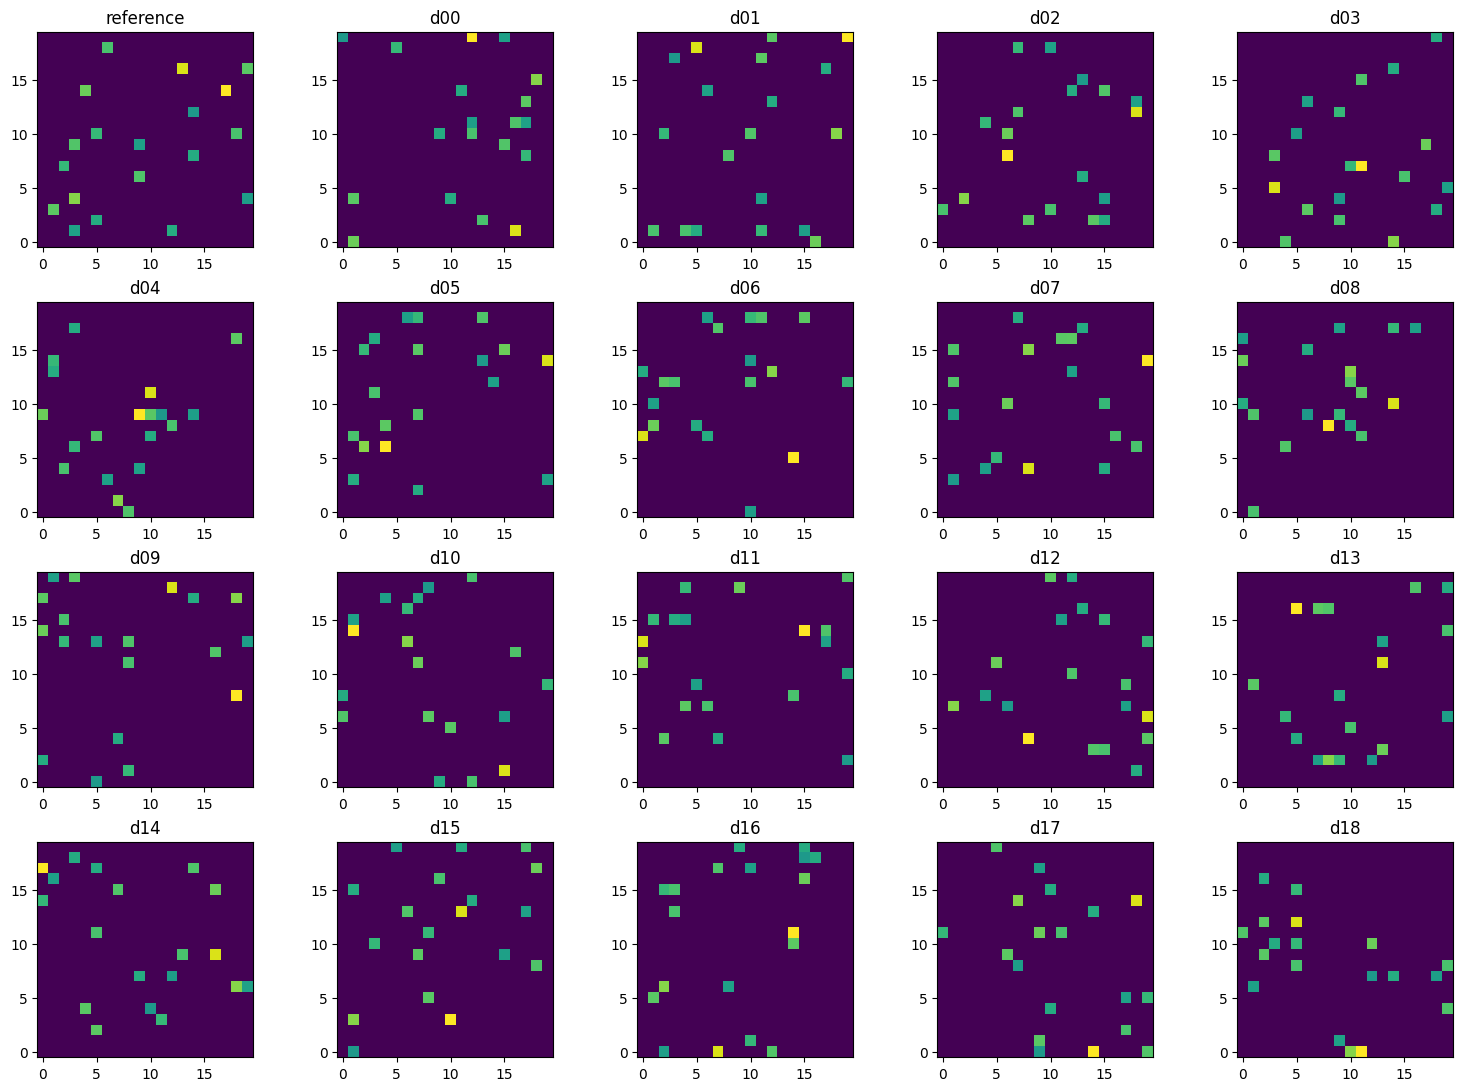

Using exactly 20 manifest-listed map(s)


In [42]:
manifest=[]
active=reference.reshape(-1,2)[np.any(reference.reshape(-1,2)!=0,axis=1)].copy()
for i in range(N_DISORDERS):
    if i==0:
        mid='reference'; defect=reference.copy(); seed=None
    else:
        mid=f'd{i-1:02d}'; seed=20261122+i-1; gen=np.random.default_rng(seed)
        loc=gen.choice(400,len(active),replace=False)
        defect=np.zeros((400,2)); defect[loc]=active[gen.permutation(len(active))]
        defect=defect.reshape(20,20,2)
    np.save(MAP_DIR/f'{mid}.npy',defect)
    manifest.append({'id':mid,'seed':seed,'active_sites':int(np.count_nonzero(np.any(defect.reshape(-1,2)!=0,axis=1)))})
(MAP_DIR/'manifest.json').write_text(json.dumps(manifest,indent=2))
MAPS=[r['id'] for r in manifest]
assert len(MAPS)==N_DISORDERS
ncols=min(5,N_DISORDERS); nrows=math.ceil(N_DISORDERS/ncols)
fig,axs=plt.subplots(nrows,ncols,figsize=(3*ncols,2.7*nrows),squeeze=False,layout='constrained')
for ax in axs.flat: ax.axis('off')
for ax,row in zip(axs.flat,manifest):
    a=np.load(MAP_DIR/f"{row['id']}.npy")
    ax.imshow(np.linalg.norm(a,axis=2),origin='lower',interpolation='nearest'); ax.set_title(row['id']);ax.axis('on')
fig.savefig(FIG_DIR/'01_defect_maps.png',dpi=150); plt.show()
print('Using exactly',len(MAPS),'manifest-listed map(s)')

## 4. Four optimization methods — same budget and real FerroSim physics

For each (map, seed), GA–DKL, GFlowNet–DKL, guided diffusion–DKL, and QD–DKL all start from the **same** `INITIAL_CONTROLS` physical observations. Each generation adds 32 independent simulator proposals per algorithm (24 UCB + 4 uncertainty + 4 stratified common exploration). QUICK lowers model-training steps, **not** the physics fidelity. The cached initialization is counted once when reporting distinct simulator calls. The saved histories include every valid and invalid attempted physical evaluation.

A minimum of two initial controls is accepted by both the notebook and the command-line runner. If fewer than two yield valid physical outcomes, optimization stops with an informative error rather than silently fabricating training observations.

In [43]:
# QUICK changes proposer/surrogate training only; it does not replace the physical oracle.
if MODE=='QUICK':
    hyper=dict(candidates=96,common=32,dkl_initial=12,dkl=12,gfn_initial=25,gfn=20,gfn_pool=96,diff_initial=25,diff=20,max_substeps=5000)
else:
    hyper=dict(candidates=512,common=64,dkl_initial=150,dkl=45,gfn_initial=1500,gfn=800,gfn_pool=512,diff_initial=600,diff=300,max_substeps=100000)
print('Expected method-history observations:',len(MAPS)*len(SEEDS)*len(METHODS)*(INITIAL_CONTROLS+32*GENERATIONS))
print('Expected distinct simulator attempts:',len(MAPS)*len(SEEDS)*(INITIAL_CONTROLS+len(METHODS)*32*GENERATIONS))
started=time.monotonic()
for mid in MAPS:
    for seed in SEEDS:
        command=[sys.executable,str(LIB/'run_benchmark.py'),'--methods','all','--seeds',str(seed),
          '--generations',str(GENERATIONS),'--out',str(HISTORY_DIR/mid),'--resume',
          '--initial-count',str(INITIAL_CONTROLS),'--candidates',str(hyper['candidates']),
          '--common-candidates',str(hyper['common']),
          '--dkl-initial-steps',str(hyper['dkl_initial']),'--dkl-steps',str(hyper['dkl']),
          '--gfn-initial-steps',str(hyper['gfn_initial']),'--gfn-steps',str(hyper['gfn']),
          '--gfn-reference-pool',str(hyper['gfn_pool']),'--gfn-refresh-every','100',
          '--diffusion-initial-steps',str(hyper['diff_initial']),'--diffusion-steps',str(hyper['diff']),
          '--diffusion-guidance','0.12','--fidelity','1','--max-substeps',str(hyper['max_substeps']),
          '--torch-threads','1','--oracle-threads','1','--no-save-final-p']
        env=os.environ.copy()
        env.update({'FERROSIM_DEFECT_PATH':str(MAP_DIR/f'{mid}.npy'),
           'NUMBA_NUM_THREADS':'1','OMP_NUM_THREADS':'1','OPENBLAS_NUM_THREADS':'1','MKL_NUM_THREADS':'1'})
        print(f'Running map={mid} seed={seed}',flush=True)
        subprocess.run(command,cwd=str(LIB),env=env,check=True)
print('Completed in',round(time.monotonic()-started,1),'seconds')

Expected method-history observations: 56320
Expected distinct simulator attempts: 52480
Running map=reference seed=0
Running map=d00 seed=0
Running map=d01 seed=0
Running map=d02 seed=0
Running map=d03 seed=0
Running map=d04 seed=0
Running map=d05 seed=0
Running map=d06 seed=0
Running map=d07 seed=0
Running map=d08 seed=0
Running map=d09 seed=0
Running map=d10 seed=0
Running map=d11 seed=0
Running map=d12 seed=0
Running map=d13 seed=0
Running map=d14 seed=0
Running map=d15 seed=0
Running map=d16 seed=0
Running map=d17 seed=0
Running map=d18 seed=0
Completed in 10988.5 seconds


## 5. Load measured observations and audit the evaluation budget

Confirm every requested map, seed, algorithm and observation is present. Export complete *measured* histories, including candidate origins, selection channels, DKL predictions, physical validity, computational work, and coefficients. A separate CSV without 32-D coefficient vectors is convenient for rapid inspection.

In [44]:
df=load(HISTORY_DIR)
assert len(df)>0,'No measured histories found; execute the previous cell.'
assert set(df['map'])==set(MAPS),f'Unexpected maps: {set(df["map"])} vs {set(MAPS)}'
assert set(df.seed)==set(SEEDS),'Missing or unexpected optimizer seeds'
assert set(df.method)==set(METHODS),'Missing optimizer histories'
from advanced_analysis import (audit_budget,shared_initial_baselines,exact_target_attainment,
    plot_pareto_by_disorder,plot_best_waveforms_by_disorder,complexity_retention,
    seed_disorder_variance,paired_method_comparison,proposal_attribution,surrogate_calibration,
    plot_additional_complexity_metrics,export_index)
run_audit=audit_budget(df,MAPS,SEEDS,INITIAL_CONTROLS,GENERATIONS,TABLE_DIR,FIG_DIR)
display(run_audit.sort_values(['map','seed','method']).head(24))
df.drop(columns=['coefficients']).to_csv(TABLE_DIR/'all_evaluations_without_vectors.csv',index=False)
print('Total method-history observations:',len(df),'of which valid:',int(df.valid.sum()))

Evaluation accounting: {'recorded_method_observations': 56320, 'expected_method_observations': 56320, 'expected_distinct_physical_calls': 52480, 'valid_recorded_observations': 56311, 'invalid_recorded_observations': 9, 'n_maps': 20, 'n_seeds': 1, 'initial_controls_per_map_seed': 64, 'new_evaluations_per_method_generation': 32, 'generations': 20}


,map,seed,method,attempts,valid,invalid,initialization,new_queries,best_curl,best_interior_curl,best_turns,peak_ec_best,rhs_calls,substeps
0,d00,0,diffusion_dkl,704,704,0,64,640,10.701385,8.620008,22,5924.812575,17011728,4252932
1,d00,0,ga_dkl,704,704,0,64,640,10.964489,8.658347,22,20.656452,9144768,2286192
3,d00,0,gflownet_dkl,704,704,0,64,640,10.713248,8.620008,25,378.197701,10340912,2585228
2,d00,0,qd_dkl,704,703,1,64,640,10.940540,8.655699,29,24.907318,12579040,3144760
20,d01,0,diffusion_dkl,704,704,0,64,640,10.858839,8.220380,5,4838.371818,18091580,4522895
21,d01,0,ga_dkl,704,701,3,64,640,10.965819,8.220380,30,44.250157,17218272,4304568
23,d01,0,gflownet_dkl,704,704,0,64,640,10.885829,8.220380,24,418.782248,12279932,3069983
22,d01,0,qd_dkl,704,702,2,64,640,10.961710,8.231204,7,280.022687,15180552,3795138
40,d02,0,diffusion_dkl,704,704,0,64,640,12.691362,10.445032,1,28.546248,14632444,3658111
41,d02,0,ga_dkl,704,704,0,64,640,12.752103,10.446973,26,27.049118,9335752,2333938


Total method-history observations: 56320 of which valid: 56311


## 6. Optimization efficiency — reference convergence and normalized pooled improvement

The left panel is the **best actual RK4 curl** versus attempted evaluation count on the reference map. The right averages improvement progress across all available (map, seed) pairs, normalizing each curve against the **best valid shared initial control for that map and seed**, not an arbitrary first initial waveform. Pooled targets are observed results from these experiments (not unattainable external optima). If only one run exists, no spurious uncertainty band is drawn.

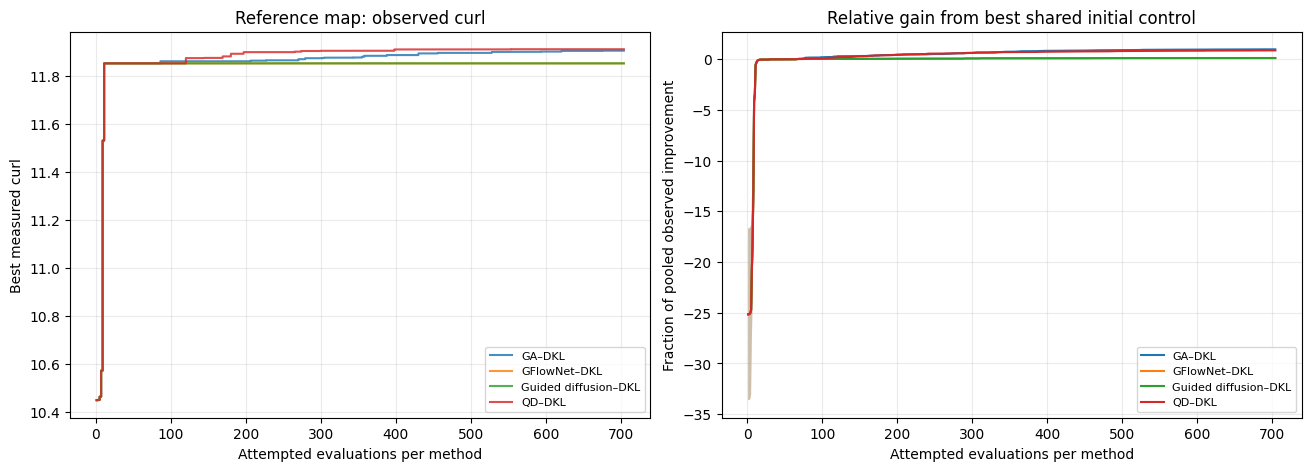

In [45]:
initial_baselines=shared_initial_baselines(df)
fig,axs=plt.subplots(1,2,figsize=(13,4.6),layout='constrained')
for method in METHODS:
    d=df[(df.method==method)&(df['map']=='reference')]
    for j,(seed,g) in enumerate(d.groupby('seed')):
        g=g.sort_values('evaluation')
        best=np.maximum.accumulate(np.where(g.valid,g.reward,-np.inf))
        axs[0].step(g.evaluation,best,where='post',label=NAMES[method] if j==0 else None,alpha=.82)
    aggregated=[]
    for (mid,seed),g in df[df.method==method].groupby(['map','seed']):
        g=g.sort_values('evaluation')
        context=df[(df['map']==mid)&(df.seed==seed)]
        baseline=float(initial_baselines[(mid,seed)])
        upper=float(context.loc[context.valid,'reward'].max())
        best=np.maximum.accumulate(np.where(g.valid,g.reward,-np.inf))
        normalizer=upper-baseline
        normalized=np.zeros(len(best)) if normalizer<=1e-12 else (best-baseline)/normalizer
        aggregated.append(normalized)
    Y=np.stack(aggregated)
    xx=np.arange(1,Y.shape[1]+1)
    axs[1].plot(xx,Y.mean(axis=0),label=NAMES[method])
    if len(Y)>1:
        err=Y.std(axis=0,ddof=1)/np.sqrt(len(Y))
        axs[1].fill_between(xx,Y.mean(axis=0)-err,Y.mean(axis=0)+err,alpha=.13)
axs[0].set(title='Reference map: observed curl',xlabel='Attempted evaluations per method',ylabel='Best measured curl')
axs[1].set(title='Relative gain from best shared initial control',xlabel='Attempted evaluations per method',ylabel='Fraction of pooled observed improvement')
for ax in axs:ax.grid(alpha=.25);ax.legend(fontsize=8)
fig.savefig(FIG_DIR/'02_convergence.png',dpi=150);plt.show();plt.close(fig)

## 7. Exact evaluations to reach 95% and 99% of observed improvement

The threshold is defined relative to the best valid shared initialization for the **same disorder and seed**, and the best observed physical reward pooled over methods and seeds for that disorder. Unlike older approximations, the first hitting evaluation is read directly from recorded physical history.

In [46]:
targets=exact_target_attainment(df,TABLE_DIR)
display(targets.groupby(['method','fraction'],as_index=False).agg(
    reached=('reached','sum'),runs=('reached','count'),median_evaluations=('first_evaluation','median')))

,method,fraction,reached,runs,median_evaluations
0,diffusion_dkl,0.95,0,20,NaN
1,diffusion_dkl,0.99,0,20,NaN
2,ga_dkl,0.95,17,20,527.0
3,ga_dkl,0.99,16,20,630.5
4,gflownet_dkl,0.95,0,20,NaN
5,gflownet_dkl,0.99,0,20,NaN
6,qd_dkl,0.95,10,20,524.0
7,qd_dkl,0.99,7,20,554.0


## 8. Reference-map reward–complexity Pareto fronts

Historical Pareto means non-dominated **measured** controls, not proposed-but-unmeasured candidates. The complexity measure is the number of prominent turns at 2% of the waveform's peak-to-peak scale. Independent 1% and 5% and raw-turn metrics are archived for sensitivity analysis.

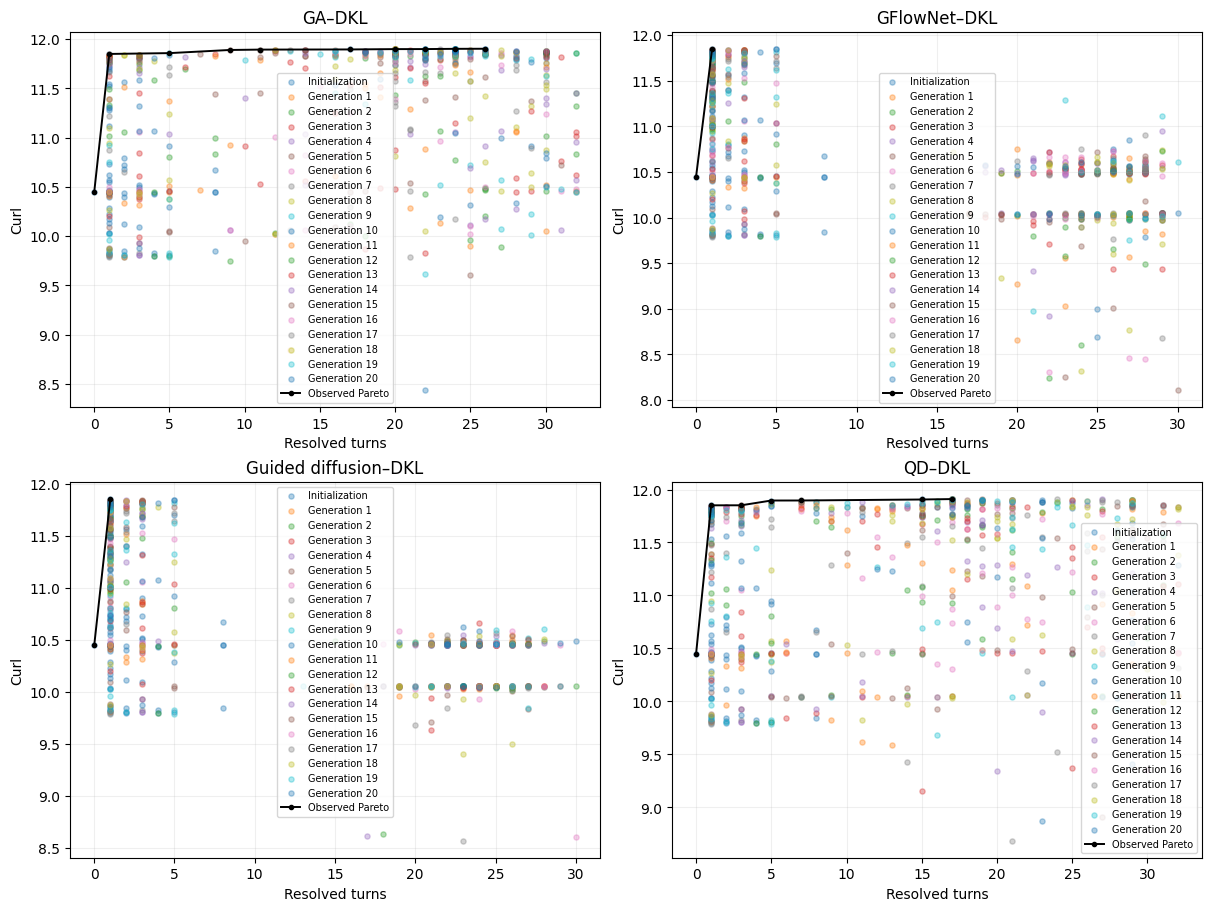

In [47]:
fig,axs=plt.subplots(2,2,figsize=(12,9),layout='constrained')
ref=df[df['map']=='reference']
for ax,method in zip(axs.flat,METHODS):
    g=ref[(ref.method==method)&ref.valid]
    for generation,h in g.groupby('generation'):
        ax.scatter(h.complexity,h.reward,s=14,alpha=.35,label=('Initialization' if generation==0 else f'Generation {generation}'))
    frontier=pareto(g)
    ax.plot(frontier.complexity,frontier.reward,'ko-',lw=1.4,ms=3,label='Observed Pareto')
    ax.set(title=NAMES[method],xlabel='Resolved turns',ylabel='Curl');ax.grid(alpha=.2);ax.legend(fontsize=7)
fig.savefig(FIG_DIR/'03_reward_complexity.png',dpi=150);plt.show()

## 9. Evolution of coefficients and rendered control waves (`imshow`)

For each optimizer, each row of the image displays the best observed control at the end of a generation, including generation zero. The Legendre coefficients and the actual applied electric-field history are both plotted. This works for `GENERATIONS=0` or more.

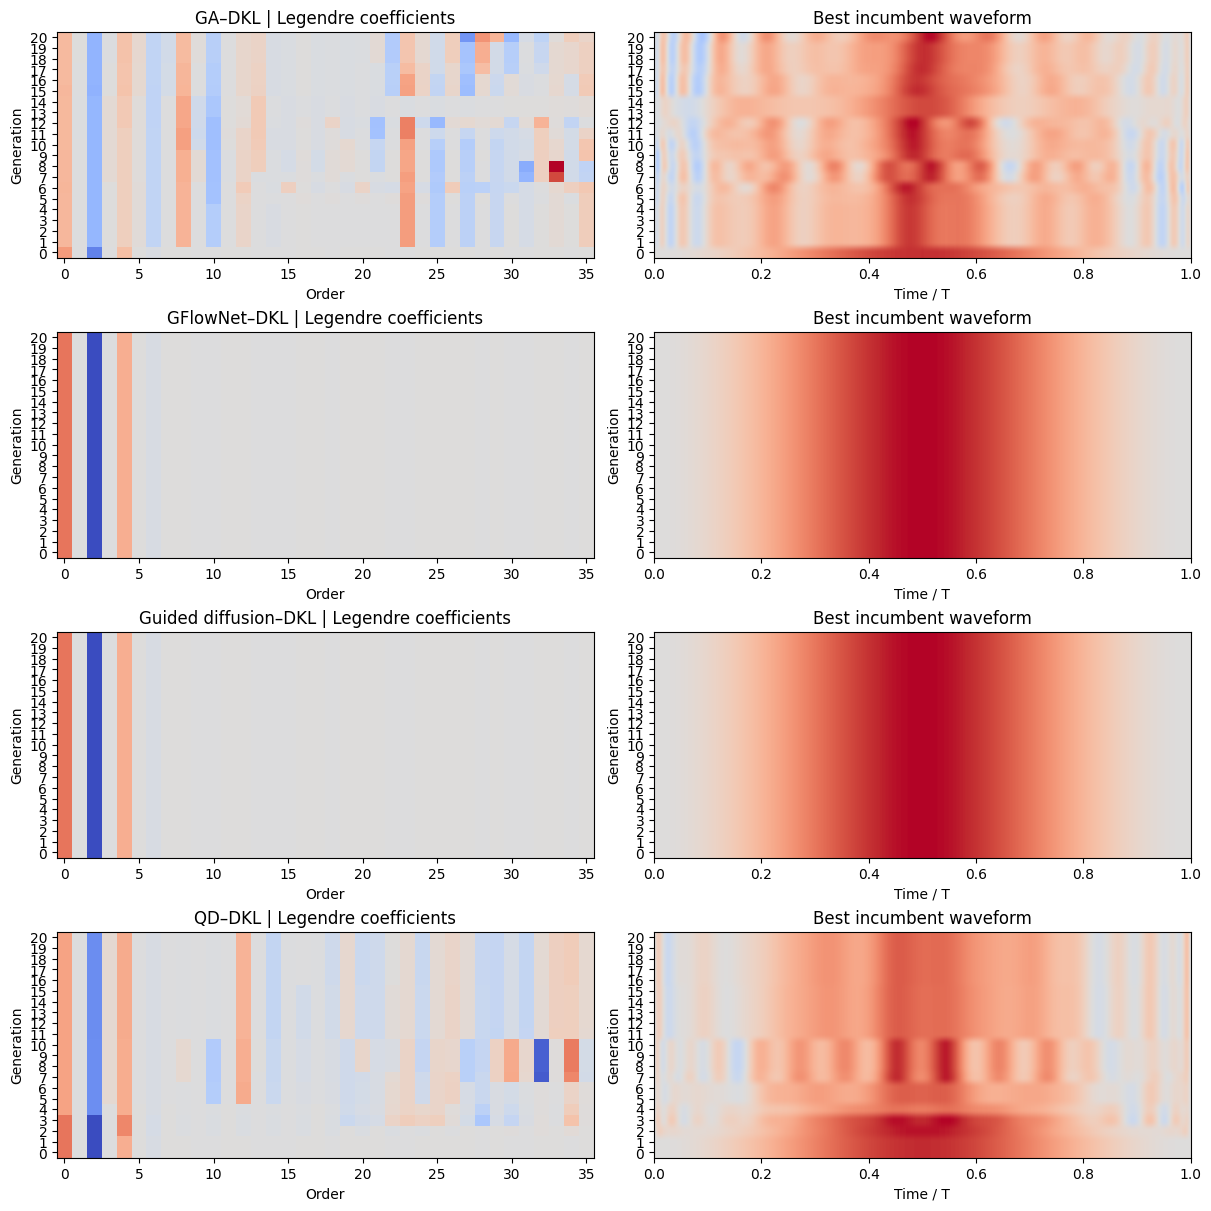

In [48]:
from representation import full_coefficients,fields
fig,axs=plt.subplots(4,2,figsize=(12,12),layout='constrained')
for row,method in enumerate(METHODS):
    h=ref[(ref.method==method)&ref.valid]
    amps=[];waves=[]
    for gen in range(GENERATIONS+1):
        q=h[h.generation<=gen]
        if q.empty: continue
        item=q.loc[q.reward.idxmax()]
        amps.append(full_coefficients(item.coefficients))
        waves.append(fields(item.coefficients))
    amps=np.asarray(amps);waves=np.asarray(waves)
    if not len(amps): continue
    maxamp=max(1e-9,np.max(np.abs(amps)))
    ax=axs[row,0]; ax.imshow(amps,aspect='auto',origin='lower',cmap='coolwarm',vmin=-maxamp,vmax=maxamp,
        extent=[-.5,35.5,-.5,len(amps)-.5]);ax.set(title=NAMES[method]+' | Legendre coefficients',xlabel='Order',ylabel='Generation')
    maxamp=max(1e-9,np.max(np.abs(waves)))
    ax=axs[row,1];ax.imshow(waves,aspect='auto',origin='lower',cmap='coolwarm',vmin=-maxamp,vmax=maxamp,
        extent=[0,1,-.5,len(waves)-.5]);ax.set(title='Best incumbent waveform',xlabel='Time / T',ylabel='Generation')
    for a in axs[row]: a.set_yticks(np.arange(len(amps)))
fig.savefig(FIG_DIR/'04_evolution.png',dpi=150);plt.show()

## 10. Reference best waveform and simple control

Show the globally best observed waveform on the reference map and the highest-reward waveform with at most one prominent turning point, including their 36 physical Legendre coefficients. These are measured physical rewards, not interpolated scores.

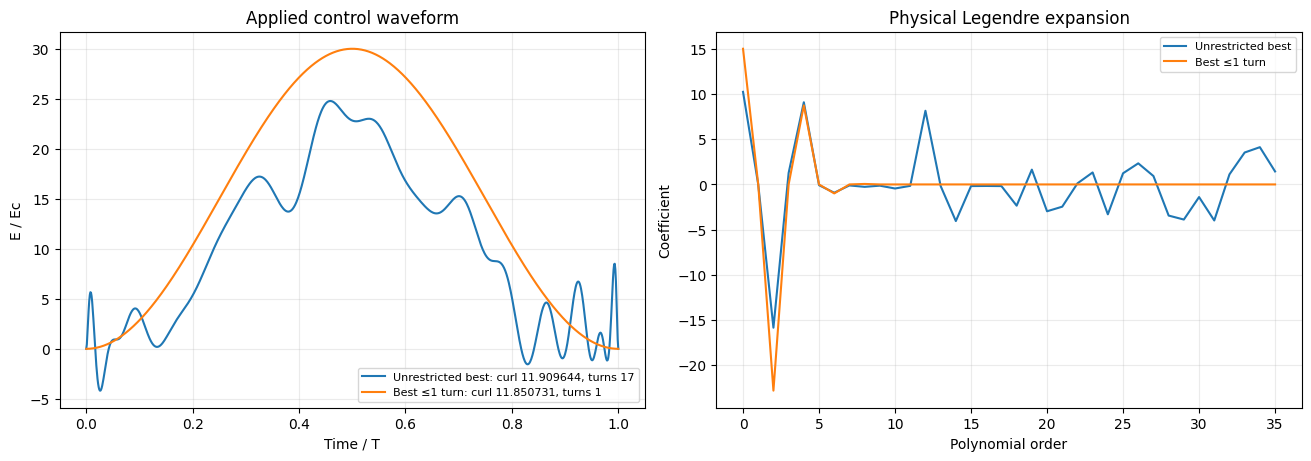

Best observed reward 11.90964439 turns 17
Best simple reward 11.85073074 turns 1


In [49]:
valid=ref[ref.valid]
champ=valid.loc[valid.reward.idxmax()]
simple_set=valid[valid.complexity<=1]
simple=(simple_set.loc[simple_set.reward.idxmax()] if len(simple_set) else None)
fig,axs=plt.subplots(1,2,figsize=(13,4.5),layout='constrained')
for row,label in [(champ,'Unrestricted best')]+([(simple,'Best ≤1 turn')] if simple is not None else []):
    w=fields(row.coefficients)
    axs[0].plot(np.linspace(0,1,len(w)),w,label=f'{label}: curl {row.reward:.6f}, turns {row.complexity}')
    axs[1].plot(np.arange(36),full_coefficients(row.coefficients),label=label)
axs[0].set(title='Applied control waveform',xlabel='Time / T',ylabel='E / Ec')
axs[1].set(title='Physical Legendre expansion',xlabel='Polynomial order',ylabel='Coefficient')
for ax in axs: ax.grid(alpha=.25);ax.legend(fontsize=8)
fig.savefig(FIG_DIR/'05_best_and_simple_controls.png',dpi=150);plt.show()
print('Best observed reward',round(champ.reward,8),'turns',champ.complexity)
if simple is not None:print('Best simple reward',round(simple.reward,8),'turns',simple.complexity)

## 10b. Legendre coefficient spectrum and modal energy

Plot the physical amplitudes and orthogonal mode-energy contributions of the reference champion and the simplest high-performing control, quantifying whether any small reward improvement requires high polynomial orders.

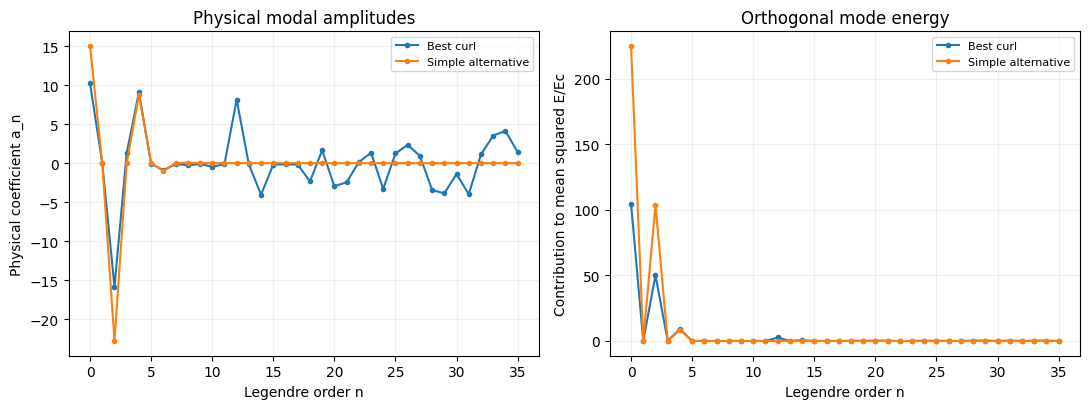

In [50]:
from analysis import plot_mode_energy
modal_fig=plot_mode_energy(df,FIG_DIR/'05_legendre_mode_energy.png')
if modal_fig is not None: plt.show();plt.close(modal_fig)

## 11. Disorder-dependent winners, simplicity, and variation

Works for one disorder and one seed. The per-map plot is omitted when only one map exists, but per-map summary tables remain. The follow-on section decomposes *between-disorder* and *within-disorder seed* variance where those quantities are actually identifiable.

,map,best_curl,best_turns,simple_curl,simple_turns
0,d00,10.964489,22,10.619723,1
1,d01,10.965819,30,10.857474,1
2,d02,12.752103,26,12.691362,1
3,d03,12.054360,21,11.640635,1
4,d04,13.022287,29,12.688733,1
5,d05,12.889309,27,12.602427,1
6,d06,12.811597,24,12.528340,1
7,d07,12.419732,20,12.409596,1
8,d08,13.303982,24,12.816433,1
9,d09,12.571324,22,12.490722,1


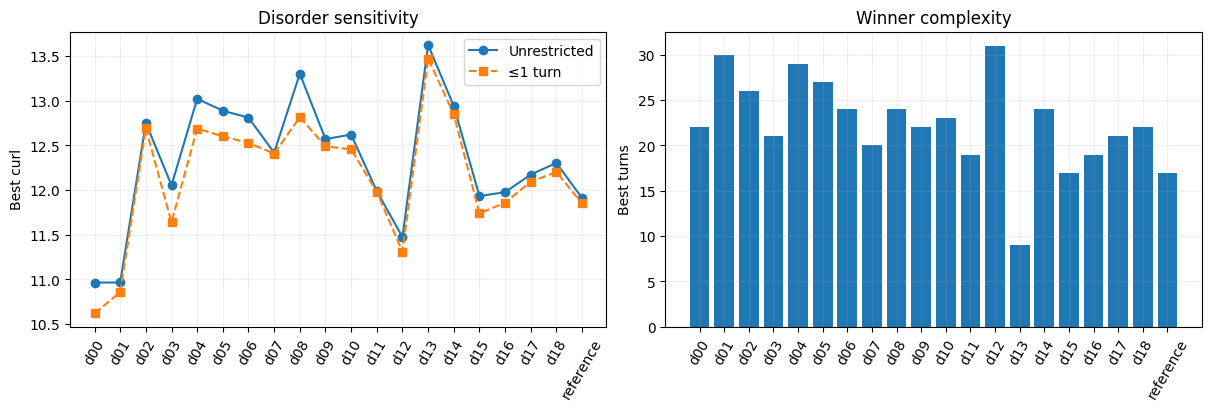

In [51]:
comparison=[]
for mid,g in df[df.valid].groupby('map'):
    best=g.loc[g.reward.idxmax()]
    q=g[g.complexity<=1]
    simple=q.loc[q.reward.idxmax()] if len(q) else None
    comparison.append(dict(map=mid,best_curl=best.reward,best_turns=best.complexity,
        simple_curl=(float(simple.reward) if simple is not None else np.nan),
        simple_turns=(int(simple.complexity) if simple is not None else np.nan)))
map_stats=pd.DataFrame(comparison);display(map_stats)
map_stats.to_csv(TABLE_DIR/'disorder_summary.csv',index=False)
if len(map_stats)>1:
    fig,axs=plt.subplots(1,2,figsize=(12,4),layout='constrained')
    axs[0].plot(map_stats['map'],map_stats.best_curl,'o-',label='Unrestricted')
    axs[0].plot(map_stats['map'],map_stats.simple_curl,'s--',label='≤1 turn')
    axs[1].bar(map_stats['map'],map_stats.best_turns)
    axs[0].set(ylabel='Best curl',title='Disorder sensitivity');axs[1].set(ylabel='Best turns',title='Winner complexity')
    for ax in axs:ax.grid(alpha=.2);ax.tick_params(axis='x',rotation=60)
    axs[0].legend();fig.savefig(FIG_DIR/'06_disorder.png',dpi=150);plt.show()
else: print('One disorder: between-disorder variance and plots are intentionally omitted.')

## 12. Complete disorder-by-disorder analysis: champion waveforms

Create an independently inspectable **four-panel winner-versus-simple waveform figure for every disorder** (or reference only if disabled), using actual saved physical rewards, along with an accompanying CSV. The number of plotted maps follows `N_DISORDERS`; no fixed layout is assumed.

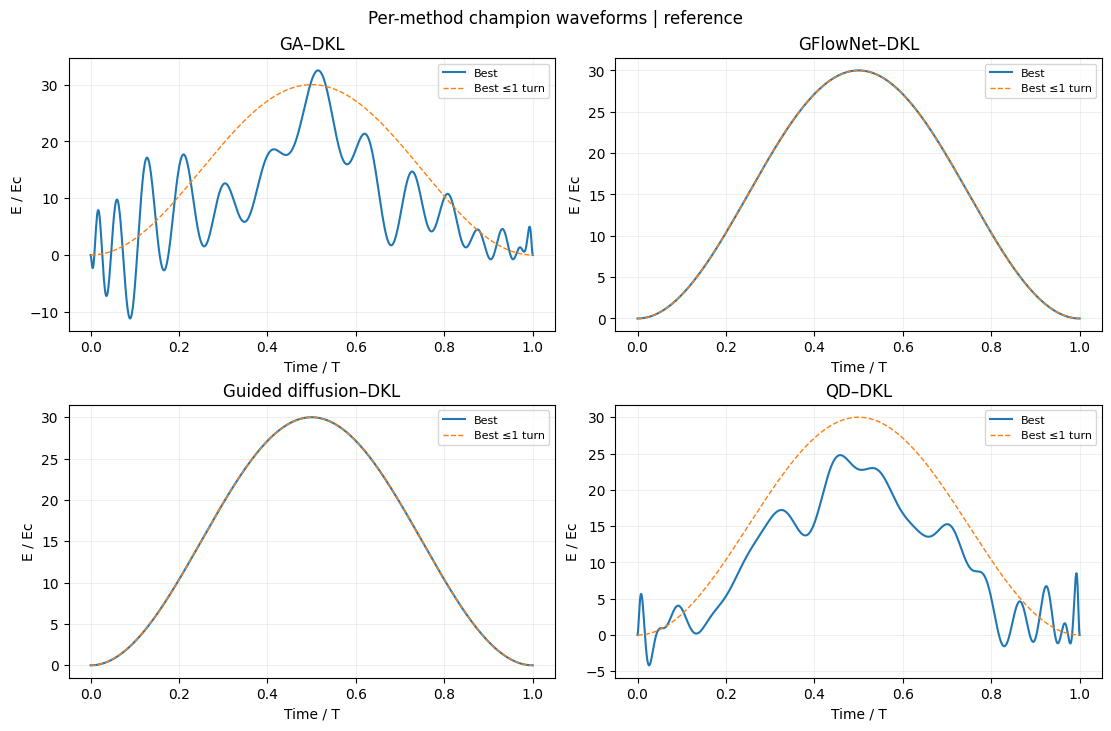

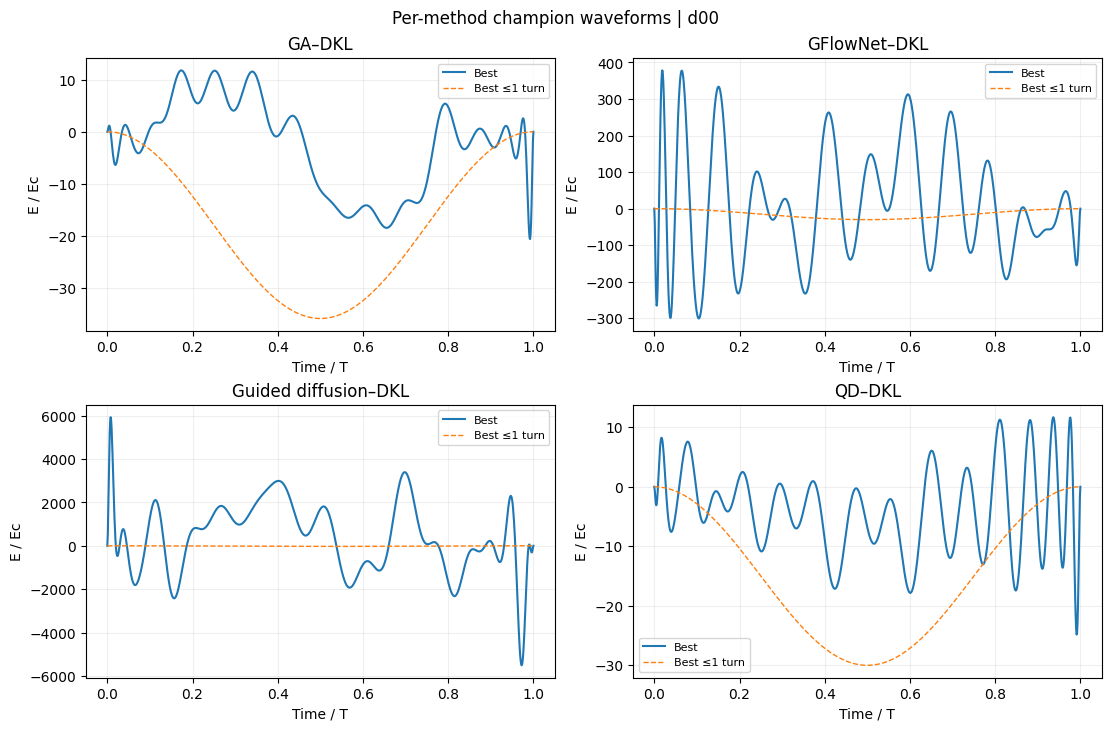

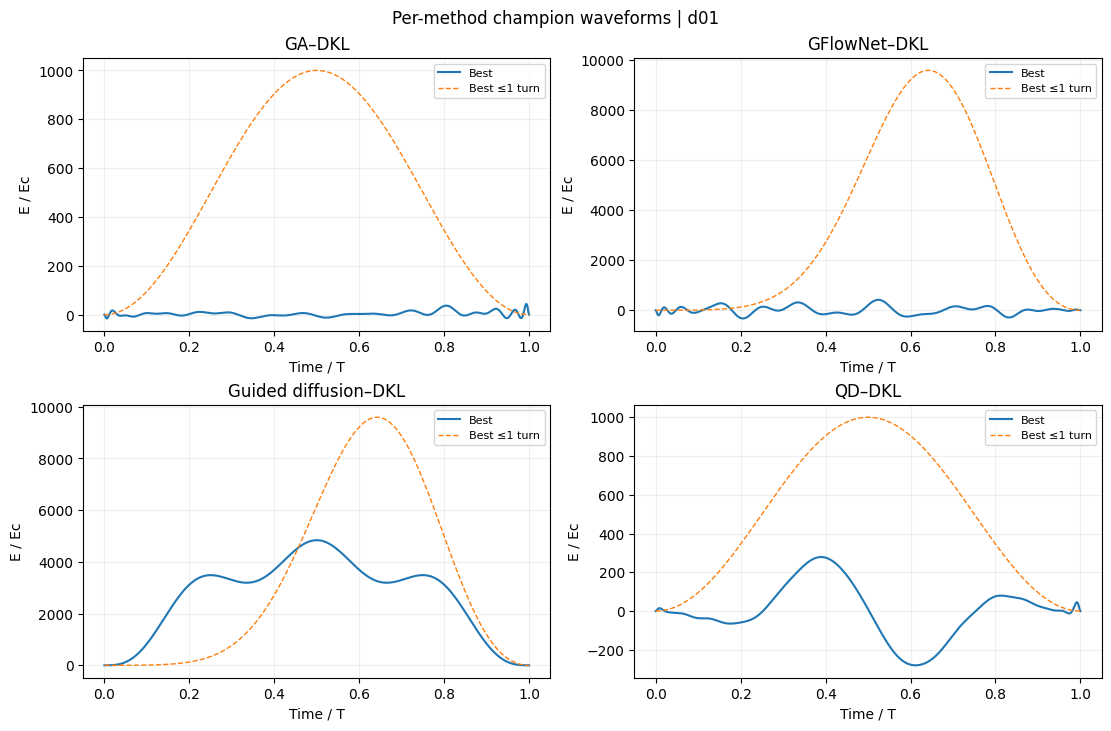

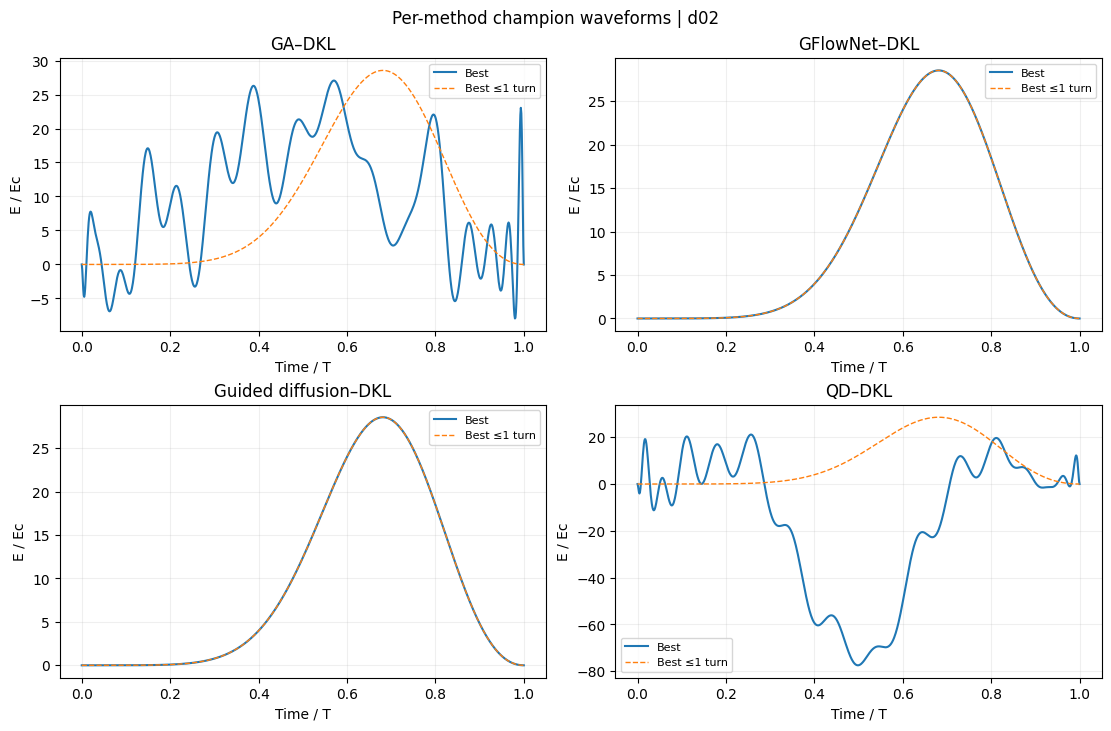

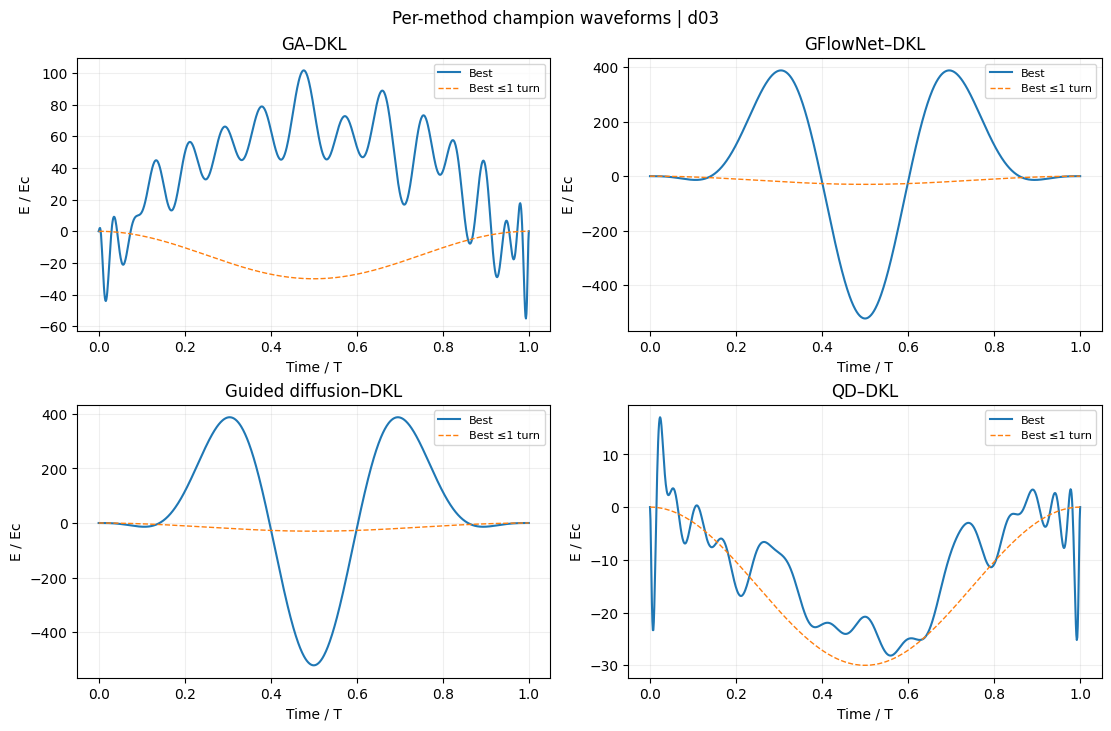

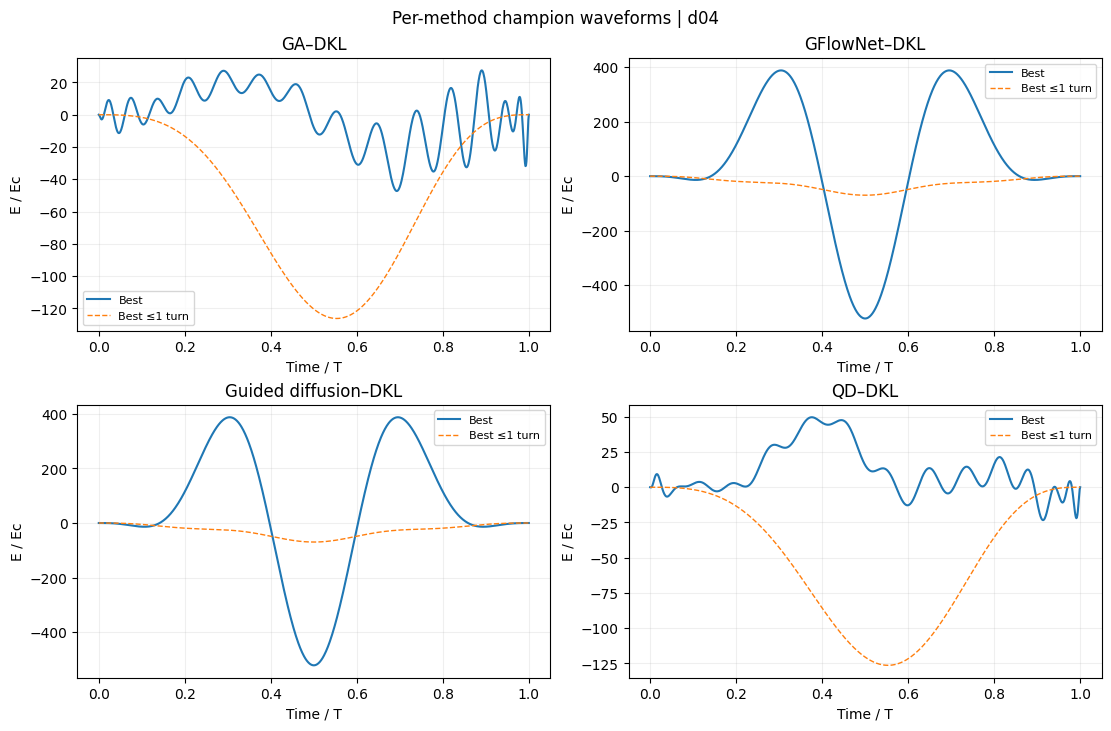

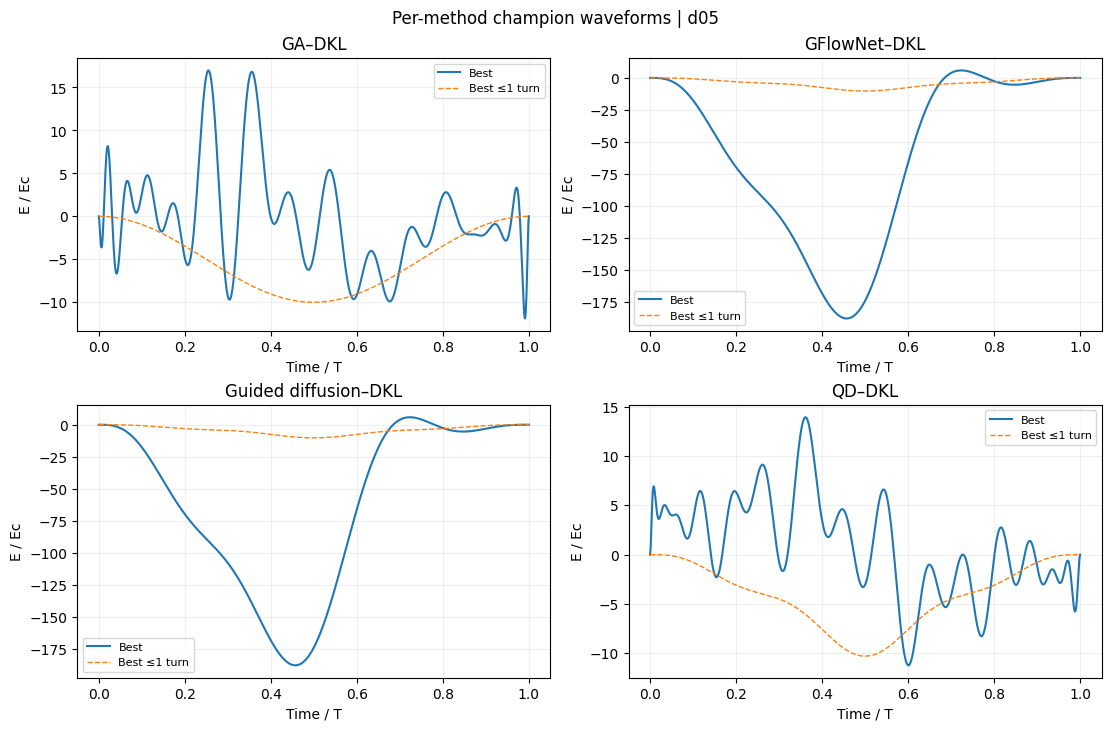

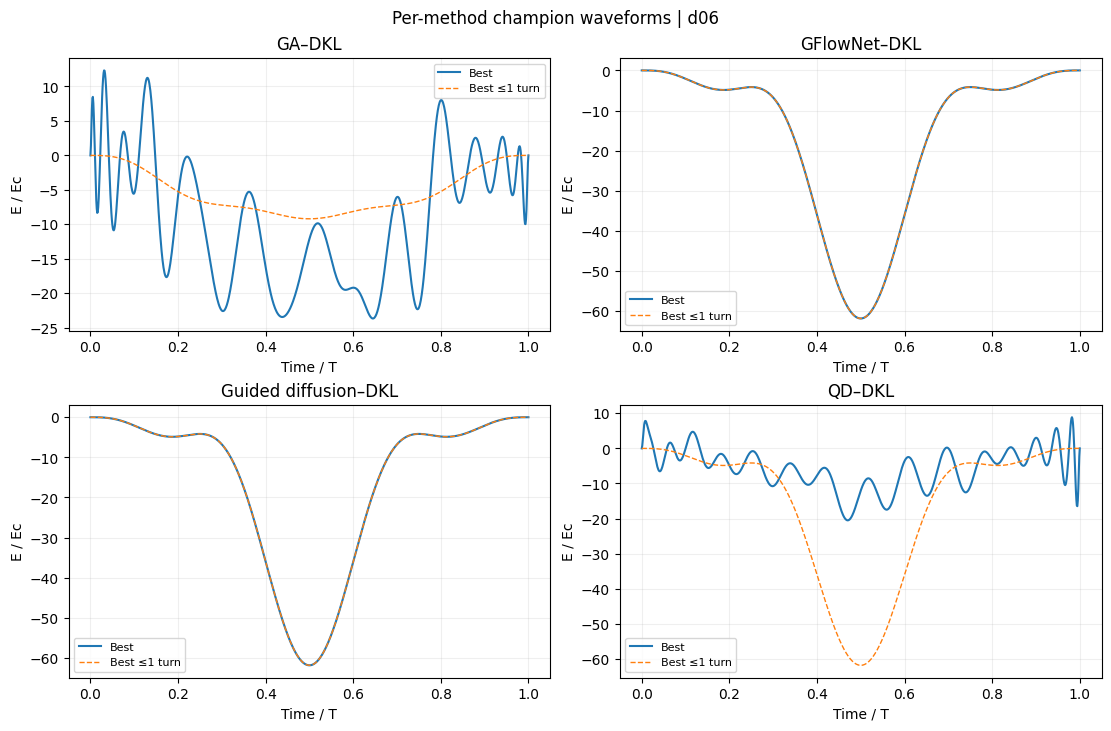

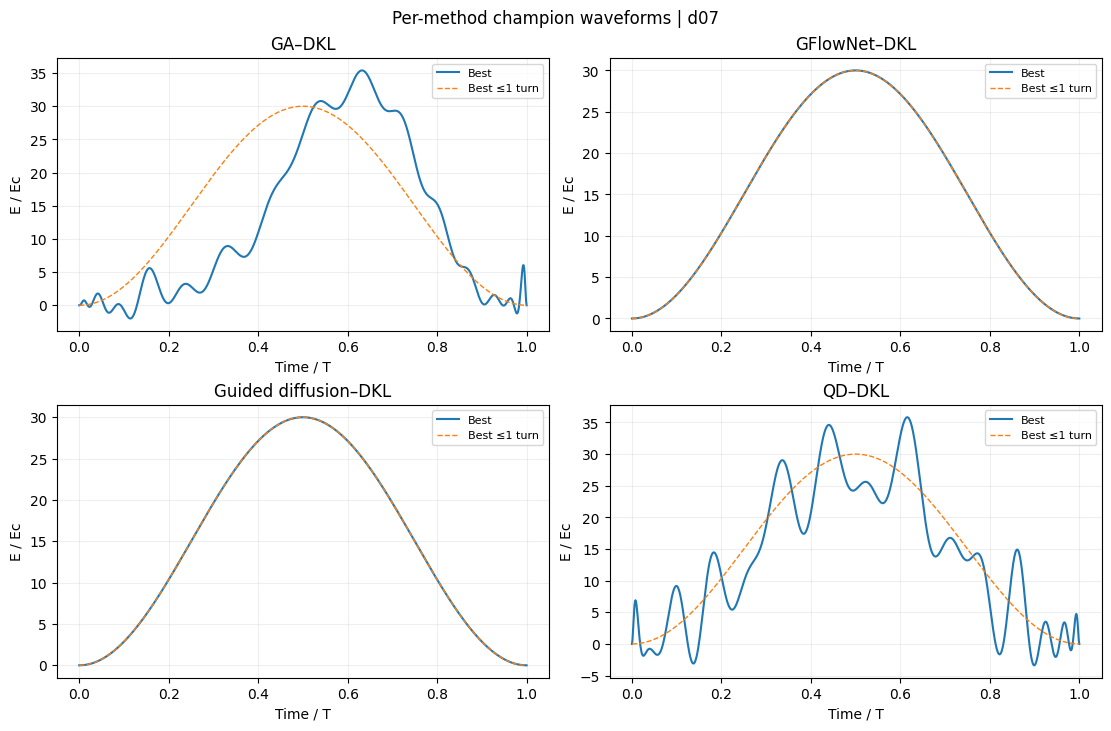

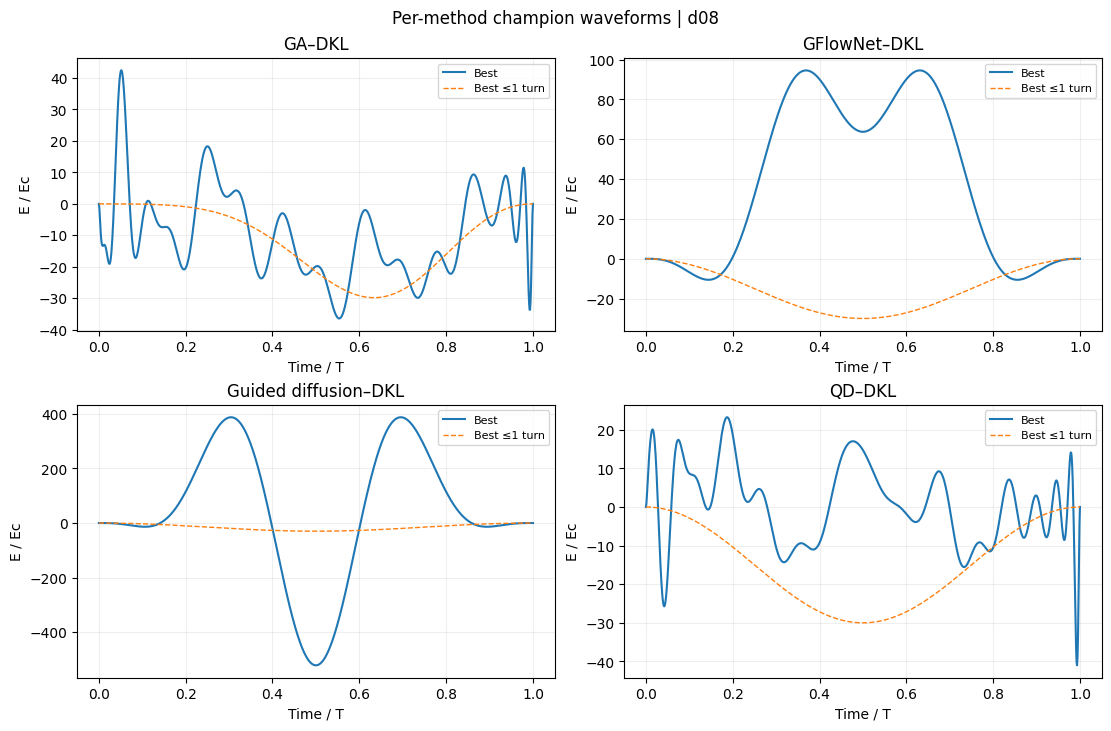

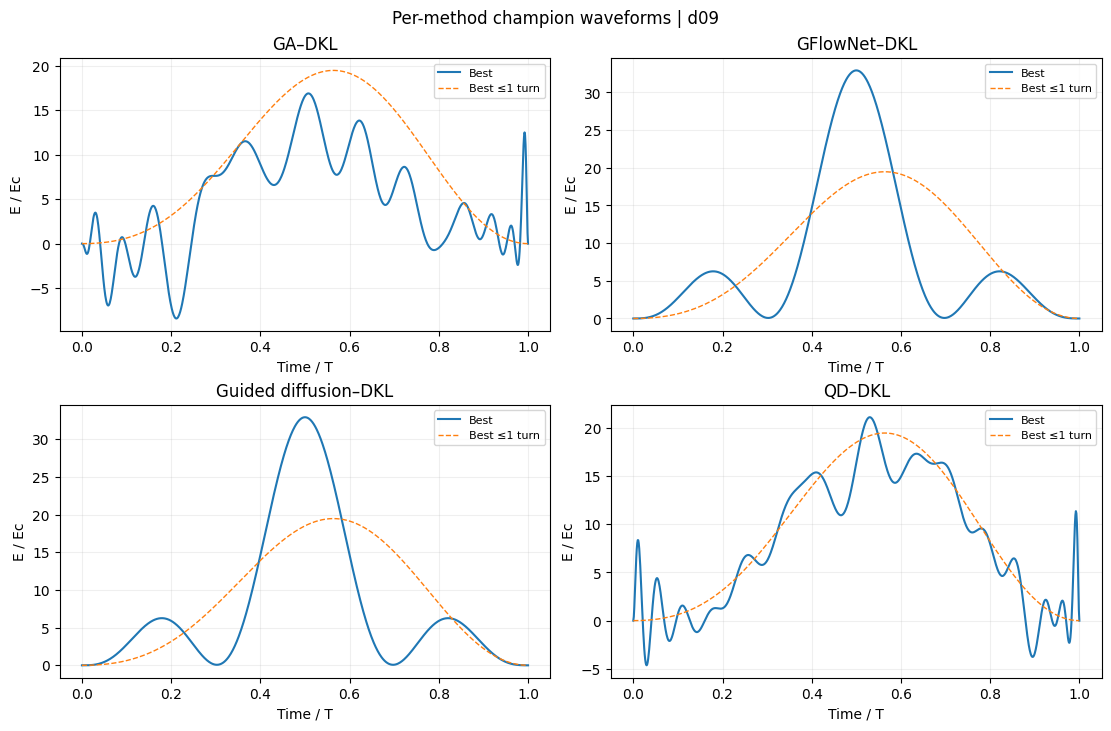

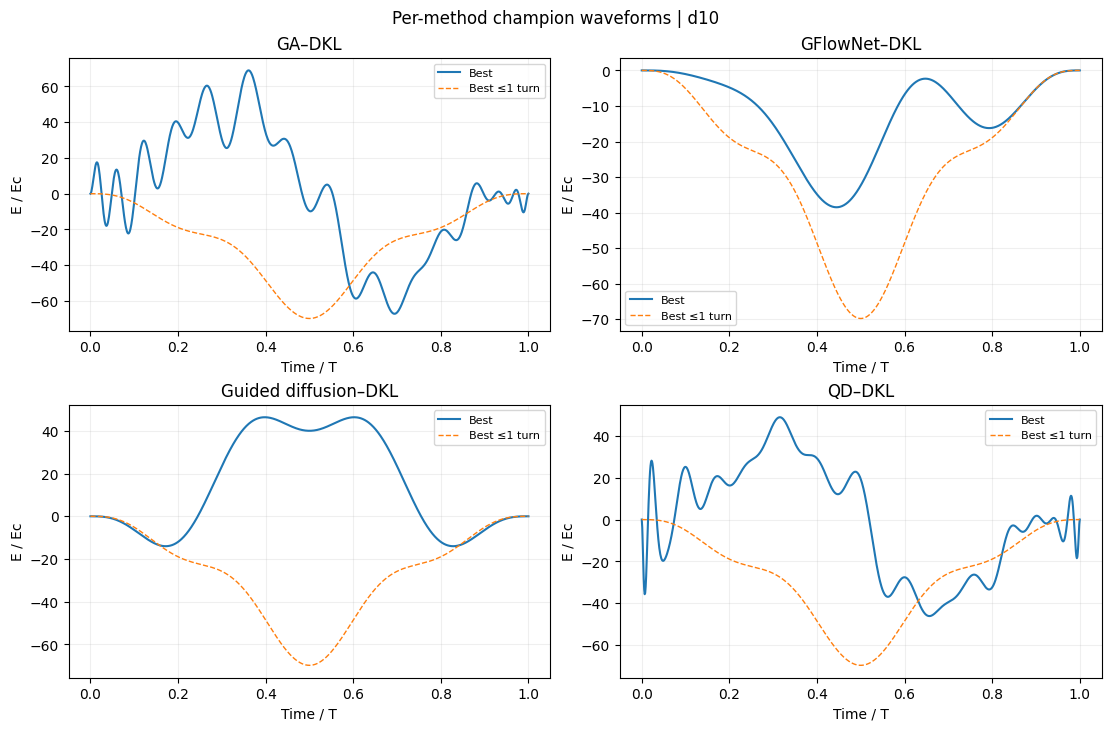

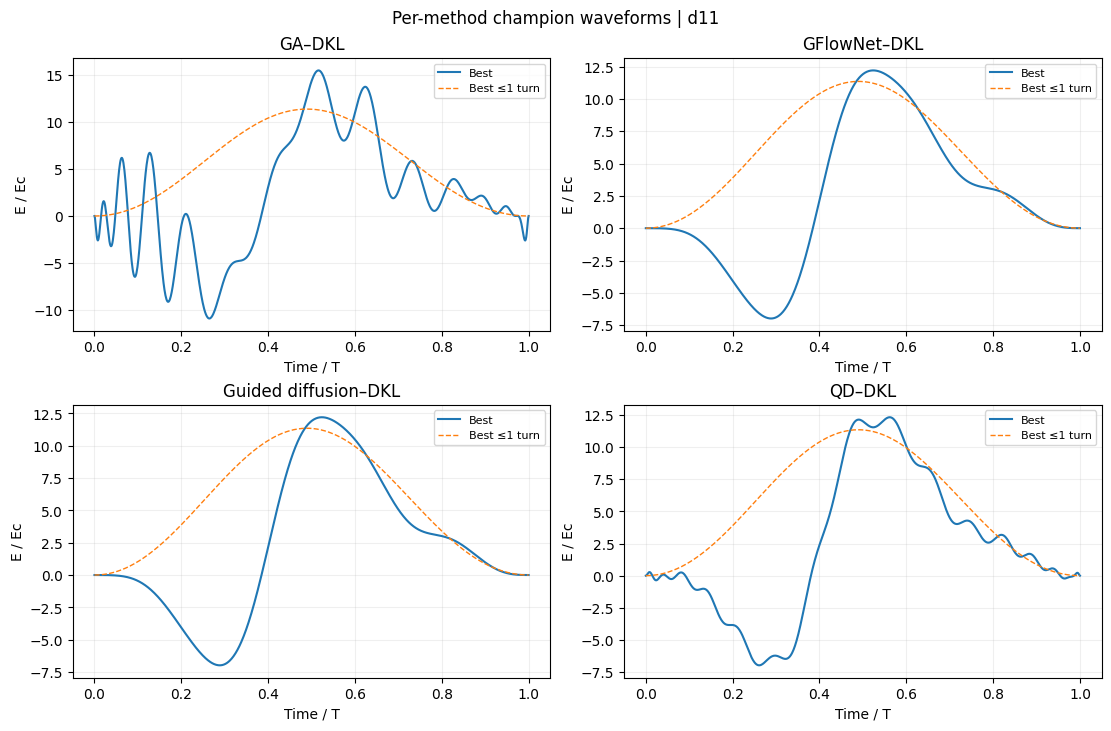

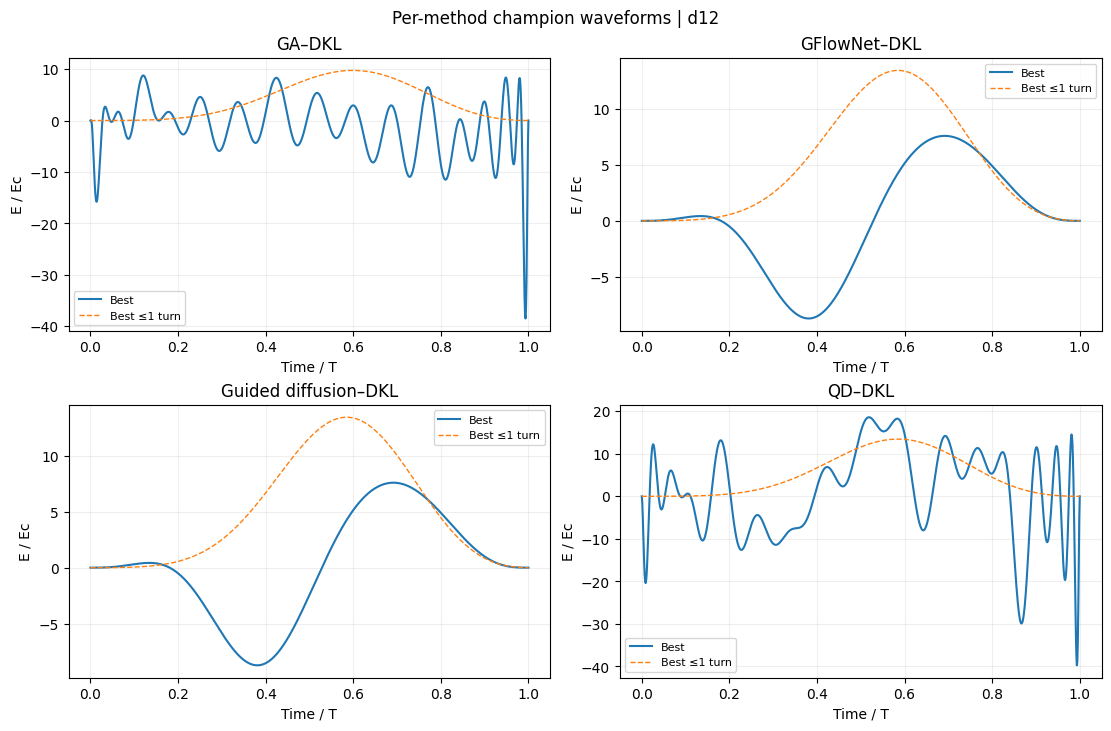

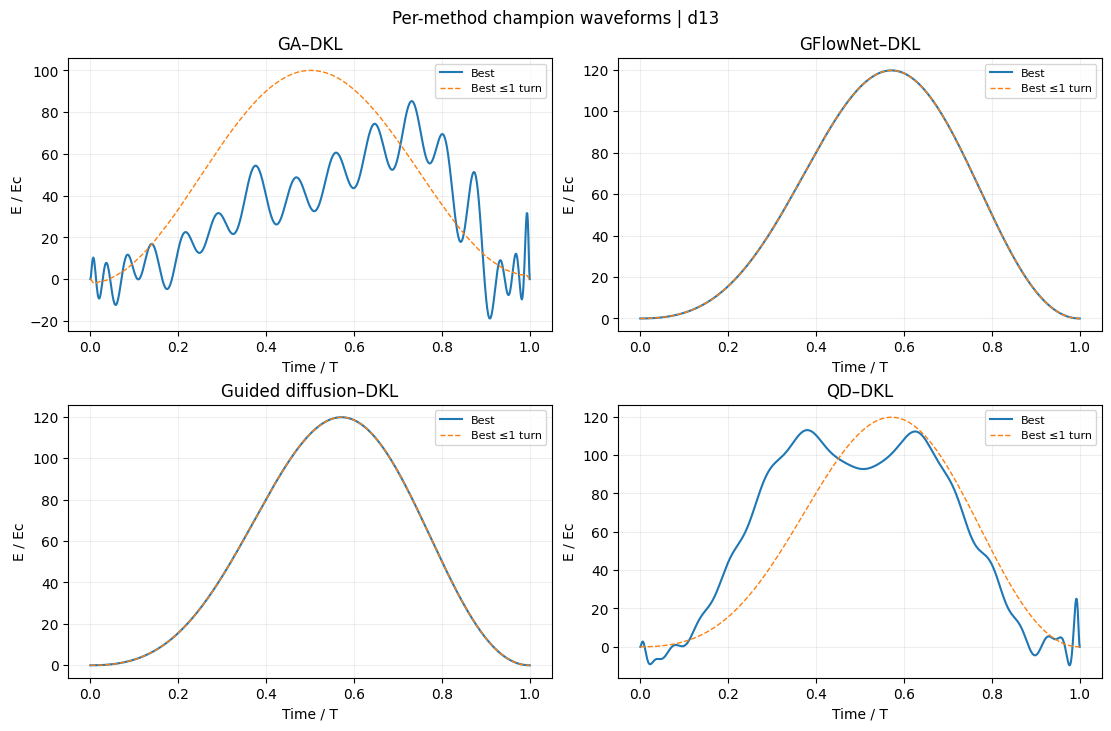

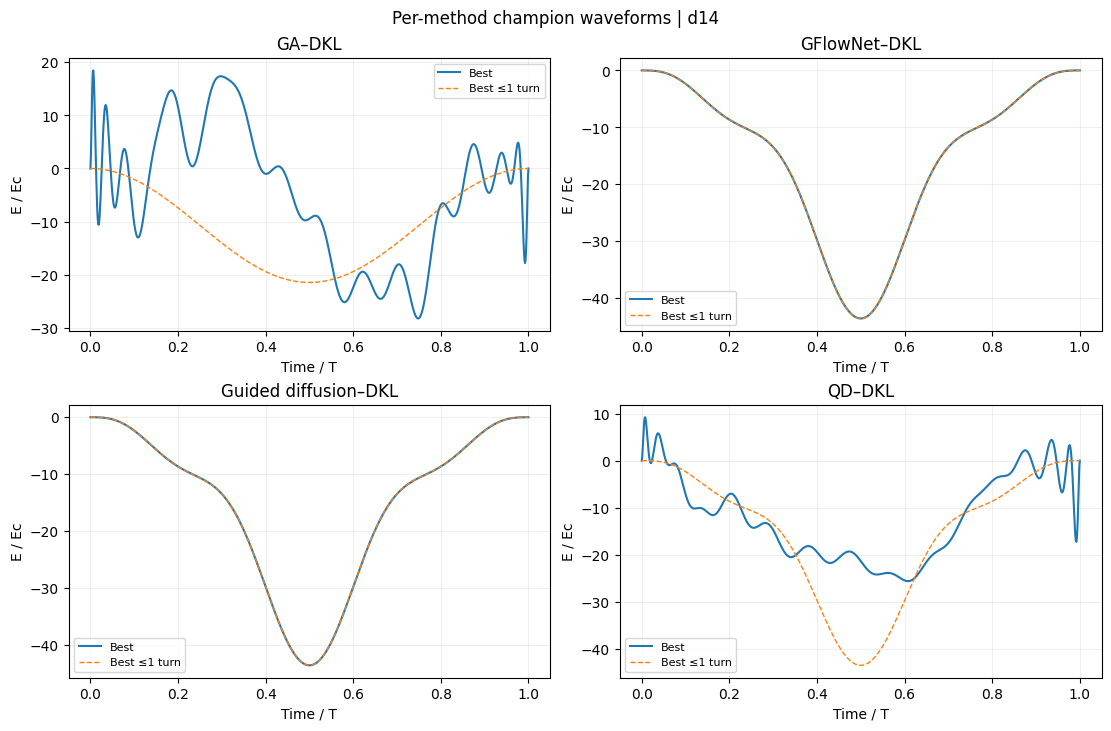

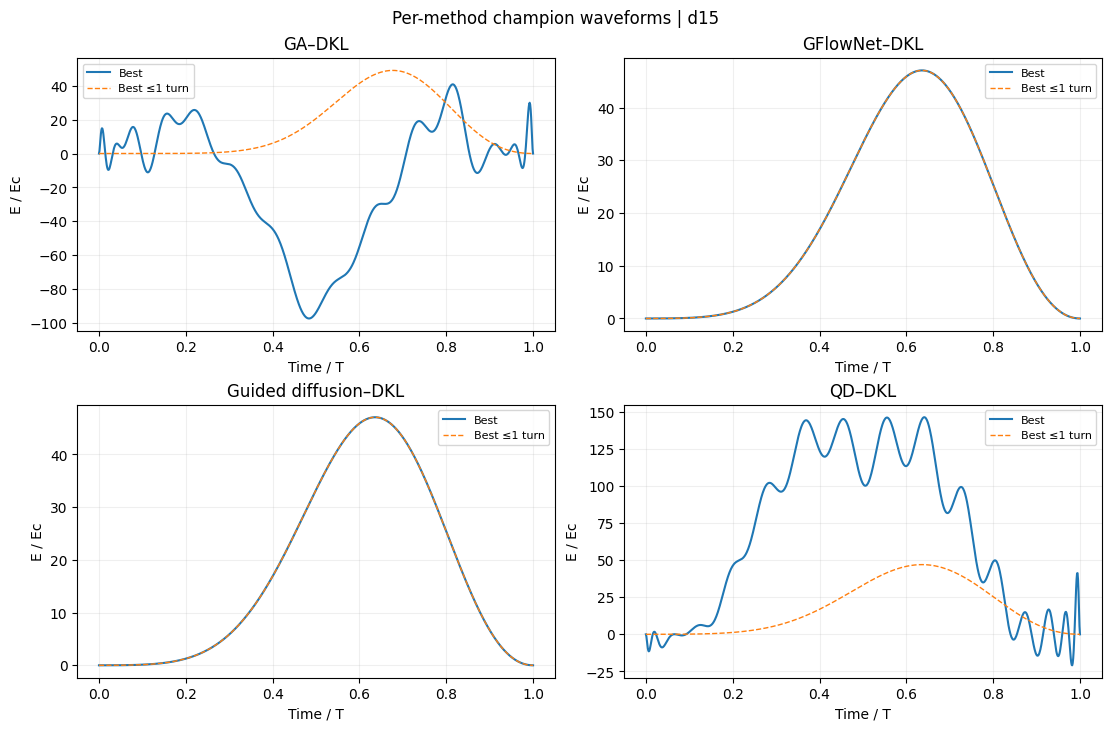

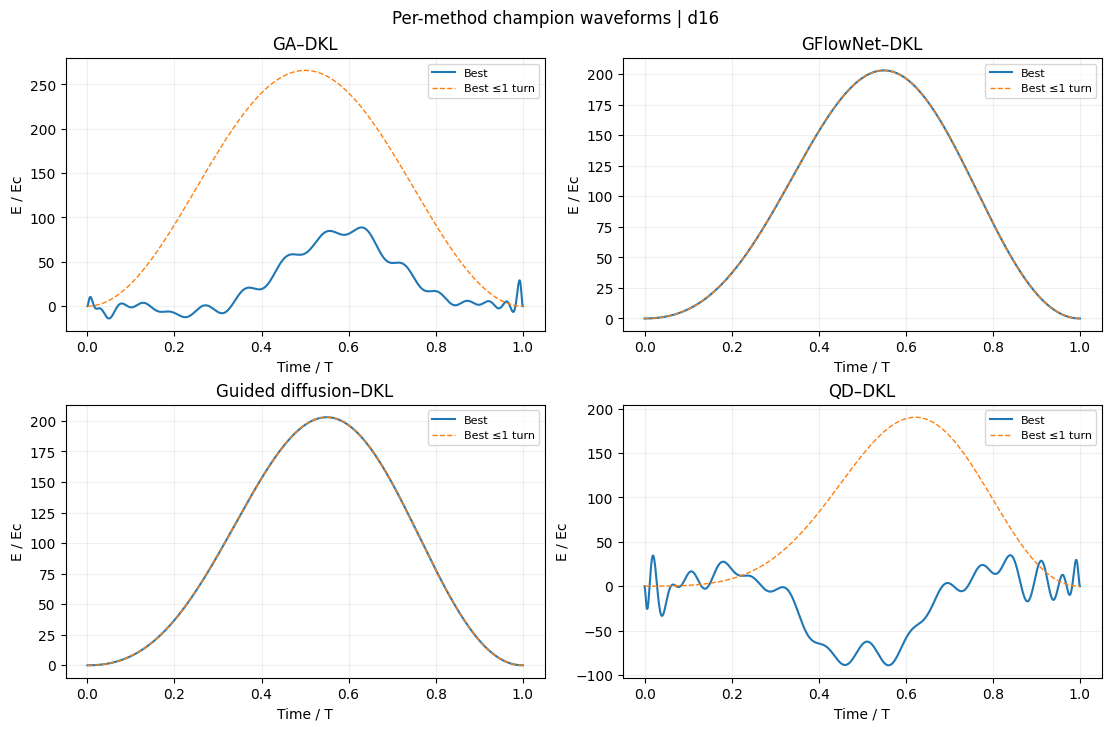

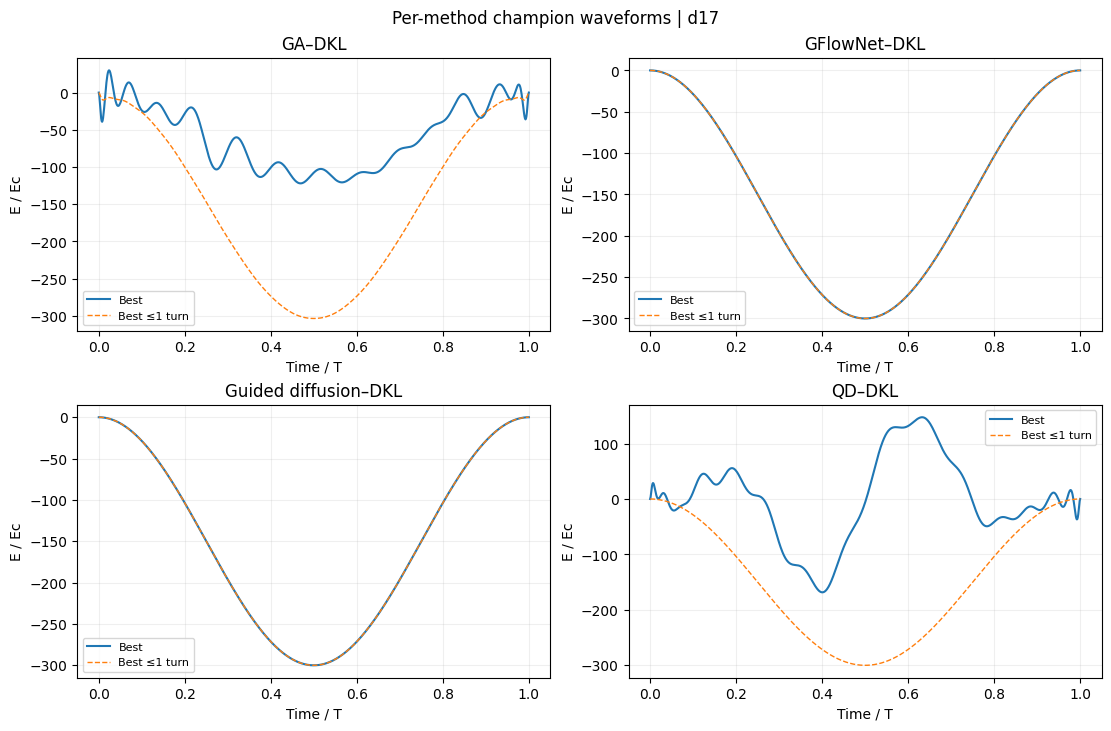

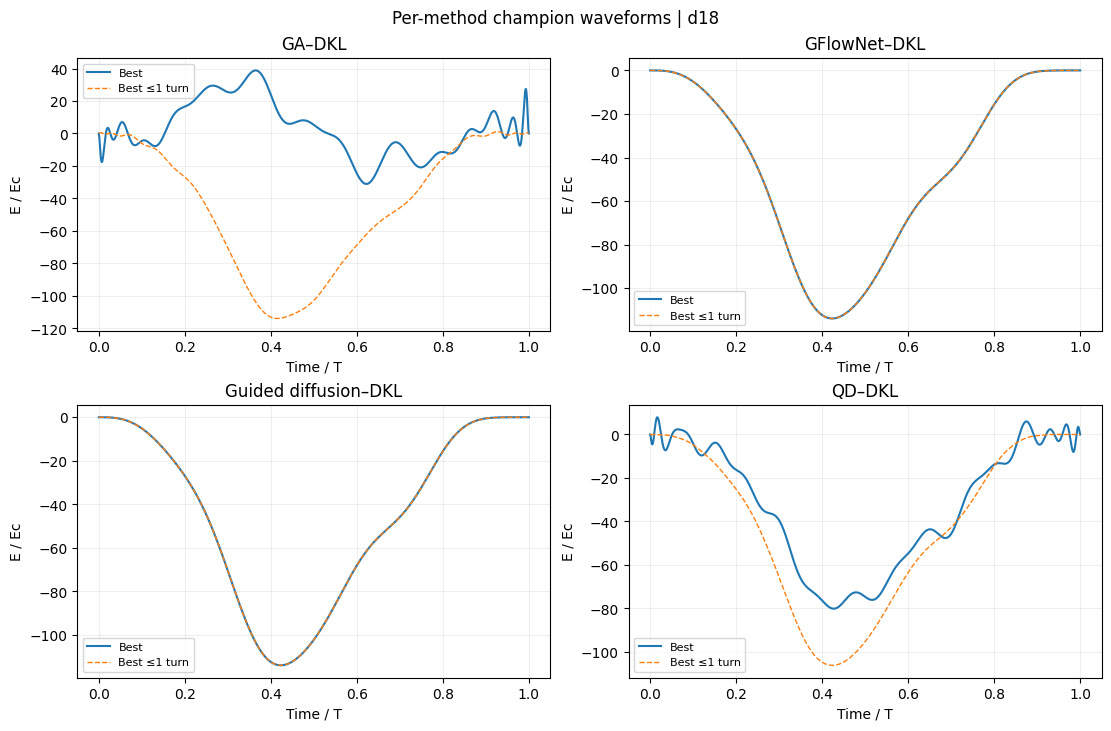

Per-disorder control figures generated.


In [52]:
plot_best_waveforms_by_disorder(df,MAPS,FIG_DIR,TABLE_DIR,all_maps=ANALYZE_EACH_DISORDER)
print('Per-disorder control figures generated.')

## 13. Complete disorder-by-disorder reward–complexity Pareto fronts

For each map plot all four optimizers in a 2×2 layout, separating measured points from the observed Pareto front. Export per-map non-dominated solution identifiers so the controls can be reconstructed and compared across disorder.

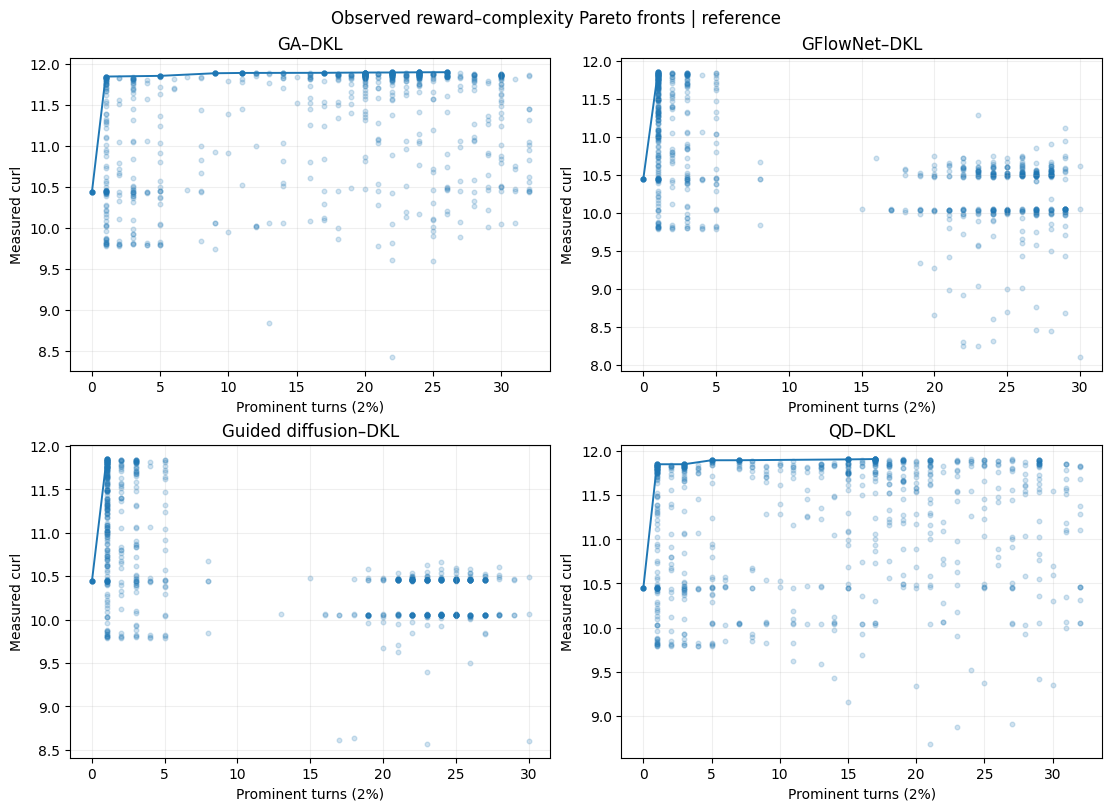

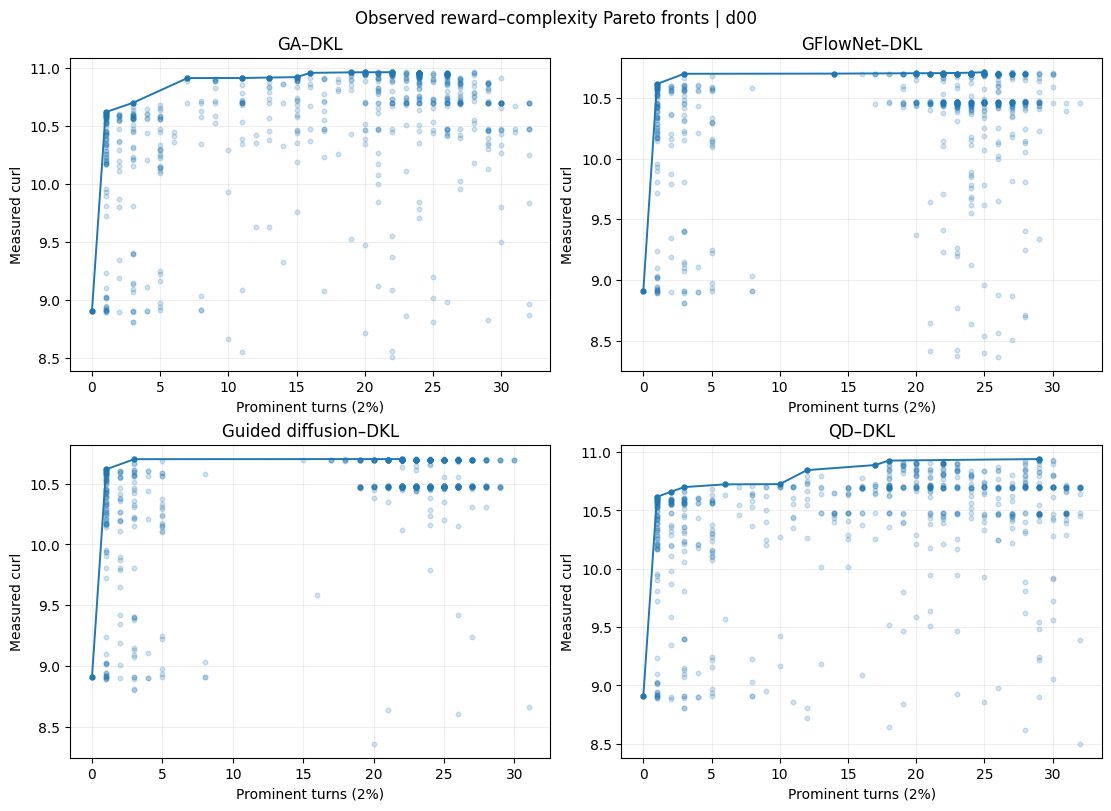

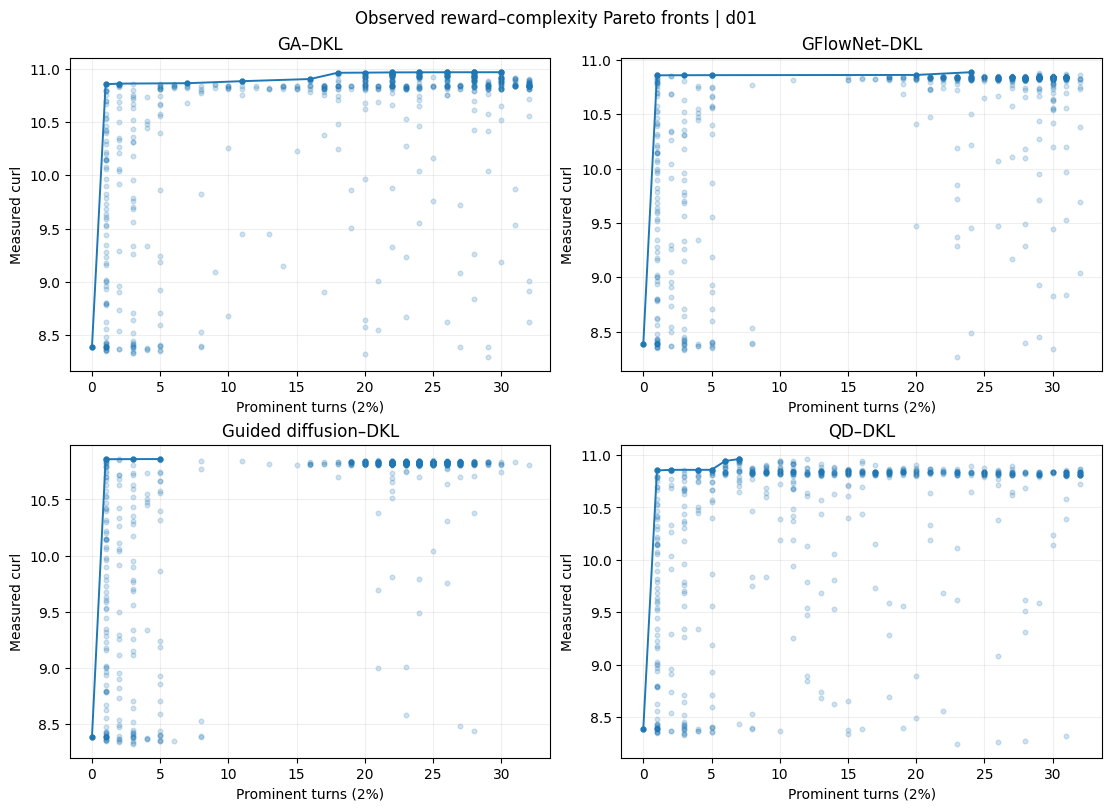

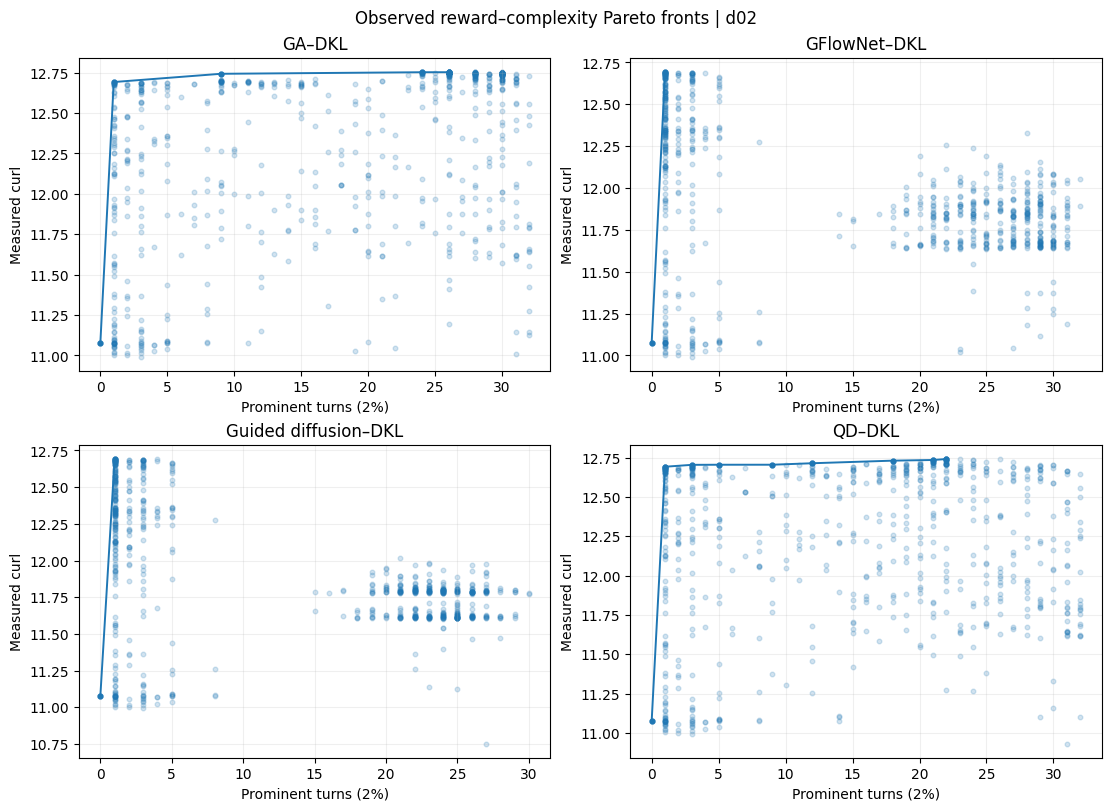

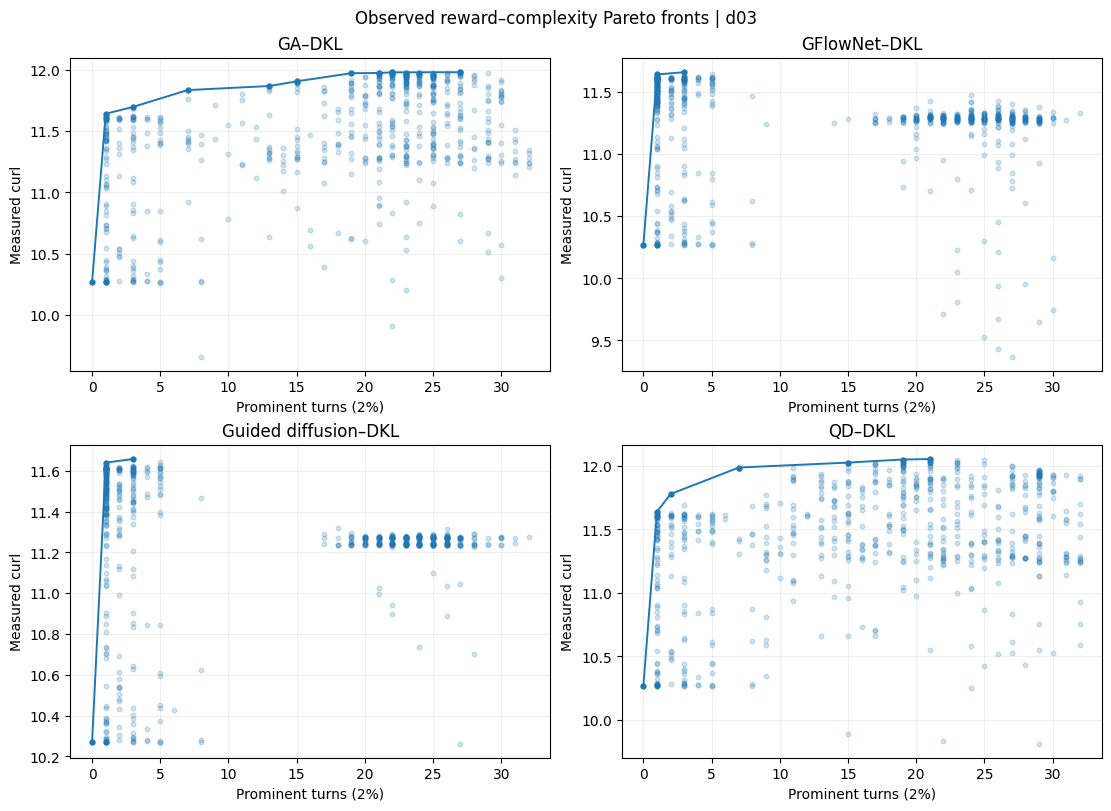

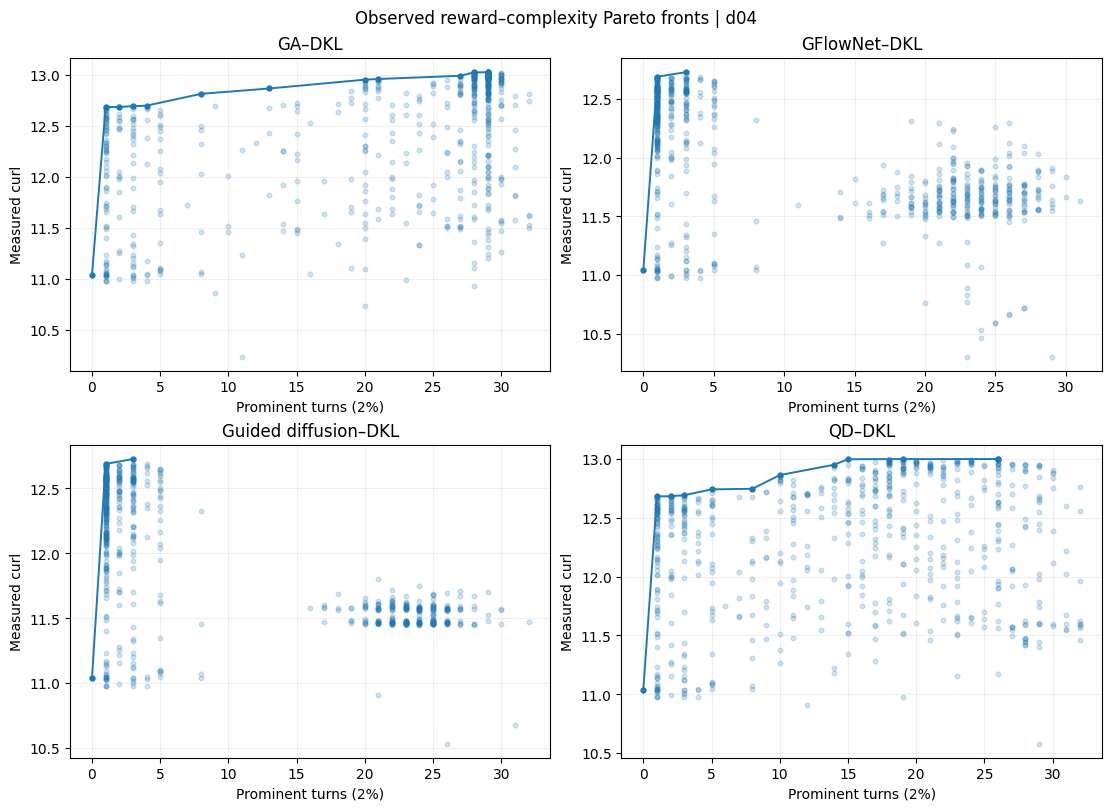

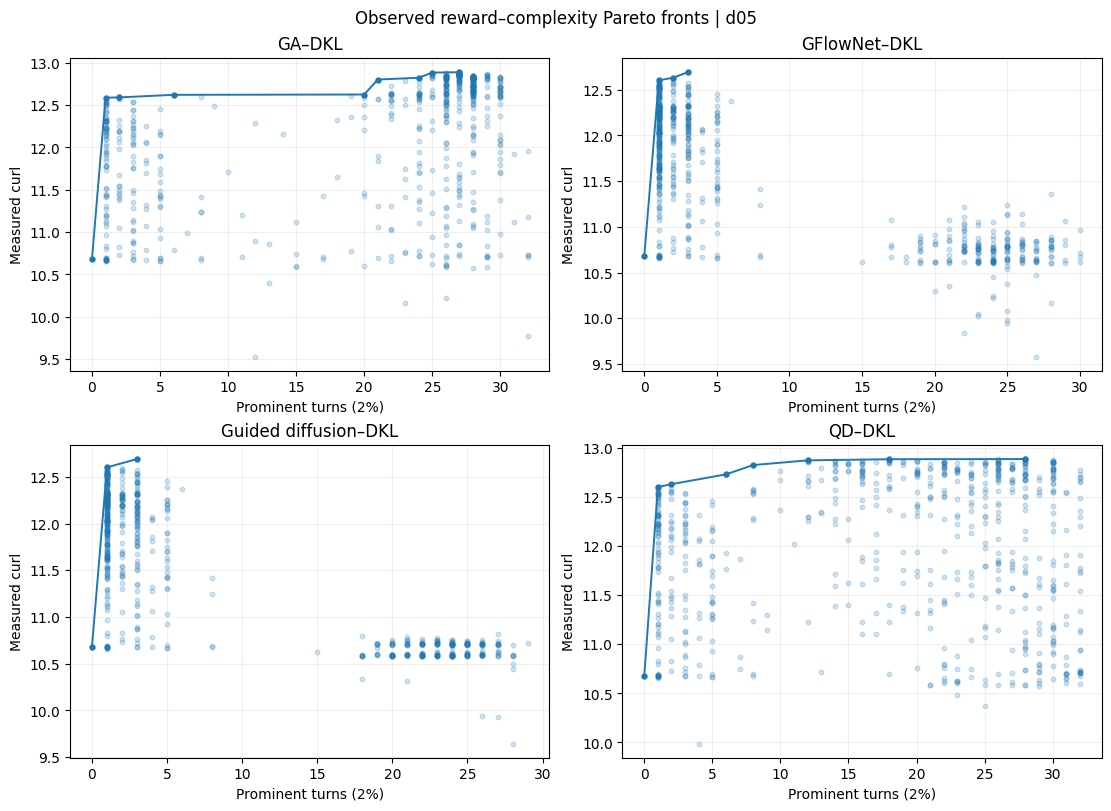

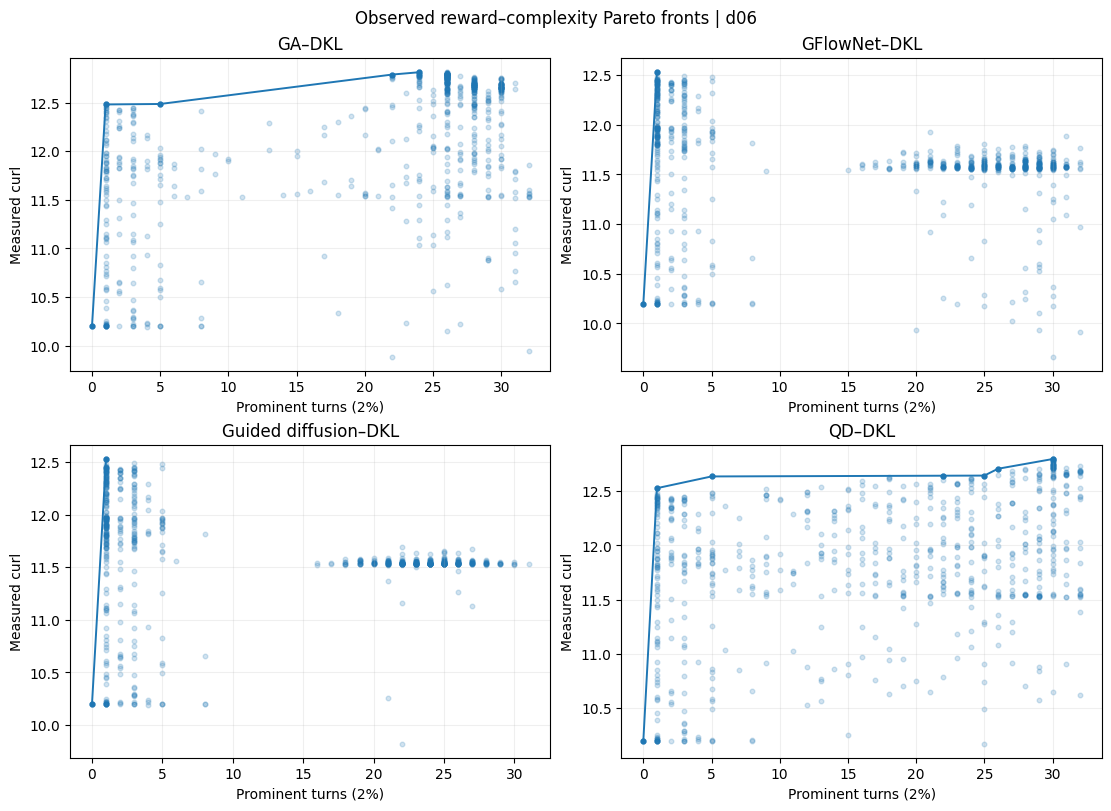

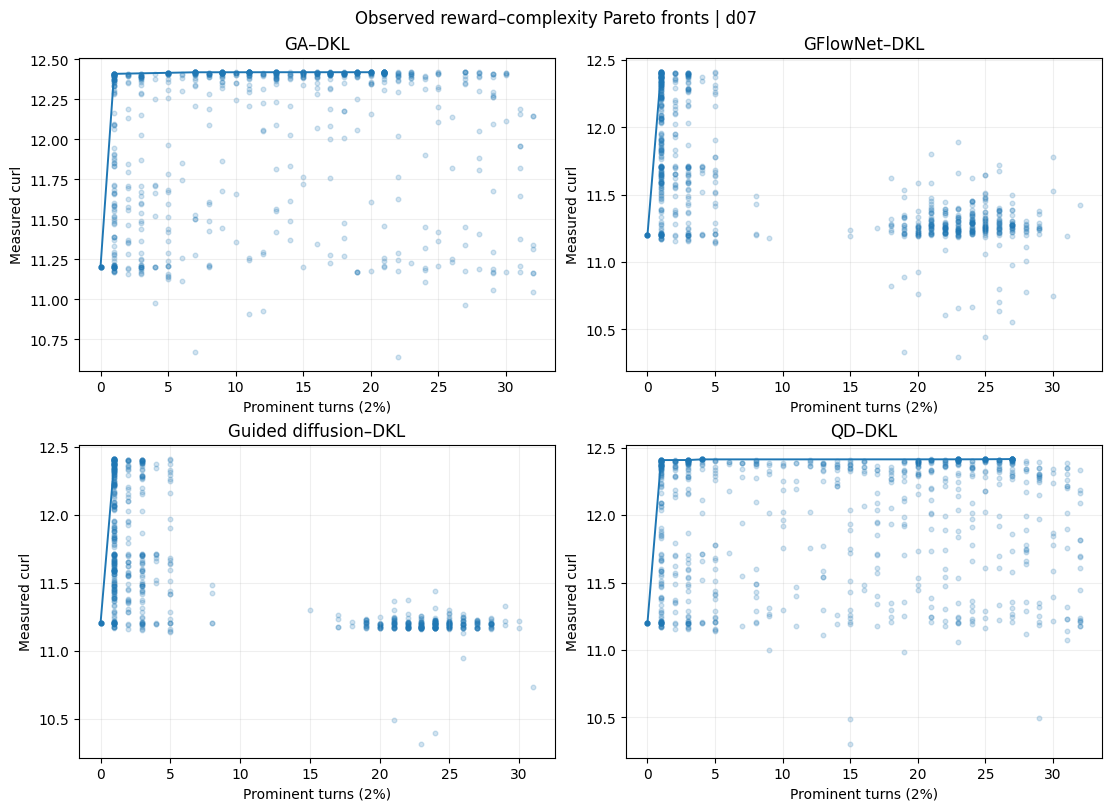

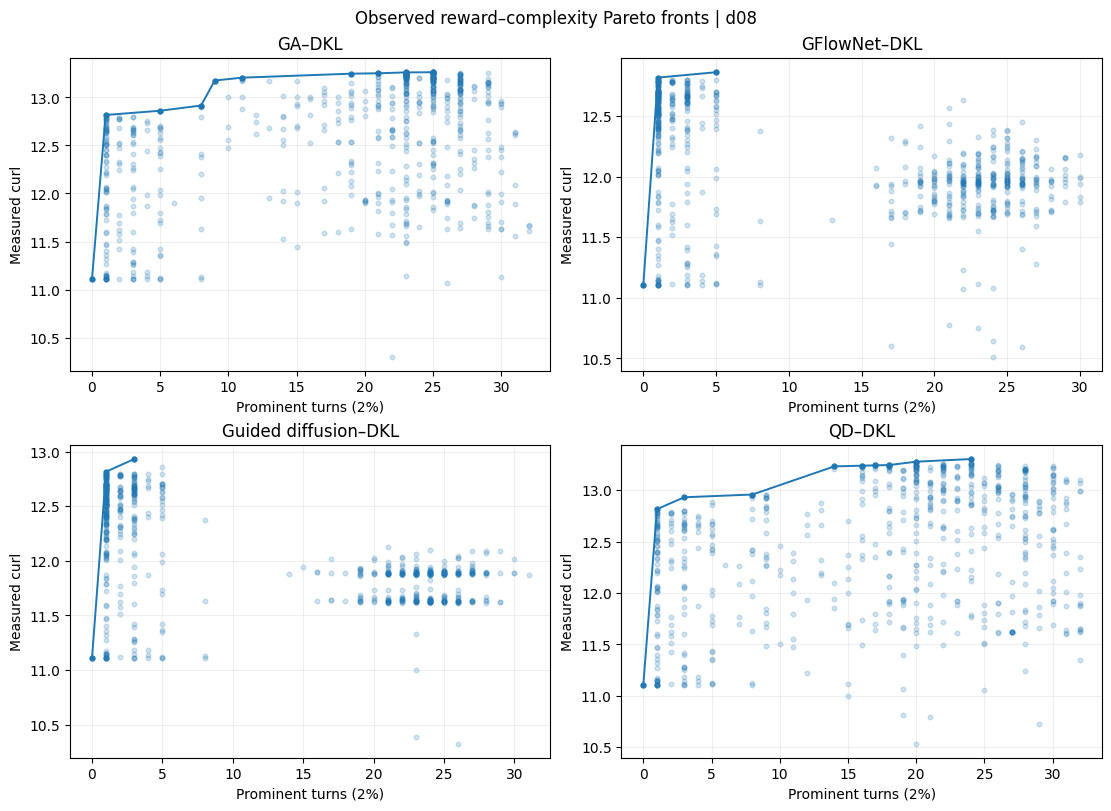

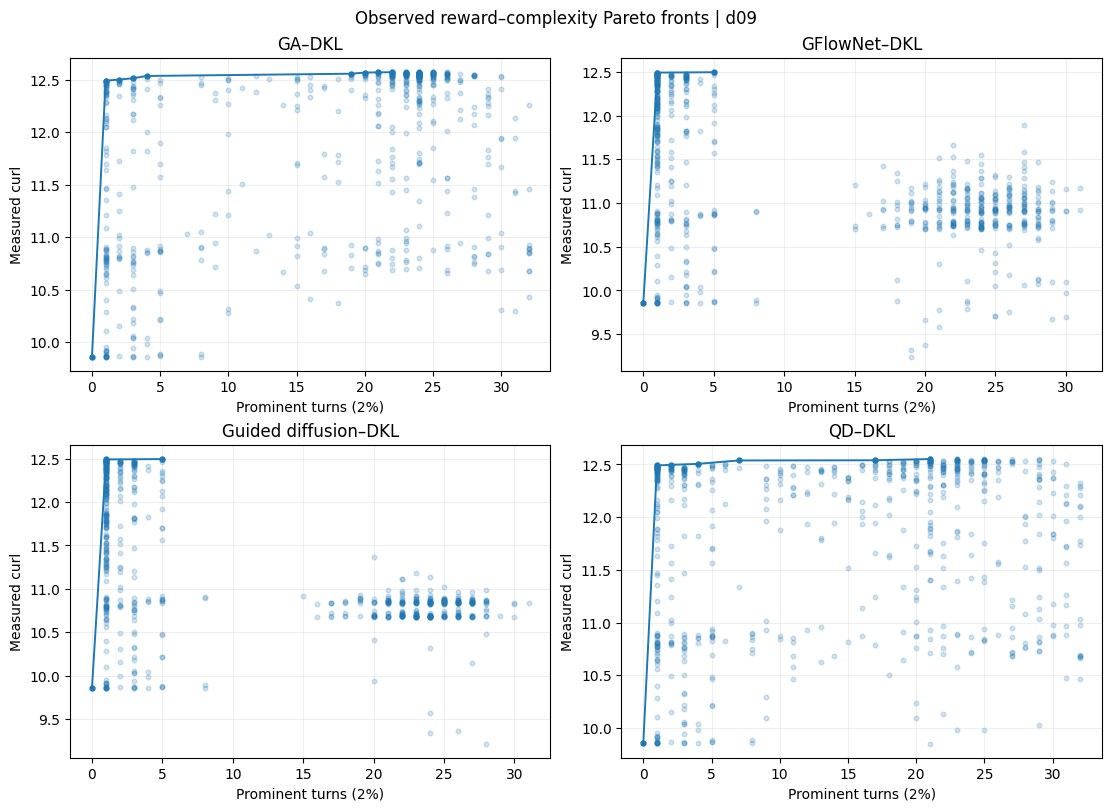

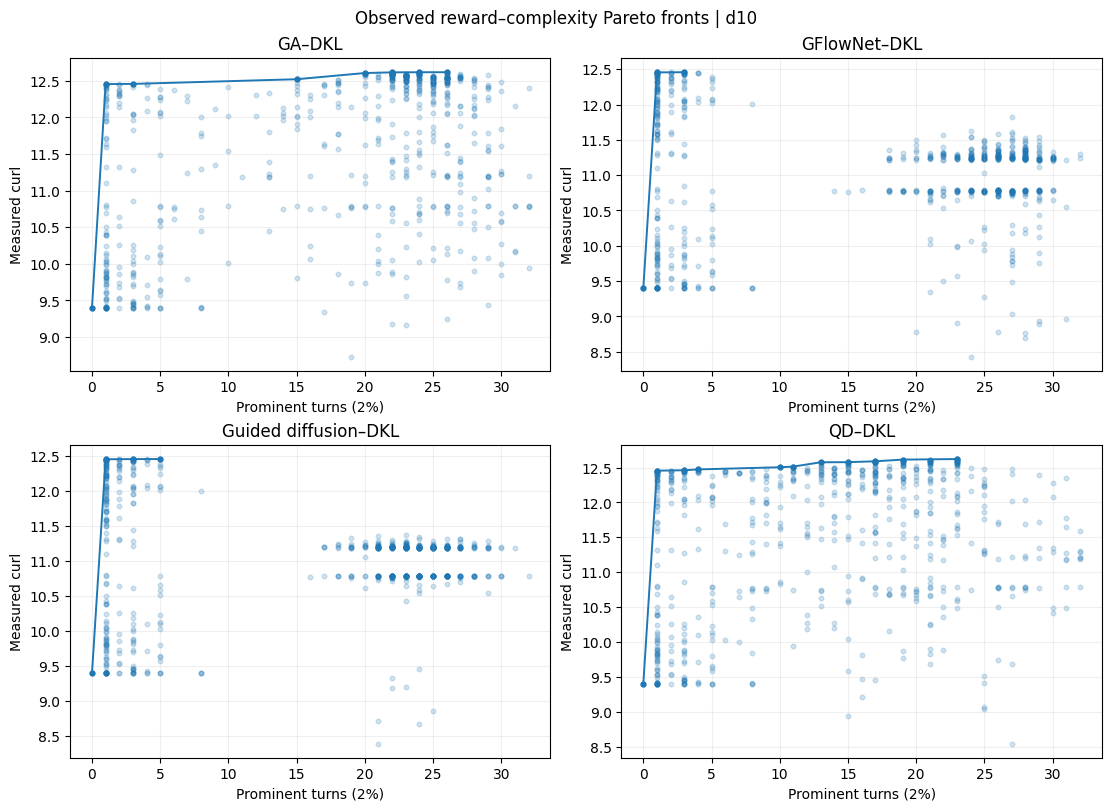

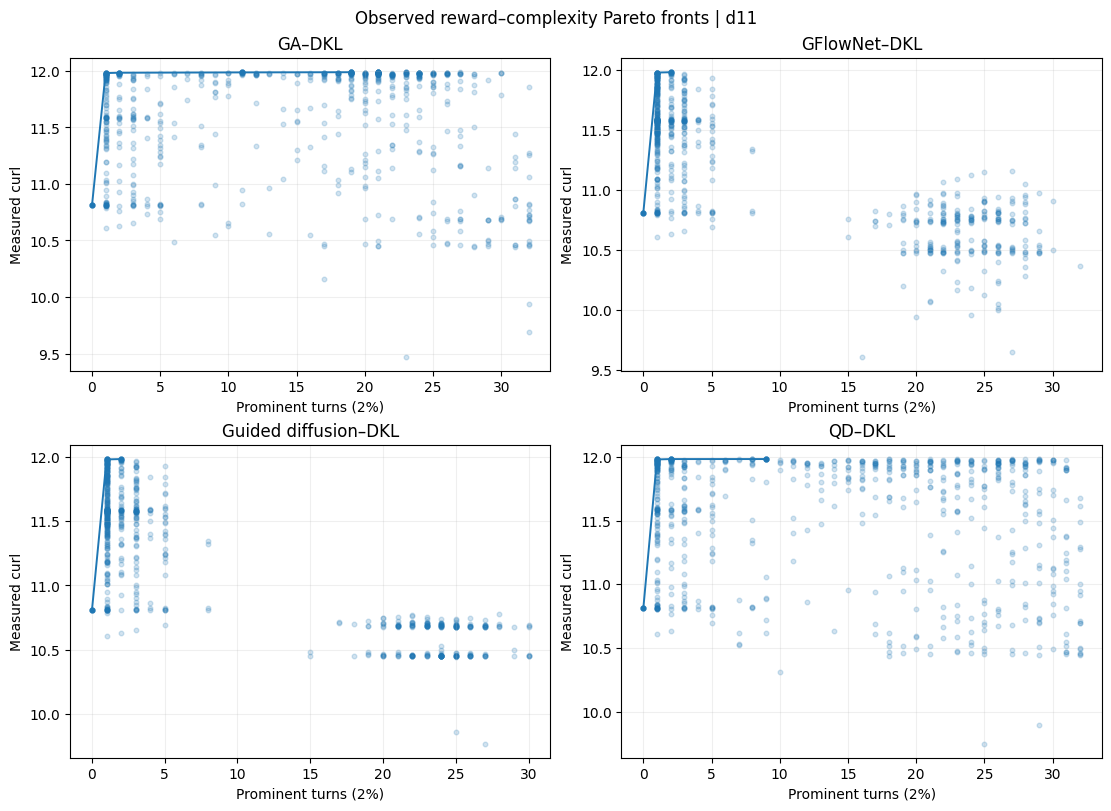

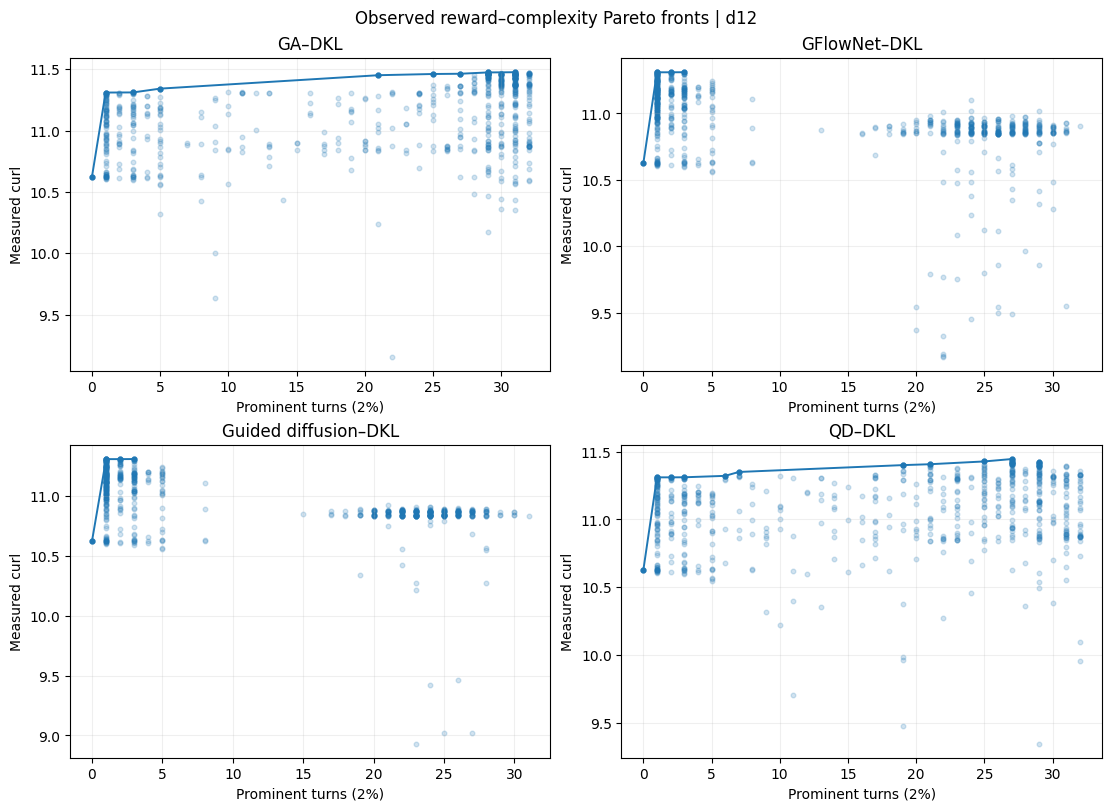

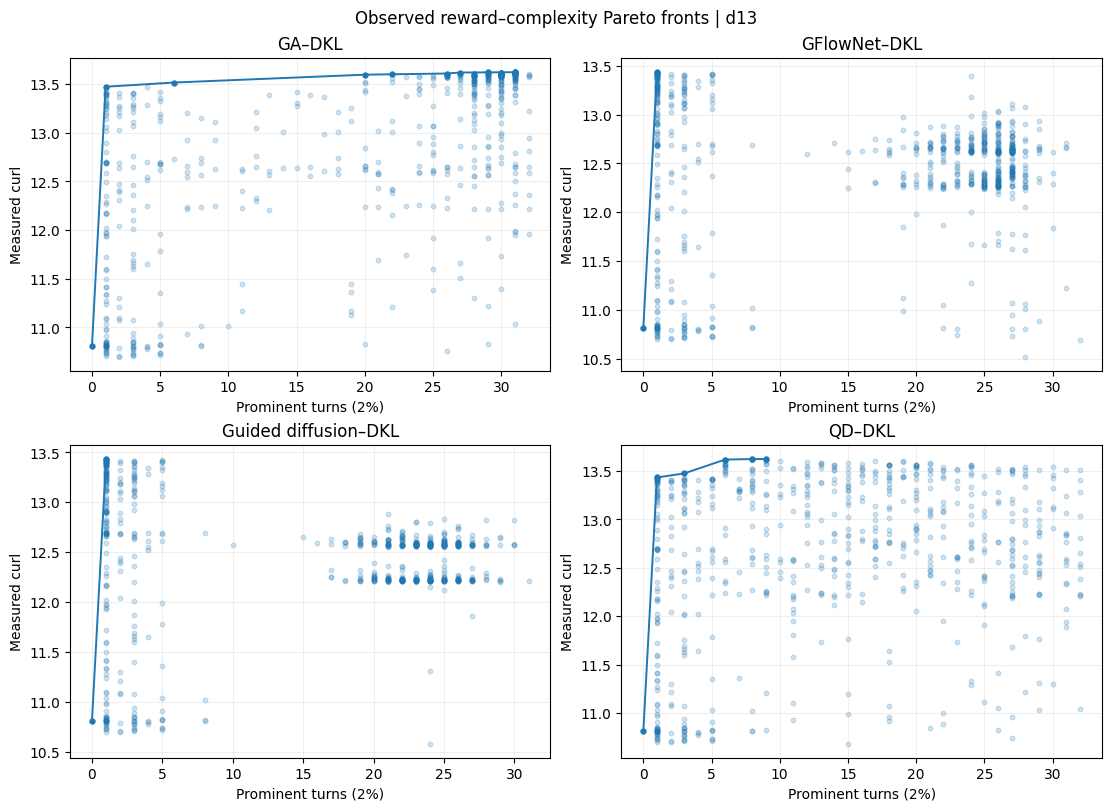

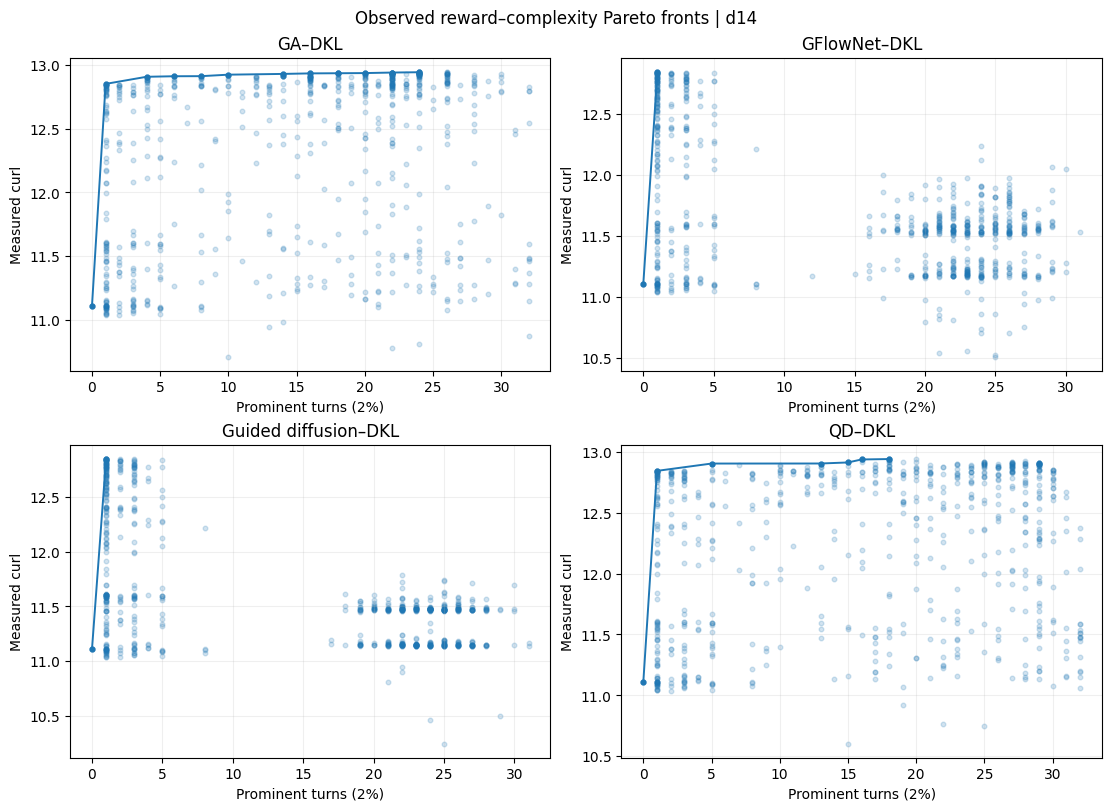

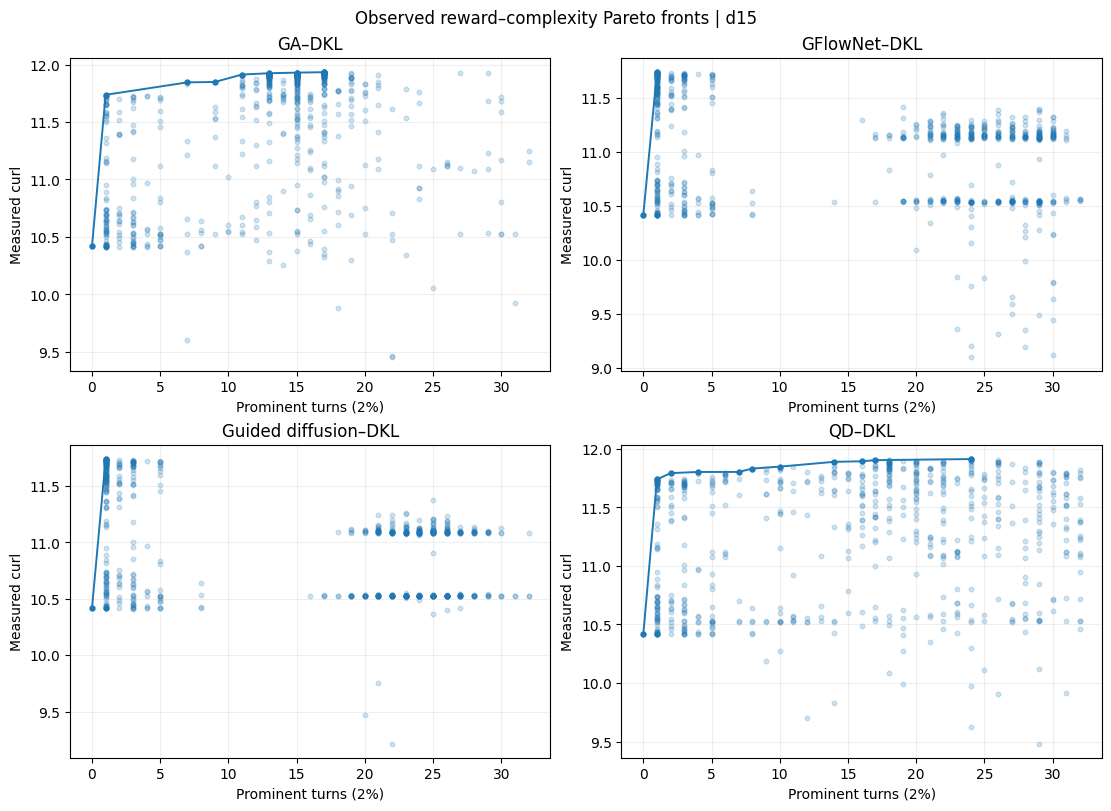

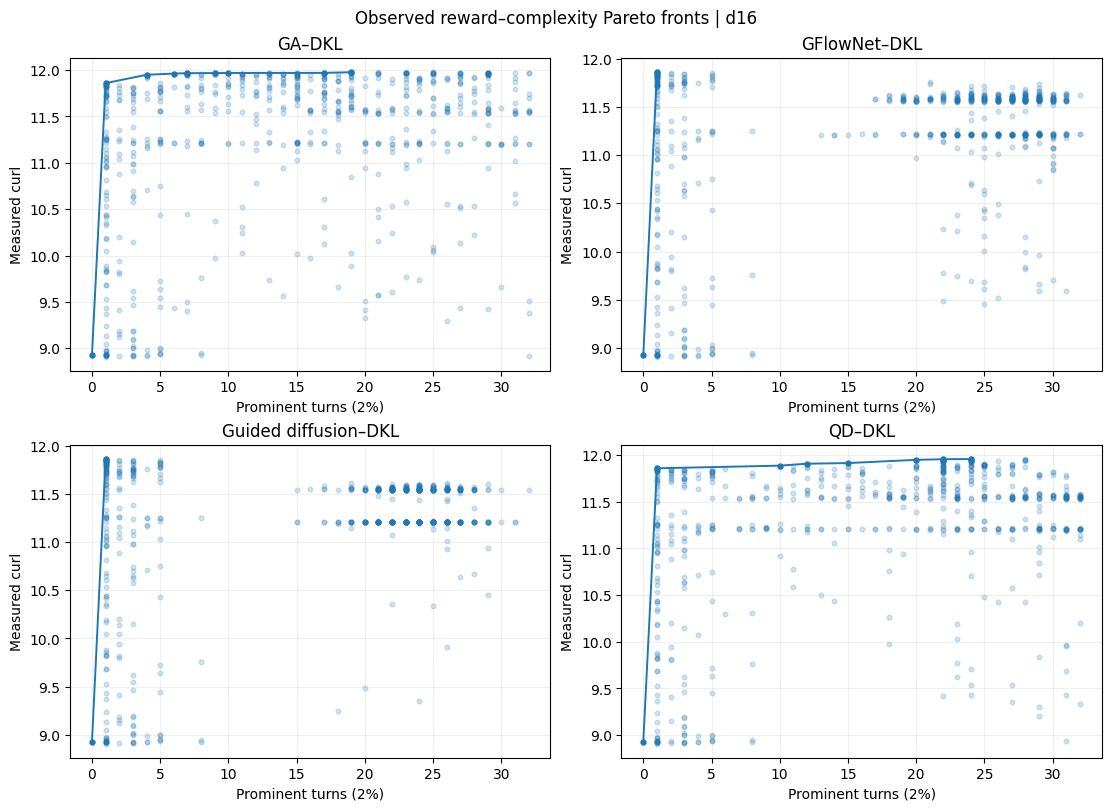

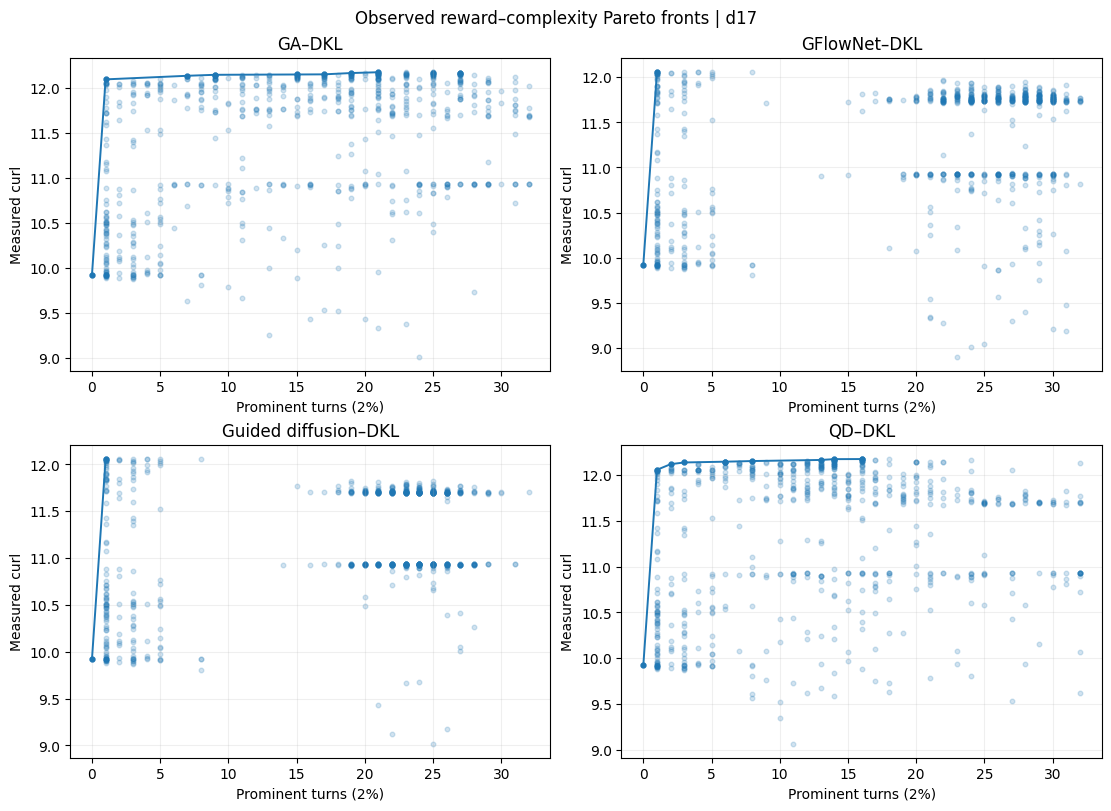

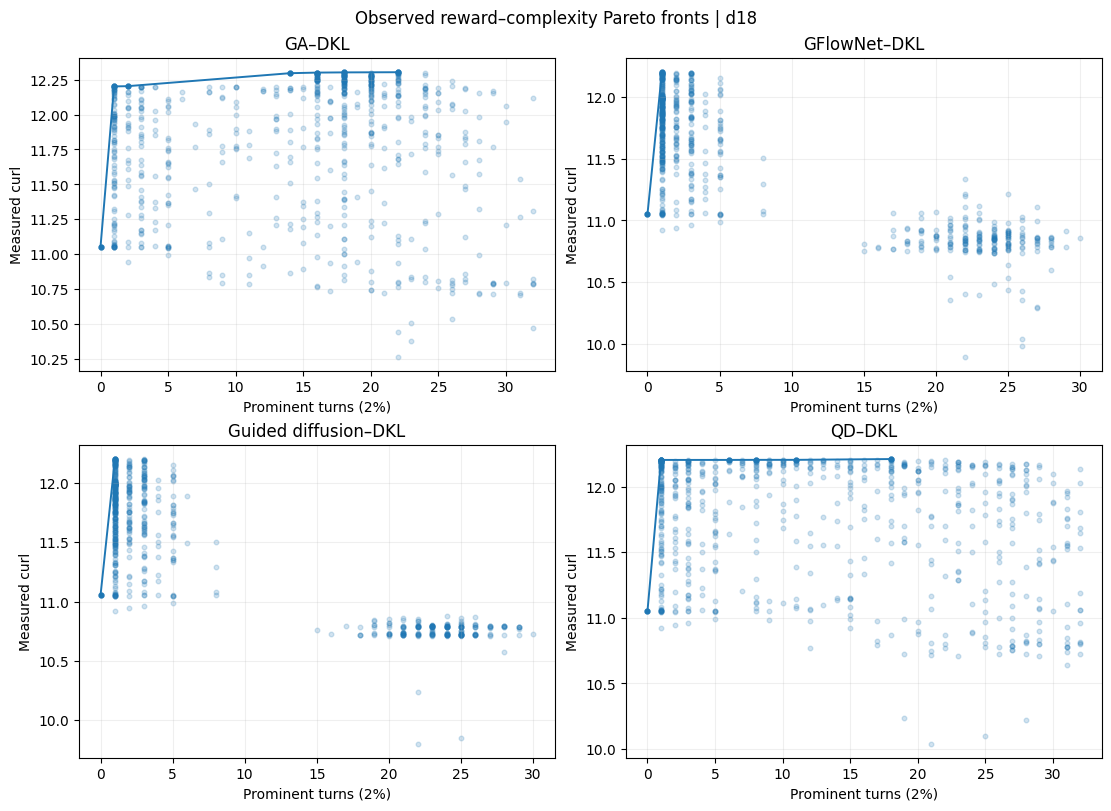

In [53]:
plot_pareto_by_disorder(df,MAPS,FIG_DIR,TABLE_DIR,all_maps=ANALYZE_EACH_DISORDER)

## 14. Complexity-reward retention and physical complexity ablations

Determine the best controls with **0, 1, and 3 resolved turns**, and the minimum turns required to retain **95% or 99% of the achieved gain relative to initialization**. Cross-check complexity by raw turns, total variation, peak field, and spatial boundary fraction, not just the number of resolved reversals.

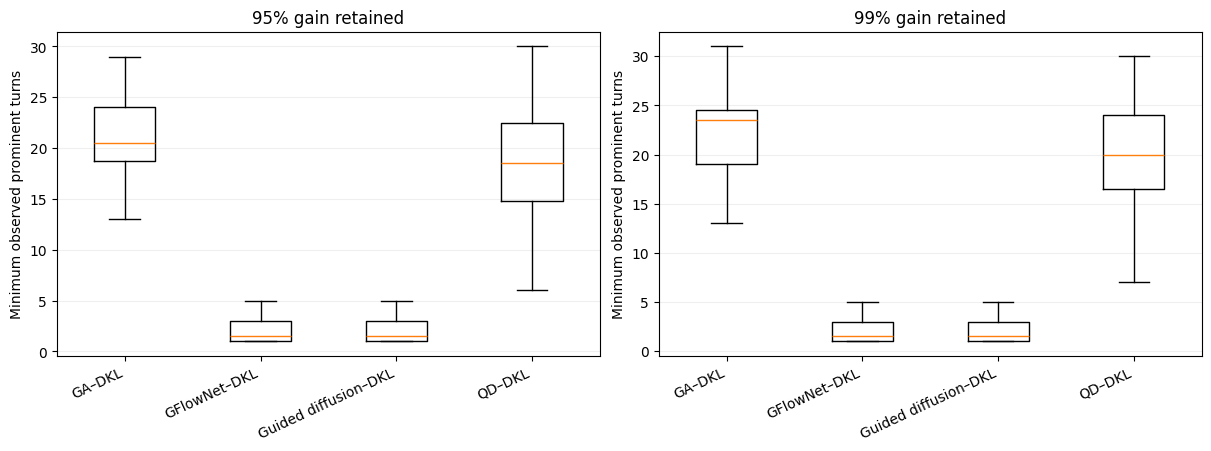

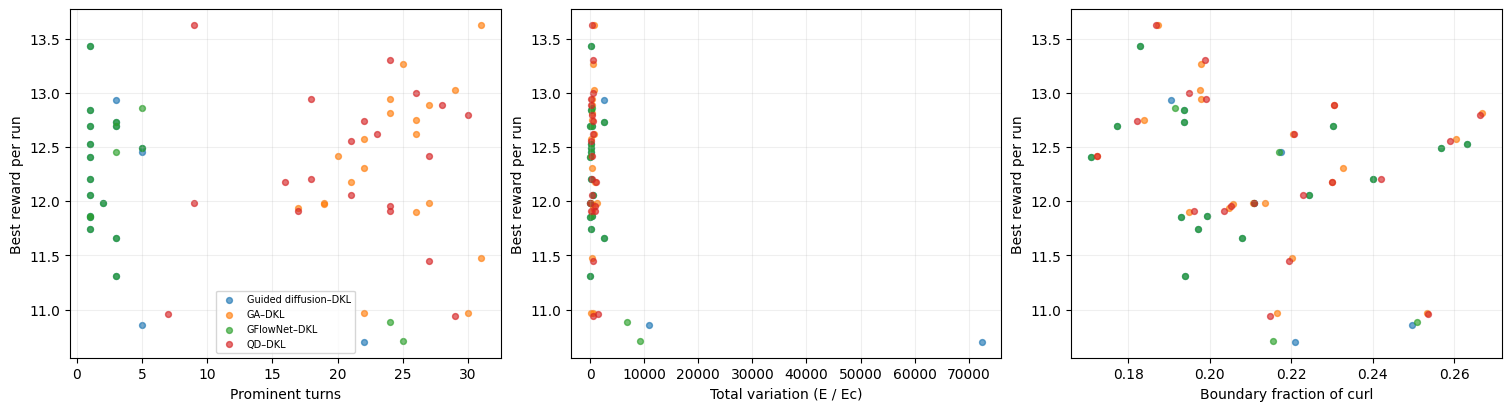

,map,seed,method,criterion,best_reward,unrestricted_reward,baseline,resolved_turns
0,d00,0,diffusion_dkl,≤0 turns,8.907669,10.701385,10.61641,0
1,d00,0,diffusion_dkl,≤1 turns,10.616410,10.701385,10.61641,1
2,d00,0,diffusion_dkl,≤3 turns,10.700347,10.701385,10.61641,3
3,d00,0,diffusion_dkl,95% gain retained,10.700347,10.701385,10.61641,3
4,d00,0,diffusion_dkl,99% gain retained,10.701385,10.701385,10.61641,22
5,d00,0,ga_dkl,≤0 turns,8.907669,10.964489,10.61641,0
6,d00,0,ga_dkl,≤1 turns,10.619723,10.964489,10.61641,1
7,d00,0,ga_dkl,≤3 turns,10.700347,10.964489,10.61641,3
8,d00,0,ga_dkl,95% gain retained,10.959077,10.964489,10.61641,16
9,d00,0,ga_dkl,99% gain retained,10.962260,10.964489,10.61641,19


,map,method,seed,reward,interior_reward,boundary_contribution,boundary_fraction,peak_ec,total_variation_ec,max_step_ec,turns_2pct,raw_turns
0,d00,diffusion_dkl,0,10.701385,8.338585,2.362799,0.220794,5924.303970,72369.101905,1342.507605,22,28
1,d00,ga_dkl,0,10.964489,8.591957,2.372531,0.216383,20.609564,211.595147,4.529964,22,26
2,d00,gflownet_dkl,0,10.713248,8.405416,2.307833,0.215419,378.236671,9229.002554,86.350175,25,27
3,d00,qd_dkl,0,10.940540,8.591310,2.349231,0.214727,24.826490,499.474375,5.022168,29,29
4,d01,diffusion_dkl,0,10.858839,8.149205,2.709634,0.249533,4838.320882,10853.791053,28.650221,5,5
5,d01,ga_dkl,0,10.965819,8.189504,2.776315,0.253179,44.157372,591.107454,11.767004,30,32
6,d01,gflownet_dkl,0,10.885829,8.154904,2.730925,0.250870,418.754562,6911.855826,52.169108,24,24
7,d01,qd_dkl,0,10.961710,8.182970,2.778740,0.253495,280.022717,1552.345563,9.644564,7,11
8,d02,diffusion_dkl,0,12.691362,10.441969,2.249393,0.177238,28.546045,57.092089,0.167037,1,1
9,d02,ga_dkl,0,12.752103,10.409077,2.343026,0.183736,27.048828,366.995280,6.025318,26,26


In [54]:
retention=complexity_retention(df,FIG_DIR,TABLE_DIR)
physical_metrics=plot_additional_complexity_metrics(df,FIG_DIR,TABLE_DIR)
display(retention.head(16));display(physical_metrics.head(12))

## 15. Seed/disorder variance, proposer attribution, and DKL calibration

Separate within-map seed dispersion from between-map dispersion when enough runs exist. Report `NaN` rather than fictitious variance for a single seed/map. Inspect selection source, candidate provenance, and the correspondence between DKL predicted mean/uncertainty and subsequent **measured RK4 reward**, excluding initial observations where no prediction exists.

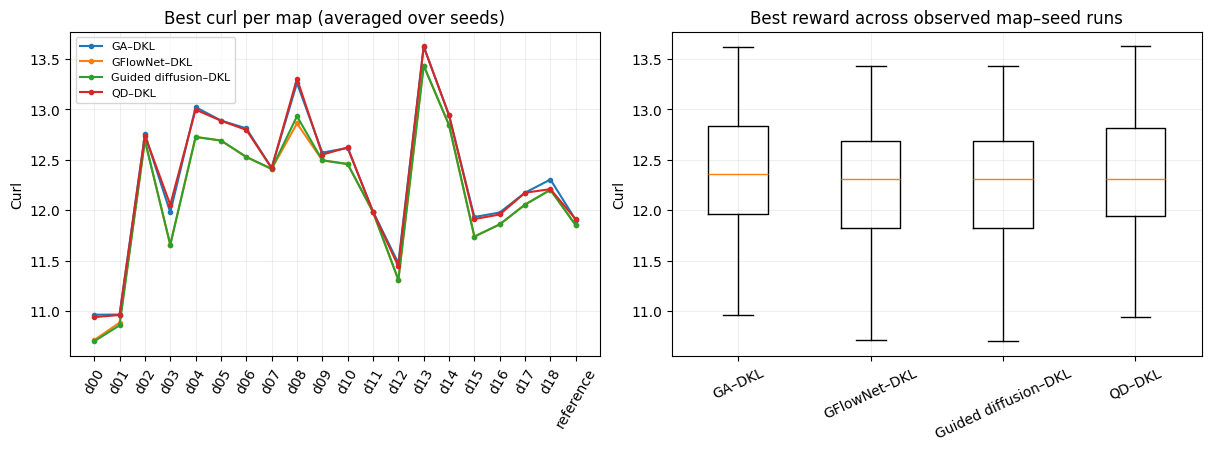

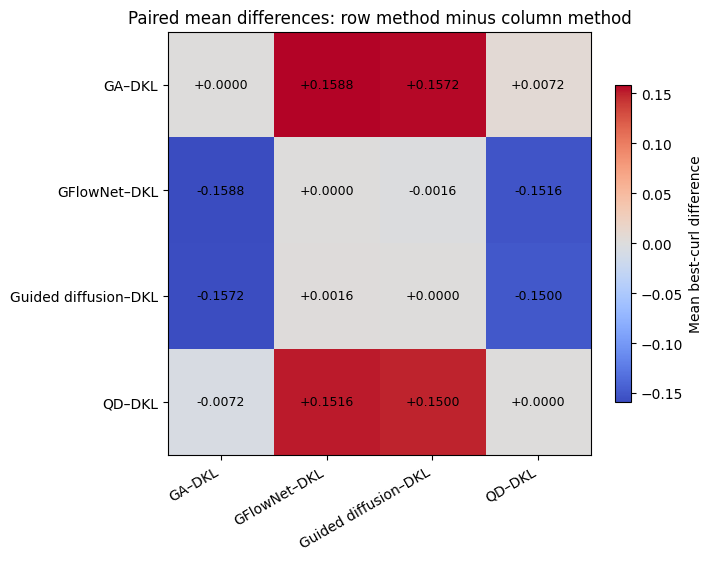

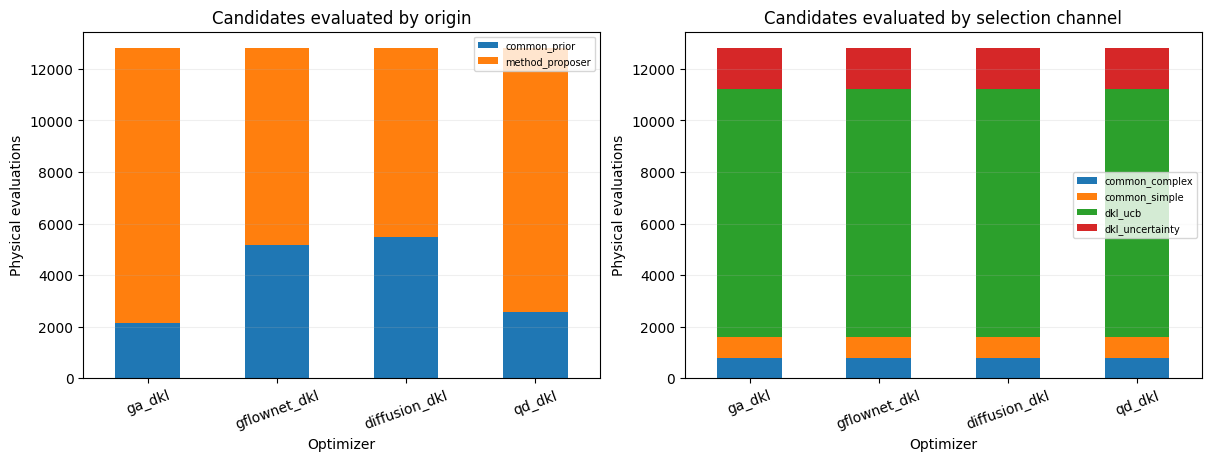

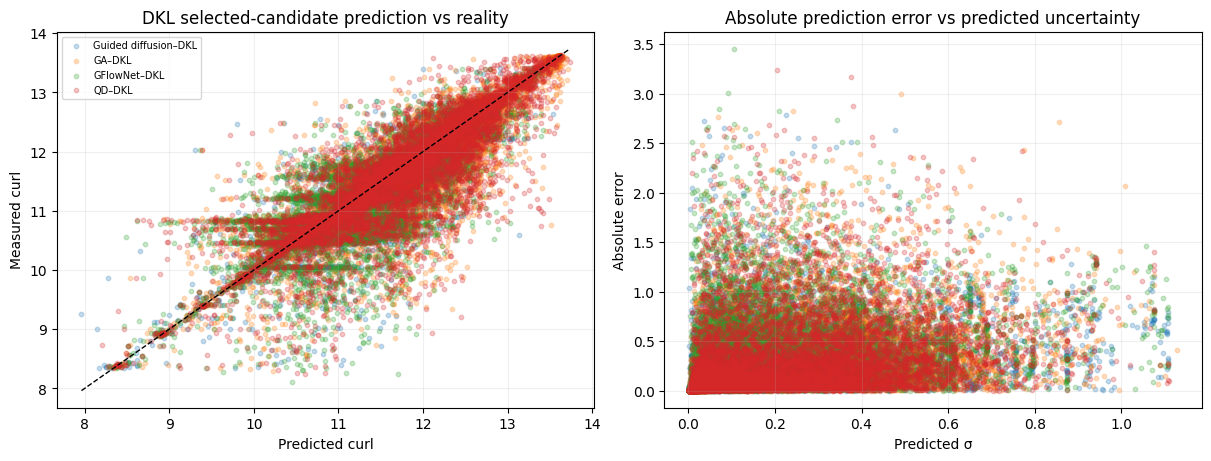

,method,maps,seeds_per_map,mean_best_curl,between_map_variance_of_seed_means,mean_within_map_seed_variance,single_map_or_seed_warning
0,diffusion_dkl,20,1,12.171510,0.482560,NaN,True
1,ga_dkl,20,1,12.328702,0.497289,NaN,True
2,gflownet_dkl,20,1,12.169867,0.471581,NaN,True
3,qd_dkl,20,1,12.321514,0.504770,NaN,True


,method_a,method_b,paired_map_seed_runs,mean_difference_a_minus_b,median_difference,a_wins,ties,b_wins,bootstrap_CI95_low,bootstrap_CI95_high,CI_valid,interpretation
0,ga_dkl,gflownet_dkl,20,0.158835,0.138635,20,0,0,0.115382,0.203861,True,Descriptive paired bootstrap over observed map...
1,ga_dkl,diffusion_dkl,20,0.157192,0.138457,20,0,0,0.114834,0.198254,True,Descriptive paired bootstrap over observed map...
2,ga_dkl,qd_dkl,20,0.007188,0.004296,15,0,5,-0.005372,0.020017,True,Descriptive paired bootstrap over observed map...
3,gflownet_dkl,diffusion_dkl,20,-0.001644,0.000000,2,16,2,-0.009374,0.004058,True,Descriptive paired bootstrap over observed map...
4,gflownet_dkl,qd_dkl,20,-0.151648,-0.125921,0,0,20,-0.207099,-0.100059,True,Descriptive paired bootstrap over observed map...
5,diffusion_dkl,qd_dkl,20,-0.150004,-0.125921,0,0,20,-0.202145,-0.106261,True,Descriptive paired bootstrap over observed map...


,method,n,mean_error,rmse,mae,inside_1_sigma,inside_2_sigma
0,diffusion_dkl,12800,-0.087144,0.345994,0.202604,0.423672,0.648203
1,ga_dkl,12796,-0.062250,0.389313,0.204325,0.474523,0.710847
2,gflownet_dkl,12800,-0.083820,0.429551,0.247699,0.402578,0.627031
3,qd_dkl,12795,-0.077257,0.434672,0.248157,0.474717,0.700195


,method,selection_source,proposal_source,evaluations,valid,best_reward,mean_reward
0,diffusion_dkl,common_complex,common_prior,800,800,13.414033,10.998566
1,diffusion_dkl,common_simple,common_prior,800,800,13.394774,11.137398
2,diffusion_dkl,dkl_ucb,common_prior,3700,3700,13.433670,11.968181
3,diffusion_dkl,dkl_ucb,method_proposer,5900,5900,12.882796,11.149010
4,diffusion_dkl,dkl_uncertainty,common_prior,165,165,13.064741,10.568099
5,diffusion_dkl,dkl_uncertainty,method_proposer,1435,1435,12.804750,11.108366
6,diffusion_dkl,shared_initial,initial_design,1280,1280,13.426716,11.050607
7,ga_dkl,common_complex,common_prior,800,800,13.414033,10.998566
8,ga_dkl,common_simple,common_prior,800,800,13.394774,11.137398
9,ga_dkl,dkl_ucb,common_prior,410,410,13.416385,11.935711


In [55]:
winners,variance=seed_disorder_variance(df,FIG_DIR,TABLE_DIR)
paired=paired_method_comparison(winners,FIG_DIR,TABLE_DIR)
provenance=proposal_attribution(df,FIG_DIR,TABLE_DIR)
calibration=surrogate_calibration(df,FIG_DIR,TABLE_DIR)
display(variance);display(paired);display(calibration);display(provenance.head(20))

## 16. Cross-disorder transfer (optional; outside optimizer budget)

For each source disorder, transfer the best and simple controls to other target maps **without reoptimization**. Report both raw RK4 curl and target-normalized gain relative to the target's best shared initialization. The normalized score can legitimately be negative or greater than 1; do not clip it. Transfer costs N_source × N_target × number of selected controls, so disable it for very short debugging runs if needed.

,source,target,kind,curl,valid,normalized_gain
0,d00,reference,best,10.280840,True,-26.647321
1,d00,d00,best,10.964489,True,1.000000
2,d00,d01,best,10.340886,True,-4.841568
3,d00,d02,best,12.122828,True,-8.783877
4,d00,d03,best,12.041999,True,0.970121
5,d00,d04,best,12.968395,True,0.841676
6,d00,d05,best,12.627867,True,0.121148
7,d00,d06,best,12.830135,True,1.049745
8,d00,d07,best,11.615874,True,-78.307309
9,d00,d08,best,13.277968,True,0.946645


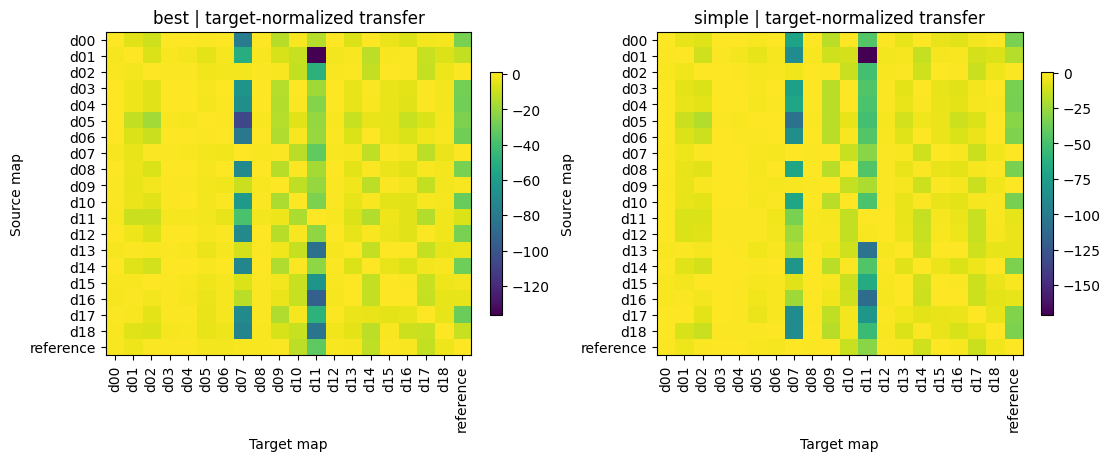

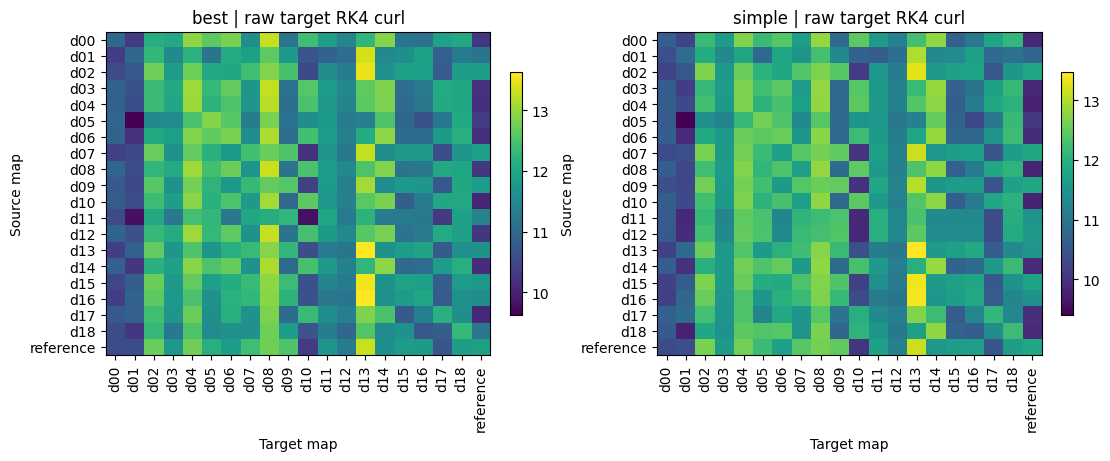

In [56]:
transfer=[]
if RUN_CROSS_DISORDER_TRANSFER:
    from oracle import evaluate_fields
    for source,g in df[df.valid].groupby('map'):
        best=g.loc[g.reward.idxmax()]
        simple_candidates=g[g.complexity<=1]
        selected=[('best',best)]
        if len(simple_candidates):selected.append(('simple',simple_candidates.loc[simple_candidates.reward.idxmax()]))
        for kind,row in selected:
            w=fields(row.coefficients)
            for target in MAPS:
                physical=evaluate_fields(w,defects_ec=np.load(MAP_DIR/f'{target}.npy'),
                    method='rk4',fidelity=1,max_substeps=hyper['max_substeps'])
                y=float(physical['reward'][0]);valid=bool(physical['valid'][0] and not physical['native_guard_exceeded'][0])
                baseline=float(df[(df['map']==target)&(df.generation==0)&df.valid].reward.max())
                optimum=float(df[(df['map']==target)&df.valid].reward.max())
                transfer.append(dict(source=source,target=target,kind=kind,curl=y,valid=valid,
                    normalized_gain=((y-baseline)/(optimum-baseline) if optimum>baseline+1e-12 and valid else np.nan)))
    transfer_df=pd.DataFrame(transfer);transfer_df.to_csv(TABLE_DIR/'transfer.csv',index=False)
    display(transfer_df.head(20))
    if len(MAPS)>1:
        fig,axs=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
        for ax,kind in zip(axs,['best','simple']):
            pivot=transfer_df[transfer_df.kind==kind].pivot(index='source',columns='target',values='normalized_gain')
            image=ax.imshow(pivot,cmap='viridis',aspect='auto');ax.set(title=f'{kind} | target-normalized transfer',xlabel='Target map',ylabel='Source map');fig.colorbar(image,ax=ax,shrink=.75)
            ax.set_xticks(range(len(pivot.columns)),pivot.columns,rotation=90)
            ax.set_yticks(range(len(pivot.index)),pivot.index)
        fig.savefig(FIG_DIR/'07_transfer.png',dpi=150);plt.show();plt.close(fig)
        fig,axs=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
        for ax,kind in zip(axs,['best','simple']):
            pivot=transfer_df[transfer_df.kind==kind].pivot(index='source',columns='target',values='curl')
            image=ax.imshow(pivot,cmap='viridis',aspect='auto');ax.set(title=f'{kind} | raw target RK4 curl',xlabel='Target map',ylabel='Source map')
            ax.set_xticks(range(len(pivot.columns)),pivot.columns,rotation=90)
            ax.set_yticks(range(len(pivot.index)),pivot.index);fig.colorbar(image,ax=ax,shrink=.75)
        fig.savefig(FIG_DIR/'07_transfer_raw.png',dpi=150);plt.show();plt.close(fig)
    else:print('Single-map self-transfer check only; no cross-disorder generalization is defined.')
else: print('Transfer was disabled in configuration.')

## 17. Higher-fidelity RK4 and spatial validation (optional)

Independently reevaluate the reference champion and its best ≤1-turn counterpart at higher integration fidelity; optionally repeat for **every disorder map**. Report the total curl, interior/boundary contributions, polarization maps and solver validity. Small numerical differences must not be misrepresented as physical performance improvements.

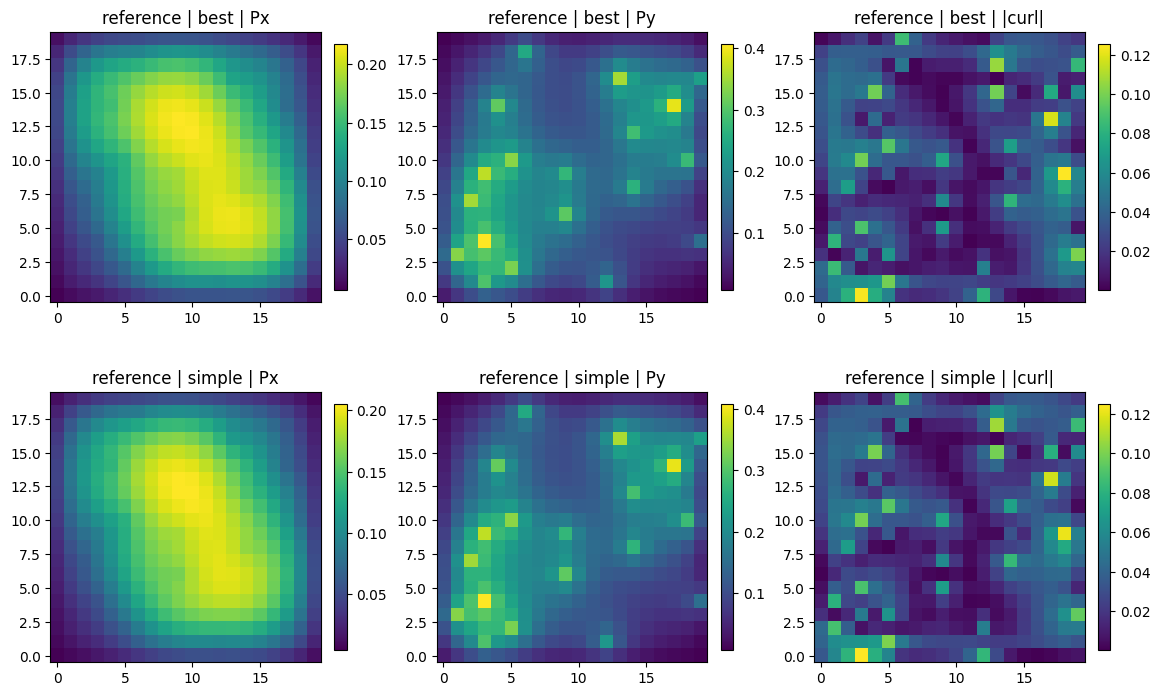

,map,kind,original_curl,validated_curl,delta,validated_interior_curl,validated_boundary_curl,valid,native_guard_exceeded
0,reference,best,11.909644,11.909644,1.037037e-09,9.573866,2.335778,True,False
1,reference,simple,11.850731,11.850731,8.668444e-11,9.564213,2.286517,True,False


In [57]:
if RUN_HIGHER_FIDELITY_VALIDATION:
    selected_maps=MAPS if VALIDATE_ALL_DISORDERS else ['reference']
    checks=[]
    for mid in selected_maps:
        mdf=df[(df['map']==mid)&df.valid]
        champ_mid=mdf.loc[mdf.reward.idxmax()]
        simple_candidates=mdf[mdf.complexity<=1]
        simple_mid=simple_candidates.loc[simple_candidates.reward.idxmax()] if len(simple_candidates) else None
        candidates=[('best',champ_mid)]
        if simple_mid is not None and (simple_mid.name!=champ_mid.name):candidates.append(('simple',simple_mid))
        fig,axs=plt.subplots(len(candidates),3,figsize=(11.5,3.6*len(candidates)),squeeze=False,layout='constrained')
        for i,(name,row) in enumerate(candidates):
            r=evaluate_fields(fields(row.coefficients),defects_ec=np.load(MAP_DIR/f'{mid}.npy'),fidelity=2,method='rk4',
                max_substeps=max(hyper['max_substeps']*2,10000))
            terminal=r['final_P'][0];curl=np.abs(curl_field(terminal))
            val=float(r['reward'][0]);interior=float(r['interior'][0]);v=bool(r['valid'][0] and not r['native_guard_exceeded'][0])
            checks.append(dict(map=mid,kind=name,original_curl=float(row.reward),validated_curl=val,
                delta=val-float(row.reward),validated_interior_curl=interior,
                validated_boundary_curl=val-interior,valid=v,
                native_guard_exceeded=bool(r['native_guard_exceeded'][0])))
            for j,arr in enumerate([terminal[0],terminal[1],curl]):
                ax=axs[i,j];im=ax.imshow(arr,origin='lower');ax.set(title=f'{mid} | {name} | '+['Px','Py','|curl|'][j]);fig.colorbar(im,ax=ax,shrink=.7)
        fig.savefig(FIG_DIR/f'08_spatial_validation_{mid}.png',dpi=150);plt.show();plt.close(fig)
    checks=pd.DataFrame(checks);display(checks.head(25))
    checks.to_csv(TABLE_DIR/'higher_fidelity_validation.csv',index=False)
else:print('Higher-fidelity validation disabled.')

## 18. Archive measured data, selected trajectories, and analysis manifest

The output tree contains the exact restartable optimizer checkpoints and physical evaluation archives, all figures, per-disorder champion trajectories, Pareto tables, calibration data, variance decompositions and transfer results (when enabled). A manifest lists generated files. No data are synthesized if a run is absent.

In [58]:
from analysis import write_selected
write_selected(df,TABLE_DIR/'selected_controls')
(RUN_ROOT/'config.json').write_text(json.dumps(params | {'hyper':hyper,'maps':MAPS,
    'cross_disorder_transfer':RUN_CROSS_DISORDER_TRANSFER,
    'higher_fidelity_validation':RUN_HIGHER_FIDELITY_VALIDATION},indent=2))
export_index(FIG_DIR,TABLE_DIR,RUN_ROOT)
print('Run directory:',RUN_ROOT)
print('All figures:',len(list(FIG_DIR.rglob('*.png'))))
print('All tables:',len(list(TABLE_DIR.rglob('*.csv'))))

Saved 56 figures and 57 tables. Output index: /content/FerroSim_Legendre_Clean_v2/experiments/quick_20maps_1seeds_20gen_64initial_58ba56541c/output_manifest.json
Run directory: /content/FerroSim_Legendre_Clean_v2/experiments/quick_20maps_1seeds_20gen_64initial_58ba56541c
All figures: 56
All tables: 55
